## This copy: Dana's model with Henry's robot constants

Dana's original is `dana-models/RobotSimulationOpenLoopModel.ipynb` and is unchanged. This copy keeps her architecture, equations, and tests, and takes **every physical parameter from `robot_constants.py`**; nothing is invented here.

### Conventions (changed from Dana's text, agreed with Dana)

* **Axes (math quadrants):** body $+x_r$ right, $+y_r$ forward, $+z$ up. The world frame is $+X$ right, $+Y$ up, and at heading $\varphi = 0$ the robot faces $+Y$. Yaw is positive CCW.
* **Wheels:** angles $\beta_i$ are measured CCW from $+x_r$: 1 front-right $\alpha_f$ (quadrant I), 2 front-left $\pi-\alpha_f$ (II), 3 rear-left $\pi+\alpha_b$ (III), 4 rear-right $2\pi-\alpha_b$ (IV). That is exactly `rc.WHEEL_ALPHA_DEG`, so for Henry's robot $\alpha_f = 30^\circ$ and $\alpha_b = 45^\circ$.
* **Symbols:** $\dot\theta_i$ wheel speeds (`theta_dot`), $\varphi$ heading, $\omega$ yaw rate.

In this convention **Dana's $\mathbf H$ is correct as written**: its rows are the CCW tangents at $\beta_i$. Her original text and frame diagram described a different frame (x forward, y left, with the y-arrow drawn on the wrong side), and her normal-force split used that frame. The text, equations, and the layout figure (drawn from the parameters, so its angles are true) now all follow the code.

### Fixes (each marked `FIX` in the code, each with a switch, all default on; all off reproduces Dana's original)

1. **Normal forces** (`fix_normal_forces`). The original split did not satisfy the moment balances for this layout. The loads are now the rigid-chassis, equal-stiffness solution $N_i = c_0 + c_x x_i + c_y y_i$ (Purwin & D'Andrea's closure, generalised to unequal front and rear tracks). It satisfies $\sum N_i = M_r g$, $\sum N_i y_i = -M_r a_y h$ (pitch), and $\sum N_i x_i = -M_r a_x h$ (roll) exactly, using the previous step's acceleration. Wheel lift-off (`lift_off_resolve`): a load that would go negative is set to zero and the rest re-solved.
2. **World-frame velocity** (`fix_rotating_frame`). The original integrated the body-frame velocity as if the body axes did not turn, so a robot coasting while it spins drove a circle instead of a straight line. The chassis velocity is now integrated in the world frame, $\dot{\mathbf v}_g = R(\varphi)\,\mathbf a_r$, and the body-frame velocity that $\mathbf H$ needs is derived from it, $\mathbf v_r = R(\varphi)^\top \mathbf v_g$.
3. **Motor current integration** (`fix_exact_current`). With Henry's motor ($L/R = 0.55$ ms), forward Euler at 1 ms overshoots. The update is now the exact solution for a held voltage, stable for any $dt$.
4. **Motor saturation** (`motor_limits`, Dana's requirement). The driver limits the applied voltage to `MAX_MOTOR_VOLTAGE`, and to the voltage whose steady current is `IQ_LIMIT`.

### Added sections (after Dana's tests, each headed "➕ Added")

None of them changes Dana's model unless an option is switched on.

- **A.** Logging and diagnostic plots.
- **B.** Extra checks: timestep convergence, energy audit, per-wheel signs, braking chatter.
- **C.** The four fixes one at a time.
- **D.** Henry's model options in `OmniRobotSimulationExtended`, all defaulting to Dana's behaviour.

### Not changed in Dana's defaults (open questions)

- A slipping wheel re-sticks as soon as its requested force falls below $\mu_s N$, and its speed then snaps to the rolling speed. The sliding force takes the sign of the requested force, not of the slip velocity (Added D5 compares the alternatives).
- No roller (a-axis) friction.
- The wheel inertia is left out of the sticking force.
- The centre of mass is at the base centre (CAD puts it 10 mm forward).

## 🤖 Complete Plant Simulation Specification: Discrete-Time Open-Loop Asymmetric 4-Omni Robot Model

This cell specifies the comprehensive mathematical framework for the 4-wheel omni-directional mobile robot simulation. The architecture accounts for **asymmetric wheel layouts**, **dynamic multi-axis weight transfer (pitch and roll)**, **disturbances from real world system vibration and noise** and **non-linear stick-slip traction transitions** derived explicitly for digital execution at a fixed sampling interval $\Delta T$ (or $T_s$).

---
<details>
<summary><b> Open this for the full specification of the simulation equations</b></summary>

### 0. Conventions (math quadrants)

* **Body frame:** $+x_r$ to the right, $+y_r$ forward, $+z$ up. Yaw is positive counter-clockwise.
* **Wheels** sit on a circle of radius $R_b$ at angles $\beta_i$ measured CCW from $+x_r$: wheel 1 front-right (quadrant I), 2 front-left (II), 3 rear-left (III), 4 rear-right (IV):
$$\beta_1 = \alpha_f,\qquad \beta_2 = \pi - \alpha_f,\qquad \beta_3 = \pi + \alpha_b,\qquad \beta_4 = 2\pi - \alpha_b .$$
  Wheel $i$ is at $\mathbf r_i = R_b(\cos\beta_i, \sin\beta_i)$. Its drive direction is the CCW tangent $\hat{\mathbf d}_i = (-\sin\beta_i, \cos\beta_i)$, and its roller axis is the radial direction $\hat{\mathbf a}_i = (\cos\beta_i, \sin\beta_i)$.
* **Symbols:** $\dot\theta_i$ is the speed of wheel $i$, $\omega$ the chassis yaw rate, and $\varphi$ the heading. At $\varphi = 0$ the robot faces world $+Y$.

### 1. Parameters & Variable Definitions

#### 🛠️ Hardware & Structural Parameters
* $M_r$: Total mass of the robot chassis (kg)
* $J_{zz}$: Rotational mass moment of inertia of the robot around its vertical Z-axis (kg·m²)
* $J_w$: Rotational mass moment of inertia of an individual wheel/rotor assembly (kg·m²)
* $R_b$: Geometric radius of the robot base circle from the Center of Mass (meters)
* $r$: Operating radius of the omni-wheel tires (meters)
* $\alpha_f$: Angle of the front-right wheel above the $+x_r$ axis; the front-left wheel is its mirror at $\pi - \alpha_f$ (rad)
* $\alpha_b$: Angle of the rear-right wheel below the $+x_r$ axis; the rear-left wheel is its mirror at $\pi + \alpha_b$ (rad)
* $h$: Height of the robot Center of Mass (CoM) above the ground plane (meters)
* $R, L_m$: Armature resistance ($\Omega$) and inductance (H) of individual DC motors
* $K_t, K_b$: Electromechanical torque (Nm/A) and back-EMF (V/(rad/s)) constants
* $V_{\max}, I_{\max}$: Driver bus voltage (V) and current limit (A)
* $C_{rr}$: Floor-tire rolling resistance coefficient
* $\mu_s, \mu_k$: Static and kinetic coefficients of friction between tire rollers and floor

---

### 2. Signal Tracker Definitions

At each sample time step $k$, the discrete simulation cycle processes the following variables:

#### System Inputs
* $\mathbf{V}_k = [V_{1,k}, V_{2,k}, V_{3,k}, V_{4,k}]^\top$: Motor armature terminal voltage commands applied to each wheel (Volts).

#### Tracked Memory Integration States
* $\mathbf{I}_k = [i_{1,k}, i_{2,k}, i_{3,k}, i_{4,k}]^\top$: Motor armature current states (Amperes).
* $\dot{\boldsymbol\theta}_k = [\dot\theta_{1,k}, \dot\theta_{2,k}, \dot\theta_{3,k}, \dot\theta_{4,k}]^\top$: Mechanical wheel angular velocity states (rad/s).
* $\mathbf{\dot{X}}_{r,k} = [\dot{x}_{r,k}, \dot{y}_{r,k}, \omega_{k}]^\top$: Body-frame chassis velocities: right, forward, yaw rate (m/s, m/s, rad/s).
* $\mathbf{\ddot{X}}_{r,k-1} = [a_{x,r,k-1}, a_{y,r,k-1}, \alpha_{r,k-1}]^\top$: Body-frame chassis accelerations retained from the *previous* time step to decouple normal force weight transfer allocations (m/s², m/s², rad/s²).
* $\mathbf{\dot{X}}_{g,k} = [\dot{X}_{k}, \dot{Y}_{k}, \dot{\varphi}_{k}]^\top$: World (room) frame chassis velocities (m/s, m/s, rad/s).
* $\mathbf{X}_{g,k} = [X_k, Y_k, \varphi_k]^\top$: Absolute world frame position and heading (meters, meters, radians).

#### Plant Observation and Feedback Outputs (Algebraic Trackers)
* $\mathbf{T}_{m,k} = [T_{m,1,k}, T_{m,2,k}, T_{m,3,k}, T_{m,4,k}]^\top$: Instantaneous electromagnetic motor drive torque vector (Nm).
* $\mathbf{F}_{n,k} = [F_{n,1,k}, F_{n,2,k}, F_{n,3,k}, F_{n,4,k}]^\top$: Dynamic normal loading force per wheel including pitch/roll transfer (Newtons).
* $\mathbf{T}_{roll,k} = [T_{roll,1,k}, T_{roll,2,k}, T_{roll,3,k}, T_{roll,4,k}]^\top$: Parasitic floor rolling resistance torques opposing wheel rotation (Nm).
* $\mathbf{F}_k = [F_{1,k}, F_{2,k}, F_{3,k}, F_{4,k}]^\top$: Active non-linear tractive forces transmitted from the floor patch to the robot frame (Newtons).
* $\mathbf{S}_k = [s_{1,k}, s_{2,k}, s_{3,k}, s_{4,k}]^\top$: Boolean wheel traction indicator status vector, where $s_{i,k} = 0$ for Pure Rolling (Sticking) and $s_{i,k} = 1$ for Skidding/Spinout (Slipping).
* $\mathbf{T}_{load, k} = [T_{load,1,k}, T_{load,2,k}, T_{load,3,k}, T_{load,4,k}]^\top$: Mechanical load torque vectors experienced by each motor armature (Nm).
* $\mathbf{X}_{g,k+1} = [X_{k+1}, Y_{k+1}, \varphi_{k+1}]^\top$: Updated absolute world position and heading shifted into the next step.

---

### 3. Kinematic Kinematics Mapping Matrix ($\mathbf{H}$)

The transformation matrix $\mathbf{H}$ projects the rigid chassis velocities into ideal linear speeds parallel to the driving direction of the wheel contact patches. Row $i$ is $[\hat d_{x,i}, \hat d_{y,i}, (\mathbf r_i \times \hat{\mathbf d}_i)_z] = [-\sin\beta_i, \cos\beta_i, R_b]$. With $\beta_i$ from section 0 and the front/back asymmetry ($\alpha_f \neq \alpha_b$), it is:

$$\mathbf{H} = \begin{bmatrix} -\sin(\alpha_f) & \cos(\alpha_f) & R_b \\  -\sin(\alpha_f) & -\cos(\alpha_f) & R_b \\  \sin(\alpha_b) & -\cos(\alpha_b) & R_b \\  \sin(\alpha_b) & \cos(\alpha_b) & R_b \end{bmatrix}$$

$$\mathbf{V}_{wheel, k} = \mathbf{H} \mathbf{\dot{X}}_{r,k}$$

$$
\begin{bmatrix} v_1 \\ v_2 \\ v_3 \\ v_4 \end{bmatrix}_k = H \begin{bmatrix} \dot{x}_r \\ \dot{y}_r \\ \omega \end{bmatrix}_k
$$

---

### 4. Sequential Step Execution Flow

1. **Read System Inputs and States**: Load voltage vector and the historical state markers from step k.
2. **Compute Electrical Motor Torque**: Evaluate the gross torque produced by the motor armatures.
3. **Calculate Dynamic Normal Forces**: Apply structural wheelbase configurations and past accelerations to check real-time load distribution.
4. **Contact Mechanics Constraints**: Determine rolling resistance limits, check friction ceilings, identify stick/slip states, and output bounded ground forces.
5. **Chassis Rigid Body Acceleration**: Extract local accelerations through the inverse mass and transposed kinematics matrices.
6. **Velocity Integration and Frame Rotation**: Advance local frame velocities and map them into global room frame velocity space.
7. **Global Position Advancement**: Integrate global velocities to shift the absolute physical coordinate positions.
8. **Back-Projection & Feedback Loop Closure**: Map updated chassis momentum down to wheel components, handle split velocity integrations for spinning wheels, and isolate the output load torque values.

---
### 5. Explicit Discrete-Time Subsystem Equations

#### Step 5.1: Discrete Electrical Motor Current System
The continuous electrical differential equation for a motor is $V(t) = R \cdot i(t) + L_m \frac{di(t)}{dt} + K_b \cdot \dot\theta(t)$.

**Driver limits** (`motor_limits`, default on). The applied voltage is limited to the bus voltage, and to the voltage whose steady current is the current limit:
$$
V_{a,i,k} = \operatorname{clip}\Big(\operatorname{clip}(V_{i,k}, -V_{\max}, V_{\max}),\; -R\,I_{\max} + K_b\dot\theta_{i,k},\; R\,I_{\max} + K_b\dot\theta_{i,k}\Big)
$$
so the torque never exceeds $K_t I_{\max}$, and a free wheel never exceeds the no-load speed $V_{\max}/K_b$.

**Current update** (`fix_exact_current`, default on). With $V_a$ and $\dot\theta$ held over the step, the exact solution is
$$
i_{i,k+1} = i_{\infty,i} + \left(i_{i,k} - i_{\infty,i}\right) e^{-R\,dt/L_m},\qquad i_{\infty,i} = \frac{V_{a,i,k} - K_b\,\dot\theta_{i,k}}{R}.
$$
Switched off, Dana's original Forward Euler update is used:
$$
\begin{bmatrix} i_1 \\ i_2 \\ i_3 \\ i_4 \end{bmatrix}_{k+1} = \begin{bmatrix} i_1 \\ i_2 \\ i_3 \\ i_4 \end{bmatrix}_k + \frac{dt}{L_m} \left( \begin{bmatrix} V_{a,1} \\ V_{a,2} \\ V_{a,3} \\ V_{a,4} \end{bmatrix}_k - R \begin{bmatrix} i_1 \\ i_2 \\ i_3 \\ i_4 \end{bmatrix}_k - K_b \begin{bmatrix} \dot\theta_1 \\ \dot\theta_2 \\ \dot\theta_3 \\ \dot\theta_4 \end{bmatrix}_k \right)
$$
which overshoots when $dt$ approaches $L_m/R$ (0.55 ms for Henry's motor).

The instantaneous gross electromagnetic torque vector produced by the armatures at time step $k$ maps directly from the current:

$$
\mathbf{T}_{m,k} = \begin{bmatrix} T_{m,1,k} \\ T_{m,2,k} \\ T_{m,3,k} \\ T_{m,4,k} \end{bmatrix} = K_t \begin{bmatrix} i_{1,k} \\ i_{2,k} \\ i_{3,k} \\ i_{4,k} \end{bmatrix}
$$

#### Step 5.2: Dynamic Normal Force Balance
**Rigid-plane loads** (`fix_normal_forces`, default on). With a rigid chassis on four equally stiff contacts, the loads are linear in contact position, $F_{n,i} = c_0 + c_x x_i + c_y y_i$ with $(x_i, y_i) = \mathbf r_i$. The three coefficients follow from the vertical force balance and the moment balances about the CoM. The horizontal contact force acts at the floor, $h$ below the CoM, and the previous step's acceleration is used to prevent algebraic loops:
$$
\sum_i F_{n,i,k} = M_r g,\qquad
\sum_i F_{n,i,k}\, y_i = -M_r\, a_{y,r,k-1}\, h \;\;\text{(pitch)},\qquad
\sum_i F_{n,i,k}\, x_i = -M_r\, a_{x,r,k-1}\, h \;\;\text{(roll)}.
$$
**Lift-off** (`lift_off_resolve`, default on). If a load would be negative, that wheel lifts ($F_{n,i} = 0$) and the balances are re-solved on the remaining contacts.

Switched off (`fix_normal_forces = False`), Dana's original split is used, exactly as she wrote it. It does not satisfy the moment balances for this layout:
$$
x_f = R_b\cos(\alpha_f), \quad x_b = R_b\cos(\alpha_b), \quad L = x_f + x_b,\qquad
y_f = R_b\sin(\alpha_f), \quad y_b = R_b\sin(\alpha_b), \quad \Sigma Y^2 = y_f^2 + y_b^2
$$
$$
F_{n,1,2} = \frac{M_r g x_b}{2L} - \frac{M_r a_{x,r,k-1} h}{2L} \mp \left( \frac{y_f}{\Sigma Y^2} \right) \frac{M_r a_{y,r,k-1} h x_b}{L},\qquad
F_{n,3,4} = \frac{M_r g x_f}{2L} + \frac{M_r a_{x,r,k-1} h}{2L} \pm \left( \frac{y_b}{\Sigma Y^2} \right) \frac{M_r a_{y,r,k-1} h x_f}{L}
$$

#### Step 5.3: Non-Linear Contact Patch Friction Model
For each wheel $i$, calculate internal rolling drag and evaluate floor adhesion boundaries:
$$
T_{roll, i,k} = \text{sign}(\dot\theta_{i,k}) \cdot C_{rr} \cdot F_{n,i,k} \cdot r
$$
$$
F_{req, i,k} = \frac{T_{m,i,k} - T_{roll,i,k}}{r}
$$
$$
F_{max, s, i,k} = \mu_s \cdot F_{n,i,k}
$$

The net ground force vector transmitted back into the chassis acceleration equations ($\mathbf{F}_k = [F_{1,k}, F_{2,k}, F_{3,k}, F_{4,k}]^\top$) is computed conditionally based on wheel slip state:
$$
F_{i,k} = \begin{cases} 
F_{req, i,k} & \text{if } |F_{req, i,k}| \le F_{max, s, i,k} \quad \text{(Sticking / Pure Rolling)} \\ 
\text{sign}(F_{req, i,k}) \cdot \mu_k \cdot F_{n,i,k} & \text{if } |F_{req, i,k}| > F_{max, s, i,k} \quad \text{(Slipping / Spinout)} 
\end{cases}
$$

#### Step 5.4: Chassis Frame Mechanical Kinetics
Calculate multi-axis robot-frame accelerations by combining the horizontal forces through the transposed kinematics configuration matrix $H^\top$:
$$
\begin{bmatrix} a_{x,r,k} \\ a_{y,r,k} \\ \alpha_{r,k} \end{bmatrix} = \begin{bmatrix} \frac{1}{M_r} & 0 & 0 \\ 0 & \frac{1}{M_r} & 0 \\ 0 & 0 & \frac{1}{J_{zz}} \end{bmatrix} H^\top \begin{bmatrix} F_{1,k} \\ F_{2,k} \\ F_{3,k} \\ F_{4,k} \end{bmatrix}
$$

#### Step 5.5: Discrete Integration and Frame Transfer Pipeline
**World-frame integration** (`fix_rotating_frame`, default on). Newton's law holds in the world frame, so the world velocity is the integrated state. Rotate the body-frame acceleration into the world through the current heading $\varphi_k$ and advance with Forward Euler across sample time $dt$:
$$
\ddot{X}_k = a_{x,r,k}\cos(\varphi_k) - a_{y,r,k}\sin(\varphi_k), \qquad
\ddot{Y}_k = a_{x,r,k}\sin(\varphi_k) + a_{y,r,k}\cos(\varphi_k)
$$
$$
\dot{X}_{k+1} = \dot{X}_k + dt \cdot \ddot{X}_k, \qquad
\dot{Y}_{k+1} = \dot{Y}_k + dt \cdot \ddot{Y}_k, \qquad
\omega_{k+1} = \omega_k + dt \cdot \alpha_{r,k}
$$

Increment absolute spatial positions:
$$
X_{k+1} = X_k + dt \cdot \dot{X}_{k+1}, \qquad
Y_{k+1} = Y_k + dt \cdot \dot{Y}_{k+1}, \qquad
\varphi_{k+1} = \varphi_k + dt \cdot \omega_{k+1}
$$

The body-frame velocity is not a separate state. It is the world velocity seen from the new heading, and Step 5.6 needs it for the wheel rolling speeds:
$$
\dot{x}_{r,k+1} = \dot{X}_{k+1}\cos(\varphi_{k+1}) + \dot{Y}_{k+1}\sin(\varphi_{k+1}), \qquad
\dot{y}_{r,k+1} = -\dot{X}_{k+1}\sin(\varphi_{k+1}) + \dot{Y}_{k+1}\cos(\varphi_{k+1})
$$

**Dana's original** (switch off) integrates the body velocity directly, $\dot{\mathbf x}_{r,k+1} = \dot{\mathbf x}_{r,k} + dt\,\mathbf a_{r,k}$, and then rotates it into the world with $R(\varphi_k)$. That treats the body axes as if they did not turn. The exact body-frame equation has a transport term, $\dot{\mathbf v}_r = \mathbf a_r - \boldsymbol\omega\times\mathbf v_r$, so a robot that coasts while it spins wrongly drives a circle of radius $v/\omega$ instead of a straight line.

#### Step 5.6: Mechanical Re-coupling and Dynamic Load Torque Calculations
To map the floor interaction directly back to the motor mechanical velocity derivatives, project the target chassis speeds onto the wheels using the kinematic configuration matrix:
$$
\begin{bmatrix} v_{1,k+1} \\ v_{2,k+1} \\ v_{3,k+1} \\ v_{4,k+1} \end{bmatrix} = H \begin{bmatrix} \dot{x}_{r,k+1} \\ \dot{y}_{r,k+1} \\ \omega_{k+1} \end{bmatrix}
$$

The mathematical definition of the output resistance torque variable $T_{load,i,k}$ changes depending on the wheel's slip condition. Evaluating the continuous torque unbalance ($T_m - T_{load} = J_w \frac{d\dot\theta}{dt}$) via Forward Euler integration ($\dot\theta_{k+1} = \dot\theta_k + dt \cdot \frac{d\dot\theta}{dt}$), the loop re-couples states under split rules:

* **Condition A: If Wheel $i$ is Sticking (Pure Rolling)**
  The ground provides the exact tracking reaction required to shift the total vehicle mass, forcing the wheel's angular speed to lock directly to the robot's momentum constraints:
  $$
  \dot\theta_{i,k+1} = \frac{v_{i,k+1}}{r}
  $$
  $$
  T_{load, i,k} = (F_{i,k} \cdot r) + T_{roll,i,k} = (F_{req,i,k} \cdot r) + T_{roll,i,k} = T_{m,i,k}
  $$

* **Condition B: If Wheel $i$ is Slipping (Spinout)**
  Traction limits are broken, decoupling the wheel rotation from the vehicle body. The floor force clamps at the kinetic sliding limit, meaning the excess torque unbalance drives the acceleration of the independent wheel/motor assembly inertia ($J_w$):
  $$
  T_{load, i,k} = (F_{i,k} \cdot r) + T_{roll,i,k} = (\text{sign}(F_{req,i,k}) \cdot \mu_k \cdot F_{n,i,k} \cdot r) + T_{roll,i,k}
  $$
  $$
  \dot\theta_{i,k+1} = \dot\theta_{i,k} + \frac{dt}{J_w} \left( T_{m,i,k} - T_{load,i,k} \right)
  $$

*The computed wheel angular speed vector $\dot{\boldsymbol\theta}_{k+1}$ is stored in the system history arrays and acts directly as the $K_b \cdot \dot\theta$ Back-EMF source in the upcoming electrical current step ($k+1$), completing the bilateral electromechanical connection loop.*

#### 7. Environmental Disturbances: Structural Vibrational Noise and Inconsistent Friction

To transition this plant from an ideal simulation to an authentic physical environment, we inject two forms of non-deterministic disturbances ($\mathbf{W}_k$) into the state equations at each time step $k$.

$$\begin{array}{rcccl}
[\text{Ideal Normal Force } F_{n, \text{ideal}}] & \longrightarrow & + \text{ Structural Vibration Noise } w_{F} & \longrightarrow & [\text{Perturbed } F_{n,i,k}] \\
[\text{Ideal Friction Coeff } \mu_{\text{nominal}}] & \longrightarrow & + \text{ Spatial Friction Variance } w_{\mu} & \longrightarrow & [\text{Perturbed } \mu_{s,i,k} \ / \ \mu_{k,i,k}]
\end{array}$$

##### Phase 1: High-Frequency Structural Vibrations
Chassis vibrations from gear mesh, floor roughness, and structural flexing cause rapid, high-frequency oscillations in the normal forces ($F_{n,i,k}$). We model this as a zero-mean Gaussian white noise vector added to each wheel's computed normal force:

$$F_{n,i,k,\text{perturbed}} = \max\left(0, \ F_{n,i,k,\text{ideal}} + w_{F,i,k}\right)$$

Where $w_{F,i,k} \sim \mathcal{N}(0, \sigma_V^2)$, and $\sigma_V$ represents the standard deviation of the mechanical vibration amplitude (in Newtons). 
* *Note: The $\max(0, \dots)$ ceiling constraint ensures that severe vibrational spikes cannot physically pull the wheel "through" the floor or simulate a negative normal force.*

##### Phase 2: Inconsistent Spatial Friction Coefficients
Floor conditions like dust patches, scuff marks, or changing floor tile seams cause the local friction constants ($\mu_s, \mu_k$) to vary over time as the robot travels. To model this, we alter the baseline friction coefficients with a bounded random noise profile at each time step:

$$\mu_{s,i,k} = \max\left(0, \ \mu_{s,\text{nominal}} + w_{\mu,i,k}\right)$$
$$\mu_{k,i,k} = \max\left(0, \ \mu_{k,\text{nominal}} + w_{\mu,i,k}\right)$$

Where $w_{\mu,i,k} \sim \mathcal{N}(0, \sigma_{\mu}^2)$, and $\sigma_{\mu}$ governs the inconsistency or roughness of the floor terrain (typically set between `0.02` and `0.08` for realistic surfaces). 

#### Phase 3: Loop Integration Changes
These perturbed values are injected directly into **Step 5.3 (Non-Linear Friction Model)** before evaluating the stick-slip conditional boundary:

$$F_{max, s, i, k} = \mu_{s,i,k} \cdot F_{n,i,k,\text{perturbed}}$$
$$T_{roll, i, k} = \text{sign}(\dot\theta_{i,k}) \cdot C_{rr} \cdot F_{n,i,k,\text{perturbed}} \cdot r$$

If a wheel slips (**Condition B**), the kinetic ground force clamp utilizes the perturbed parameters dynamically:

$$T_{load, i, k} = \left(\text{sign}(F_{req,i,k}) \cdot \mu_{k,i,k} \cdot F_{n,i,k,\text{perturbed}} \cdot r\right) + T_{roll,i,k}$$

* **Simulation Insight:** Adding these perturbations will cause your motor currents ($i_k$) and wheel loads ($T_{load}$) to experience micro-spikes. This accurately simulates real-world conditions where a wheel may momentarily break traction due to a vibration spike or a low-friction spot on the floor, allowing you to rigorously test the resilience of outer control loops.

</details>

---
<details>
<summary><b> Open this for simulation flowchart </b></summary>



```text
==================================================
        SIMULATION STATE DATA (STEP K)
==================================================
 [Inputs] -> Voltages Vector V_1..4
 [Memory] -> Current i_k, Wheel Speeds theta_dot_k
 [Memory] -> Local Chassis Speeds & Past Accel
 [Memory] -> World Pose [X, Y, phi]_k
==================================================
                        |
                        v
         +------------------------------+
         |   1. ELECTRICAL SUBSYSTEM    |
         | - Calculate Back-EMF         |
         | - Integrate Armature Current |
         | - Output Electromagnetic T   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    2. STRUCTURAL LOADING     |
         | - Compute Asymmetric Static  |
         | - Shift Load via Past Accel  |
         | - Inject Noise (w_F, w_mu)   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    3. CONTACT INTERFACE      |
         | - Check Friction Threshold   |
         | - Compute Rolling Resistance |
         +------------------------------+
                        |
                        v
              Is |F_req| > F_max ?
             /                  \
     (No)   /                    \   (Yes)
           v                      v
  +-----------------+    +-----------------+
  | STICKING (S=0)  |    |  SLIPPING (S=1) |
  |  Pure Rolling   |    |  Wheel Spinout  |
  |  F_floor=F_req  |    |  F_floor=F_slip |
  +-----------------+    +-----------------+
           \                      /
            \                    /
             v                  v
         +------------------------------+
         |    4. CHASSIS RIGID BODY     |
         | - Compute Local Accel Vector |
         | - Integrate Local Velocity   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    5. COORDINATE ROTATION    |
         | - Map Local to Global Frame  |
         | - Integrate Global Positions |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |   6. MECHANICAL RE-COUPLING  |
         | - Project Wheel Speed Targets|
         | - Update Wheel theta_dot     |
         | - Calculate Final Load T_load|
         +------------------------------+
                        |
                        v
==================================================
       SIMULATION OUTPUT TRAJECTORY (K+1)
==================================================
 [Output] -> New World Pose [X, Y, phi]
 [Output] -> Composite Motor Load Vector T_load
 [Output] -> True Slip Flag Matrix Indicators
==================================================
```

### 📂 Omni Simulation Class Architecture

The `OmniRobotSimulation` class implements a modular, discrete-time physics engine executed at each time step $\Delta T$.

*   **`OmniMotorState`**: Data container that preserves and moves the integrated memory states (currents, wheel speeds, local/global velocities, and positions) from step $k$ to $k+1$.
*   **`__init__`**: Handles parameters, extracts asymmetric chassis dimensions, and pre-builds the mass matrix ($\mathbf{M}$) and its inverse ($\mathbf{M}^{-1}$).
*   **`_build_kinematics_matrix`**: Constructs the asymmetric kinematic velocity projection matrix ($H$) based on mounting angles ($\alpha_f, \alpha_b$).
*   **`compute_electrical_subsystem`**: Calculates back-EMF, applies the driver limits, updates armature currents ($\mathbf{I}_{k+1}$) with the exact held-voltage update (Forward Euler when `fix_exact_current` is off), and returns drive torques ($\mathbf{T}_{m,k}$).
*   **`compute_dynamic_normal_forces`**: Evaluates vertical wheel loads ($\mathbf{F}_{n,k}$) from the rigid-plane force and moment balance with past-acceleration pitch/roll transfer, wheel lift-off, and vibration noise ($w_F$).
*   **`compute_contact_friction_interface`**: Evaluates stick-slip thresholds with floor friction noise ($w_\mu$). Determines if wheels are Sticking or Slipping, updates traction flags ($\mathbf{S}_k$), and outputs floor reaction forces.
*   **`advance_chassis_kinetics`**: Computes chassis rigid body acceleration ($\mathbf{M}^{-1}H^\top\mathbf{F}_k$), rotates it into the world frame via $R(\varphi)$, integrates the world velocities and pose, and derives the body-frame velocities for $H$ (with `fix_rotating_frame` off, Dana's original integrates the body-frame velocities directly).
*   **`step`**: Master loop execution engine. Coordinates all functions sequentially, resolves independent rotor spinout integrations ($J_w$) for slipping wheels, and outputs step states alongside data logging tracking metrics ($T_{load}$).

In [1]:
import numpy as np

class OmniMotorState:
    """
    Data container to log and preserve the electromechanical system states
    at any discrete time step k.
    """
    def __init__(self):
        # Memory Integration States (Differential Cores)
        self.I = np.zeros(4)            # Armature currents [i1, i2, i3, i4] (A)
        self.theta_dot = np.zeros(4)    # Wheel angular velocities [theta_dot_1..4] (rad/s)
        self.v_local = np.zeros(3)      # Body-frame chassis velocities [x_dot (right), y_dot (forward), omega (yaw rate)] (m/s, rad/s);
                                        # with fix_rotating_frame this is derived from v_global, which is the integrated state
        self.a_local_past = np.zeros(3) # Body-frame accelerations [a_x, a_y, alpha] from step k-1 (m/s^2, rad/s^2)
        self.v_global = np.zeros(3)     # World velocities [X_dot, Y_dot, phi_dot = omega] (m/s, rad/s)
        self.pos_global = np.zeros(3)   # World pose [X, Y, phi] (m, rad); phi = heading

        # Tracked Logical Status Vector
        self.S = np.zeros(4, dtype=bool) # Traction flags (False=Sticking, True=Slipping)


class OmniRobotSimulation:
    """
    Physics engine plant managing an asymmetric 4-Omni wheel robot model
    with dynamic weight transfer and non-linear stick-slip floor friction boundaries.

    Conventions (math quadrants): body x right, y forward, z up; yaw rate omega and heading phi CCW
    positive. Wheels 1 FR, 2 FL, 3 RL, 4 RR sit at angles beta = alpha_f, 180-alpha_f, 180+alpha_b,
    360-alpha_b, measured CCW from +x. Wheel speeds are theta_dot_i.

    FIX switches (all default True; all False reproduces Dana's original exactly):
      'fix_normal_forces'  rigid-plane loads that satisfy the force and moment balances
      'fix_rotating_frame' integrate the chassis velocity in the world frame (body velocity derived for H)
      'fix_exact_current'  exact held-voltage current update instead of forward Euler
      'motor_limits'       bus-voltage and current limits in the driver
    ADDED switch (default True; acts only when a load would go negative):
      'lift_off_resolve'   a wheel whose load would be negative lifts off; the others are re-solved
    """
    def __init__(self, params: dict,random_seed: int = 42):
        """
        Initializes hardware constants, geometric parameters, and noise variances.
        """
        self.p = params
        self.dt = params['dt']

        # ADDED: wheel positions (math quadrants, angles CCW from +x): 1 FR, 2 FL, 3 RL, 4 RR.
        af, ab, Rb = self.p['alpha_f'], self.p['alpha_b'], self.p['Rb']
        self.wheel_angles = np.array([af, np.pi - af, np.pi + ab, 2.0 * np.pi - ab])
        self.wheel_xy = Rb * np.column_stack((np.cos(self.wheel_angles), np.sin(self.wheel_angles)))

        # Pre-compute fixed kinematic tracking matrix (H) based on alpha_f and alpha_b
        self.H = self._build_kinematics_matrix()
        # ADDED: roller (a-axis) directions, the drive direction rotated -90 deg, and the points the
        # normal-load balance is taken about (the base centre here; the extended model can move it).
        self.roller_dirs = np.column_stack((self.H[:, 1], -self.H[:, 0]))
        self.load_positions = self.wheel_xy.copy()

        # Instantiate a dedicated, isolated random number generator state for this plant
        self.rng = np.random.default_rng(seed=random_seed)

        # --- BUILD THE MASS / INERTIA MATRIX (M) ---
        self.M = np.array([
            [self.p['Mr'], 0.0,           0.0],          # Mass acting on X acceleration
            [0.0,          self.p['Mr'],  0.0],          # Mass acting on Y acceleration
            [0.0,          0.0,           self.p['Jzz']] # Rotational inertia acting on Alpha
        ])

        # Pre-compute the Inverse Mass Matrix (M_inv) for high efficiency in step calls
        self.M_inv = np.linalg.inv(self.M)

        # Structural wheelbase lengths for weight distribution balances
        self.x_f = self.p['Rb'] * np.cos(self.p['alpha_f'])
        self.x_b = self.p['Rb'] * np.cos(self.p['alpha_b'])
        self.L = self.x_f + self.x_b
        self.y_f = self.p['Rb'] * np.sin(self.p['alpha_f'])
        self.y_b = self.p['Rb'] * np.sin(self.p['alpha_b'])
        self.sum_Y2 = (self.y_f**2) + (self.y_b**2)

        # ADDED: per-step telemetry (normal loads, floor forces, torques, applied voltage, ...).
        self.last = {}

    def _build_kinematics_matrix(self) -> np.ndarray:
        """Constructs the exact asymmetric velocity projection transformation matrix H.

        Each row is the CCW tangent at that wheel's position beta_i, [-sin(beta_i), cos(beta_i), Rb]
        (x right, y forward): Dana's rows, unchanged.
        """
        af = self.p['alpha_f']
        ab = self.p['alpha_b']
        Rb = self.p['Rb']
        return np.array([
            [-np.sin(af),  np.cos(af), Rb],  # Wheel 1: Front Right
            [-np.sin(af), -np.cos(af), Rb],  # Wheel 2: Front Left
            [ np.sin(ab), -np.cos(ab), Rb],  # Wheel 3: Rear Left
            [ np.sin(ab),  np.cos(ab), Rb]   # Wheel 4: Rear Right
        ])

    def compute_electrical_subsystem(self, state: OmniMotorState, V_input: np.ndarray) -> np.ndarray:
        """
        Calculates Step 5.1 & 5.7: Advances the motor armature currents and maps them to gross
        electromagnetic torques.

        Parameters:
            state (OmniMotorState): Current step k state configuration
            V_input (np.ndarray): Voltage control inputs vector [V1, V2, V3, V4] (Volts)

        Returns:
            T_m (np.ndarray): Gross electromagnetic drive torque vector [T_m1, T_m2, T_m3, T_m4] (Nm)
        """
        # Read parameters for clean vector readability
        Lm = self.p['Lm']
        R = self.p['R']
        Kb = self.p['Kb']
        Kt = self.p['Kt']

        # Calculate Back-EMF vector for step k: v_b = Kb * theta_dot
        v_b = Kb * state.theta_dot

        # FIX 5 (switch 'motor_limits'): driver saturation. Bus voltage, and the voltage whose steady
        # current is the current limit (so torque <= Kt*I_max, wheel speed <= no-load speed).
        V_applied = np.asarray(V_input, dtype=float)
        if self.p.get('motor_limits', True):
            V_applied = np.clip(V_applied, -self.p['V_max'], self.p['V_max'])
            V_applied = np.clip(V_applied, -R * self.p['I_max'] + v_b, R * self.p['I_max'] + v_b)
        state.V_applied = V_applied

        if self.p.get('fix_exact_current', True):
            # FIX 4: exact current update for V and theta_dot held over dt: i -> i_inf + (i - i_inf) exp(-R dt / L).
            i_inf = (V_applied - v_b) / R
            state.I_next = i_inf + (state.I - i_inf) * np.exp(-R * self.dt / Lm)
        else:
            # Dana's original forward Euler: di/dt = (V - R*i - v_b) / Lm
            di_dt = (V_applied - R * state.I - v_b) / Lm
            state.I_next = state.I + self.dt * di_dt

        # Instantaneous drive torque mapping vector generated by step k currents
        T_m = Kt * state.I
        return T_m

    def compute_dynamic_normal_forces(self, state: OmniMotorState) -> np.ndarray:
        """
        Calculates Step 5.2: vertical load on each wheel from static weight plus pitch/roll
        load transfer driven by the previous step's acceleration, plus vibration noise.

        FIX 2 (switch 'fix_normal_forces'): rigid chassis on four equally stiff contacts, so the
        loads are linear in position, N_i = c0 + cx x_i + cy y_i (Purwin & D'Andrea's closure,
        general layout). The coefficients satisfy exactly
            sum N = Mr g,   sum N x = -Mr a_x h (pitch),   sum N y = -Mr a_y h (roll).
        ADDED (switch 'lift_off_resolve'): if a load would be negative, that wheel lifts off
        (N = 0) and the balances are re-solved on the remaining contacts.
        Off: Dana's original formula.

        Returns:
            F_n (np.ndarray): Perturbed, non-negative normal loading forces vector [F_n1, F_n2, F_n3, F_n4] (N)
        """
        Mr, h = self.p['Mr'], self.p['h']
        g = self.p.get('g', 9.81)
        sigma_V = self.p['sigma_V']
        ax_past, ay_past = state.a_local_past[0], state.a_local_past[1]

        if self.p.get('fix_normal_forces', True):
            x, y = self.load_positions[:, 0], self.load_positions[:, 1]
            balance = np.vstack((np.ones(4), x, y))
            rhs = np.array([Mr * g, -Mr * ax_past * h, -Mr * ay_past * h])
            basis = np.column_stack((np.ones(4), x, y))
            F_n = basis @ np.linalg.solve(balance @ basis, rhs)
            if self.p.get('lift_off_resolve', True):
                in_contact = np.ones(4, dtype=bool)
                while np.any(F_n[in_contact] < 0.0) and in_contact.sum() > 1:
                    in_contact &= F_n >= 0.0
                    F_n = np.zeros(4)
                    F_n[in_contact] = np.linalg.lstsq(balance[:, in_contact], rhs, rcond=None)[0]
            w_F = self.rng.normal(0.0, sigma_V, 4) if sigma_V > 0 else np.zeros(4)
            return np.maximum(0.0, F_n + w_F)

        # Dana's original formula
        L, x_f, x_b, y_f, y_b, sum_Y2 = self.L, self.x_f, self.x_b, self.y_f, self.y_b, self.sum_Y2
        F_n_front_static = (Mr * g * x_b) / (2.0 * L)
        F_n_rear_static  = (Mr * g * x_f) / (2.0 * L)
        delta_Fn_x = (Mr * ax_past * h) / (2.0 * L)
        lateral_moment_scale = (Mr * ay_past * h) / L
        delta_Fn_y_front = (y_f / sum_Y2) * lateral_moment_scale * x_b
        delta_Fn_y_rear  = (y_b / sum_Y2) * lateral_moment_scale * x_f
        w_F = self.rng.normal(0.0, sigma_V, 4) if sigma_V > 0 else np.zeros(4)
        F_n = np.zeros(4)
        F_n[0] = F_n_front_static - delta_Fn_x - delta_Fn_y_front + w_F[0] # Wheel 1: Front Right
        F_n[1] = F_n_front_static - delta_Fn_x + delta_Fn_y_front + w_F[1] # Wheel 2: Front Left
        F_n[2] = F_n_rear_static  + delta_Fn_x + delta_Fn_y_rear  + w_F[2] # Wheel 3: Rear Left
        F_n[3] = F_n_rear_static  + delta_Fn_x - delta_Fn_y_rear  + w_F[3] # Wheel 4: Rear Right
        return np.maximum(0.0, F_n)


    def compute_contact_friction_interface(self, T_m: np.ndarray, F_n: np.ndarray, state: OmniMotorState) -> tuple:
        """
        Calculates Step 5.3 & 5.6: Evaluates non-linear floor patch stick-slip friction boundaries.
        Accounts for patch-level random friction variations and returns ground reaction forces,
        feedback loads, and updates the boolean slip vector.

        Returns:
            F_floor (np.ndarray): Active tractive force vector driving vehicle kinetics [F1..F4] (N)
            T_load (np.ndarray): Mechanical resistance torque vector reflected back to armature (Nm)
            S_status (np.ndarray): Boolean wheel status array (False=Sticking, True=Slipping)
        """
        r = self.p['r']
        Crr = self.p['Crr']
        mu_s_nom = self.p['mu_s']
        mu_k_nom = self.p['mu_k']
        sigma_mu = self.p['sigma_mu']

        # 1. Generate Non-Deterministic Spatial Friction Noise
        w_mu = self.rng.normal(0.0, sigma_mu, 4) if sigma_mu > 0 else np.zeros(4)
        mu_s = np.maximum(0.0, mu_s_nom + w_mu)
        mu_k = np.maximum(0.0, mu_k_nom + w_mu)

        # 2. Calculate Frictional Drag & Ideal Traction Requests
        T_roll = np.sign(state.theta_dot) * Crr * F_n * r
        F_req = (T_m - T_roll) / r

        # 3. Calculate Maximum Static Floor Adhesion Ceiling Bounds
        F_max_static = mu_s * F_n

        # 4. Evaluate Threshold Conditional Mapping (Vectorized Check)
        S_status = np.abs(F_req) > F_max_static

        # 5. Route Forces and Torques based on logical traction state entries
        F_floor = np.zeros(4)
        T_load = np.zeros(4)

        for i in range(4):
            if not S_status[i]:  # Condition A: Sticking (Pure Rolling)
                F_floor[i] = F_req[i]
                T_load[i] = T_m[i]
            else:                # Condition B: Slipping (Spinout / Skid)
                F_floor[i] = np.sign(F_req[i]) * mu_k[i] * F_n[i]
                T_load[i] = (F_floor[i] * r) + T_roll[i]

        return F_floor, T_load, S_status

    def chassis_acceleration(self, F_floor: np.ndarray, state: OmniMotorState) -> np.ndarray:
        """ADDED hook: body-frame acceleration [a_x, a_y, alpha] = M_inv H^T F (Dana's Step 5.4).

        The extended model overrides this to add roller friction and the CoG offset."""
        return self.M_inv @ (self.H.T @ F_floor)

    def advance_chassis_kinetics(self, F_floor: np.ndarray, state: OmniMotorState) -> OmniMotorState:
        """
        Calculates Step 5.4 & 5.5: Transforms discrete wheel ground forces into 3-axis
        rigid body accelerations, integrates velocities, and performs 2D dead-reckoning positioning.

        Returns:
            next_state (OmniMotorState): Partially updated step k+1 state container
        """
        dt = self.dt
        phi_k = state.pos_global[2]

        # 1. Compute Local Acceleration Vector: X_ddot_r = M_inv @ H.T @ F_floor
        a_local = self.chassis_acceleration(F_floor, state)

        def R(phi):
            c, s = np.cos(phi), np.sin(phi)
            return np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])

        R_phi = R(phi_k)
        if self.p.get('fix_rotating_frame', True):
            # FIX 2: Newton's law holds in the world frame, so the world velocity is the integrated state:
            # a_global = R(phi_k) a_local, v_global += dt a_global. The body velocity, which H needs for the
            # wheel rolling speeds, is v_local = R(phi_{k+1})^T v_global at the new heading.
            v_global_next = state.v_global + dt * (R_phi @ a_local)
            pos_global_next = state.pos_global + dt * v_global_next
            v_local_next = R(pos_global_next[2]).T @ v_global_next
        else:
            # Dana's original: integrates the body velocity as if the body axes did not turn.
            v_local_next = state.v_local + dt * a_local
            v_global_next = R_phi @ v_local_next
            pos_global_next = state.pos_global + dt * v_global_next

        # 6. Instantiate and Populate the Next Pipeline State Container Block
        next_state = OmniMotorState()
        next_state.v_local = v_local_next
        next_state.a_local_past = a_local  # Preserved as k-1 metric for the upcoming loop's weight shifts
        next_state.v_global = v_global_next
        next_state.pos_global = pos_global_next

        return next_state


    def step(self, current_state: OmniMotorState, V_input: np.ndarray) -> tuple:
        """
        Executes the entire sequential discrete physics pipeline for a single time step dt.

        Returns:
            next_state (OmniMotorState): Integrated core state configurations at step k+1
            T_load (np.ndarray): Logging snapshot of mechanical load profiles at step k (Nm)
            S_status (np.ndarray): Logging snapshot of boolean slip matrix trackers at step k
        """
        r = self.p['r']
        Jw = self.p['Jw']
        dt = self.dt

        # 1. Run Step 5.1: Integrate electrical systems and get motor torques
        T_m = self.compute_electrical_subsystem(current_state, V_input)

        # 2. Run Step 5.2: Evaluate load splits with vibration disturbances
        F_n = self.compute_dynamic_normal_forces(current_state)

        # 3. Run Step 5.3: Process floor stick-slip transitions with friction noise
        F_floor, T_load, S_status = self.compute_contact_friction_interface(T_m, F_n, current_state)

        # 4. Run Step 5.4 & 5.5: Advance chassis rigid kinetics and dead-reckoning locations
        next_state = self.advance_chassis_kinetics(F_floor, current_state)

        # Pull forward the advanced electrical current tracking memory calculated in Step 5.1
        next_state.I = current_state.I_next

        # Preserve the newly calculated logical traction indicators
        next_state.S = S_status

        # 5. Run Step 5.6: Back-Project chassis speeds to evaluate wheel angular momentum
        v_wheel_target = self.H @ next_state.v_local

        # Branch the velocity update calculation for each wheel based on traction states
        for i in range(4):
            if not S_status[i]:  # Condition A: Sticking (Locked to vehicle mass inertia)
                next_state.theta_dot[i] = v_wheel_target[i] / r
            else:                # Condition B: Slipping (Independent assembly spinout integration)
                d_theta_dot_dt = (T_m[i] - T_load[i]) / Jw
                next_state.theta_dot[i] = current_state.theta_dot[i] + dt * d_theta_dot_dt

        # ADDED: telemetry for the logging and diagnostics sections (no effect on the dynamics).
        self.last = {"T_m": T_m, "F_n": F_n, "F_floor": F_floor, "T_load": T_load, "S": S_status,
                     "V_applied": current_state.V_applied, "a_local": next_state.a_local_past}

        # Return the next system frame state along with tracking arrays for notebook plotting
        return next_state, T_load, S_status

### 🧭 Spatial reference frames and wheel layout

* **World frame:** $+X$ right, $+Y$ up (the room). **Body frame:** $+x_r$ right, $+y_r$ forward, drawn in the same orientation, so at $\varphi = 0$ they coincide. Heading $\varphi$ and yaw rate $\omega$ are positive CCW.
* **Wheels** (math quadrants, angles $\beta_i$ CCW from $+x_r$): 1 front-right at $\alpha_f$, 2 front-left at $180^\circ - \alpha_f$, 3 rear-left at $180^\circ + \alpha_b$, 4 rear-right at $360^\circ - \alpha_b$.
* **Drive direction** of each wheel: the CCW tangent $\hat{\mathbf d}_i = (-\sin\beta_i, \cos\beta_i)$. A positive wheel speed $\dot\theta_i$ pushes the robot along $+\hat{\mathbf d}_i$.

The figure after the parameter cell is drawn from the model's own wheel positions and $\mathbf H$ on equal axes, so the angles are true. The previous ASCII diagram could not show them: a character cell is about twice as tall as it is wide.

### ⚙️ Plant Configuration & Initialization

This block configures the physical properties of the system and initializes the simulation workspace. 

* **`simulation_parameters`**: A structured configuration dictionary defining the discrete loop time ($dt$), chassis dimensions ($M_r, J_{zz}, R_b, h$), wheel alignments ($\alpha_f, \alpha_b, r, J_w$), calibrated electromechanical motor bounds ($R, L_m, K_t, K_b$), and non-deterministic environmental noise vectors ($\sigma_V, \sigma_\mu$).
* **`robot_plant`**: Instantiates the primary `OmniRobotSimulation` physics engine and triggers the pre-computation profiles ($H, \mathbf{M}, \mathbf{M}^{-1}$).
* **`initial_state`**: Generates a zero-condition `OmniMotorState` object, positioning the robot completely stationary at the global coordinate origin $[0, 0, 0]^\top$.

Running the cell executes the plant compilation and prints a comprehensive **Physical Plant Initialization Report** summarizing your custom vehicle setup.


In [2]:
import sys
import numpy as np
import robot_constants as rc   # Henry's robot constants: every physical value below comes from here

# 1. Define the simulation parameters dictionary (all physical values from robot_constants.py)
simulation_parameters = {
    # Time Domain Constraints
    'dt': 0.001,                                  # Loop sampling interval (1 kHz); the current update is exact, so this is stable

    # Robot Mechanical Properties
    'Mr': rc.ROBOT_MASS,                          # Total mass (kg)
    'Jzz': rc.ROBOT_INERTIA,                      # Yaw inertia about the base centre P (kg m^2), CAD + parallel axis
    'Rb': rc.WHEEL_ROBOT_DIST,                    # Contact-point circle radius (m)
    'h': rc.COG_Z_MM * 1e-3,                      # Centre-of-mass height above the floor (m), CAD
    'g': rc.GRAVITY,

    # Omni-Wheel Geometry (math quadrants: angles CCW from +x_r, x right, y forward)
    'r': rc.WHEEL_RADIUS,                         # Wheel radius (m)
    'Jw': rc.WHEEL_INERTIA,                       # Wheel + rotor inertia (kg m^2)
    'alpha_f': np.radians(rc.WHEEL_ALPHA_DEG[0]),           # front-right wheel at alpha_f = 30 deg (front-left at 180 - alpha_f)
    'alpha_b': np.radians(360.0 - rc.WHEEL_ALPHA_DEG[3]),   # rear-right wheel at -alpha_b = -45 deg (rear-left at 180 + alpha_b)

    # Motor Electromechanical Properties
    'R': rc.MOTOR_RESISTANCE,                     # Winding resistance (ohm)
    'Lm': rc.MOTOR_INDUCTANCE,                    # Winding inductance (H)
    'Kt': rc.MOTOR_KT,                            # Torque constant (N m/A), from KV
    'Kb': rc.MOTOR_KT,                            # Back-EMF constant (V s/rad) = Kt in SI units
    'V_max': rc.MAX_MOTOR_VOLTAGE,                # Bus voltage (V)
    'I_max': rc.IQ_LIMIT,                         # Driver current limit (A)
    'motor_limits': True,                         # Apply the bus-voltage and current limits

    # Surface Contact and Friction Parameters
    'Crr': rc.WHEEL_ROLLING_RESISTANCE_COEFF,     # Rolling resistance (ESTIMATED, literature)
    'mu_s': rc.MU_D_STAT,                         # Static friction, drive direction
    'mu_k': rc.MU_D_DYN,                          # Kinetic friction, drive direction

    # Environmental Disturbance Variations (Stochastic Noise): Dana's values, not measured
    'sigma_V': 0.15,                              # Structural vibration standard deviation (N)
    'sigma_mu': 0.03                              # Floor patch friction variance standard deviation
}

# 2. Instantiate the physics engine plant
robot_plant = OmniRobotSimulation(simulation_parameters,random_seed=42)

# 3. Instantiate a fresh initial state container (Robot sitting completely still)
initial_state = OmniMotorState()

# 4. Generate the Comprehensive Plant Status Report
print("=======================================================================")
print("             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        ")
print("=======================================================================")
print(f" TIME INTERRUPT  | Sampling Rate: {1.0/robot_plant.dt:.0f} Hz | dt: {robot_plant.dt} s")
print("-----------------------------------------------------------------------")
print(" CHASSIS MECHANICAL PROPERTIES:")
print(f"  • Total Vehicle Mass (Mr):        {robot_plant.p['Mr']:.3f} kg")
print(f"  • Center of Mass Height (h):      {robot_plant.p['h']:.3f} m")
print(f"  • Rotational Inertia (Jzz):       {robot_plant.p['Jzz']:.3f} kg·m²")
print(f"  • Structural Base Radius (Rb):    {robot_plant.p['Rb']:.3f} m")
print(f"  • Front Mounting Angle (α_f):     {np.degrees(robot_plant.p['alpha_f']):.1f}° (CCW from +x_r)")
print(f"  • Rear  Mounting Angle (α_b):     {np.degrees(robot_plant.p['alpha_b']):.1f}° ")
print("-----------------------------------------------------------------------")
print(" ELECTROMECHANICAL DRIVE PROFILES (PER MOTOR):")
print(f"  • Winding Resistance (R):         {robot_plant.p['R']:.3f} Ω      | Winding Inductance (Lm):    {robot_plant.p['Lm']:.4f} H")
print(f"  • Torque Scale Constant (Kt):     {robot_plant.p['Kt']:.3f} Nm/A  | Back-EMF Scale (Kb):        {robot_plant.p['Kb']:.3f} V/(rad/s)")
print(f"  • Assembly Rotor Inertia (Jw):    {robot_plant.p['Jw']:.5f} kg·m² | Operating Tire Radius (r):  {robot_plant.p['r']:.3f} m")
print("-----------------------------------------------------------------------")
print(" ENVIRONMENTAL BOUNDARY CONSTRAINTS & STOCHASTIC DISTURBANCES:")
print(f"  • Base Rolling Friction Drag (Crr):   {robot_plant.p['Crr']:.4f}  | Vibrational Force Noise (σ_V): {robot_plant.p['sigma_V']:.3f} N")
print(f"  • Nominal Sliding Friction (μ_k):     {robot_plant.p['mu_k']:.2f} | Nominal Static Friction (μ_s): {robot_plant.p['mu_s']:.2f}")
print(f"  • Patch Friction Variance (σ_μ):      {robot_plant.p['sigma_mu']:.3f}")
print("-----------------------------------------------------------------------")
print(" PRE-COMPUTED PLANT CONFIGURATION ARRAYS:")
print(f" Kinematics Matrix Projection [H]:\n{robot_plant.H}\n")
print(f" Wheel positions [x right, y forward] (mm), order FR, FL, RL, RR:\n{robot_plant.wheel_xy * 1e3}\n")
print(f" Rigid Inertia Matrix [M]:\n{robot_plant.M}\n")
print(f" Cached Inverse Mass Matrix [M_inv]:\n{robot_plant.M_inv}")
print("=======================================================================")

             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        
 TIME INTERRUPT  | Sampling Rate: 1000 Hz | dt: 0.001 s
-----------------------------------------------------------------------
 CHASSIS MECHANICAL PROPERTIES:
  • Total Vehicle Mass (Mr):        2.698 kg
  • Center of Mass Height (h):      0.061 m
  • Rotational Inertia (Jzz):       0.008 kg·m²
  • Structural Base Radius (Rb):    0.079 m
  • Front Mounting Angle (α_f):     30.0° (CCW from +x_r)
  • Rear  Mounting Angle (α_b):     45.0° 
-----------------------------------------------------------------------
 ELECTROMECHANICAL DRIVE PROFILES (PER MOTOR):
  • Winding Resistance (R):         0.240 Ω      | Winding Inductance (Lm):    0.0001 H
  • Torque Scale Constant (Kt):     0.027 Nm/A  | Back-EMF Scale (Kb):        0.027 V/(rad/s)
  • Assembly Rotor Inertia (Jw):    0.00002 kg·m² | Operating Tire Radius (r):  0.030 m
-----------------------------------------------------------------------
 ENVIRONMENTAL BOUNDARY CO

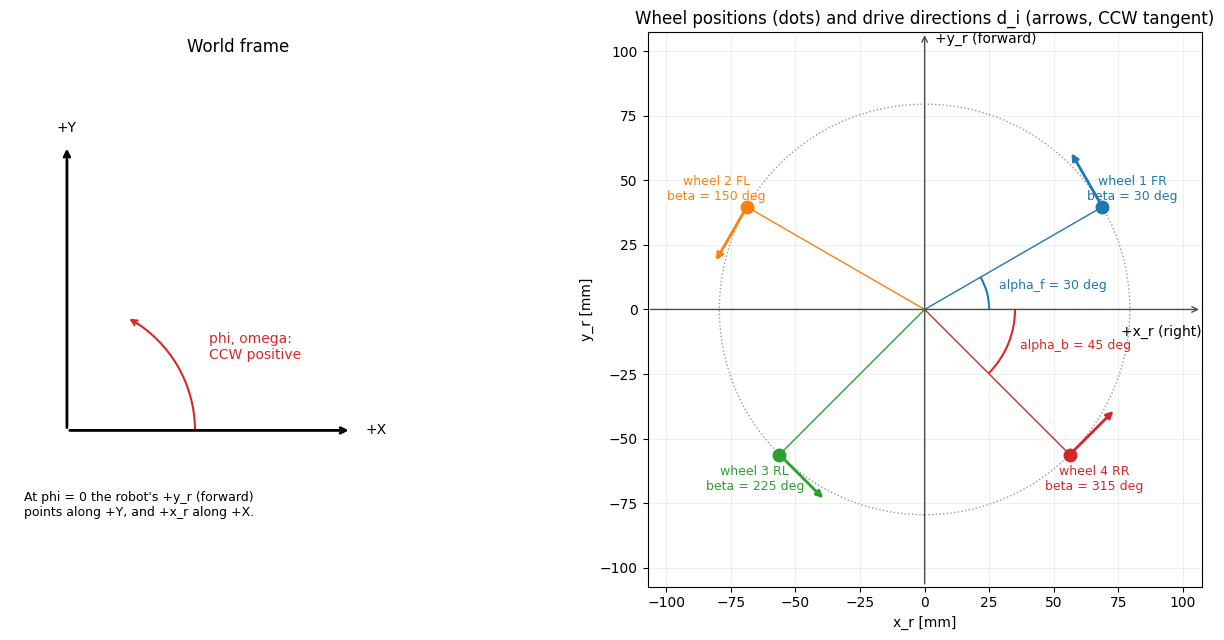

In [3]:
# Robot layout drawn from the model's own parameters (equal axes, so the angles are true).
import numpy as np
import matplotlib.pyplot as plt

def draw_layout(params):
    plant = OmniRobotSimulation(dict(params, sigma_V=0.0, sigma_mu=0.0))
    Rb = params['Rb']
    xy, H = plant.wheel_xy * 1e3, plant.H
    fig, (ax_g, ax) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2]})

    # World frame: X right, Y up; heading phi and yaw rate omega positive CCW.
    ax_g.annotate("", xy=(1.0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax_g.annotate("", xy=(0, 1.0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax_g.text(1.05, 0, "+X", va="center"); ax_g.text(0, 1.05, "+Y", ha="center")
    ax_g.add_patch(plt.matplotlib.patches.Arc((0, 0), 0.9, 0.9, theta1=0, theta2=60, color="C3", lw=1.5))
    ax_g.annotate("", xy=(0.45 * np.cos(np.radians(62)), 0.45 * np.sin(np.radians(62))),
                  xytext=(0.45 * np.cos(np.radians(55)), 0.45 * np.sin(np.radians(55))),
                  arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
    ax_g.text(0.5, 0.25, "phi, omega:\nCCW positive", color="C3")
    ax_g.text(-0.15, -0.3, "At phi = 0 the robot's +y_r (forward)\npoints along +Y, and +x_r along +X.", fontsize=9)
    ax_g.set(xlim=(-0.2, 1.4), ylim=(-0.45, 1.3), title="World frame")
    ax_g.set_aspect("equal"); ax_g.axis("off")

    lim = 1.35 * Rb * 1e3
    ax.add_patch(plt.Circle((0, 0), Rb * 1e3, fill=False, ls=":", color="0.6"))
    ax.annotate("", xy=(lim, 0), xytext=(-lim, 0), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.annotate("", xy=(0, lim), xytext=(0, -lim), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.text(lim, -6, "+x_r (right)", ha="right", va="top"); ax.text(4, lim, "+y_r (forward)", va="top")
    names = ("1 FR", "2 FL", "3 RL", "4 RR")
    for i in range(4):
        px, py = xy[i]
        ax.plot([0, px], [0, py], color=f"C{i}", lw=1)
        ax.plot(px, py, "o", color=f"C{i}", ms=9)
        dx, dy = H[i, 0], H[i, 1]
        ax.annotate("", xy=(px + 25 * dx, py + 25 * dy), xytext=(px, py),
                    arrowprops=dict(arrowstyle="-|>", color=f"C{i}", lw=2))
        beta = np.degrees(plant.wheel_angles[i]) % 360
        ax.text(px * 1.17, py * 1.17, f"wheel {names[i]}\nbeta = {beta:.0f} deg", ha="center", va="center",
                color=f"C{i}", fontsize=9)
    # Mark alpha_f and alpha_b on the right-hand wheels, measured from the +x_r axis.
    from matplotlib.patches import Arc
    af, ab = np.degrees(params['alpha_f']), np.degrees(params['alpha_b'])
    ax.add_patch(Arc((0, 0), 50, 50, theta1=0, theta2=af, color="C0", lw=1.5))
    ax.text(30 * np.cos(np.radians(af / 2)), 30 * np.sin(np.radians(af / 2)), f"alpha_f = {af:.0f} deg", color="C0", fontsize=9)
    ax.add_patch(Arc((0, 0), 70, 70, theta1=-ab, theta2=0, color="C3", lw=1.5))
    ax.text(40 * np.cos(np.radians(-ab / 2)), 40 * np.sin(np.radians(-ab / 2)), f"alpha_b = {ab:.0f} deg", color="C3", fontsize=9)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="x_r [mm]", ylabel="y_r [mm]",
           title="Wheel positions (dots) and drive directions d_i (arrows, CCW tangent)")
    ax.set_aspect("equal"); ax.grid(True, alpha=0.2)
    plt.tight_layout(); plt.show()

draw_layout(simulation_parameters)

# ✅ Model verification with Henry's constants

These checks test the plant itself, before any of the open-loop manoeuvres below:

1. **Geometry:** the wheel positions from $\mathbf H$ match the CAD layout, and the drive directions are unit CCW tangents.
2. **Normal forces:** they sum to $M_r g$ and satisfy the pitch and roll moment balances, at rest and while accelerating.
3. **World-frame velocity:** with no contact force, a robot coasting forward at 1 m/s while spinning at 3 rad/s travels in a straight line at constant speed (Dana's original drives a circle of radius 0.33 m).
4. **Motor current:** a stalled 1 V step settles at $V/R$ with no overshoot, at the 1 ms step used here.
5. **Saturation:** an unlimited voltage command never exceeds `IQ_LIMIT`; a lifted wheel (friction off) settles at the no-load speed $V_{\max}/K_b$.
6. **Slip threshold:** the largest motor force $K_tI_{\max}/r$ against the static grip $\mu_s N$, and a full-voltage forward run, which shows whether load transfer makes the front wheels slip.

In [4]:
import numpy as np

vp = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
sim = OmniRobotSimulation(vp)

# 1. Geometry against the CAD layout (same axes: x right, y forward; angles CCW from +x).
alpha = np.radians(rc.WHEEL_ALPHA_DEG)                      # rc order: FR, FL, BL, BR (matches 1..4 here)
cad_xy = rc.WHEEL_ROBOT_DIST * np.column_stack((np.cos(alpha), np.sin(alpha)))
print("1) wheel positions [mm], model vs CAD:")
for i, name in enumerate(("FR", "FL", "RL", "RR")):
    print(f"   {name}: {sim.wheel_xy[i] * 1e3}  vs  {cad_xy[i] * 1e3}")
assert np.allclose(sim.wheel_xy, cad_xy, atol=1e-9), "H geometry does not match the CAD layout"
assert np.allclose(np.linalg.norm(sim.H[:, :2], axis=1), 1.0) and np.allclose(sim.H[:, 2], vp['Rb'])
lever = sim.wheel_xy[:, 0] * sim.H[:, 1] - sim.wheel_xy[:, 1] * sim.H[:, 0]
assert np.allclose(lever, vp['Rb']), "Drive directions must be CCW tangents with lever Rb"
print("   PASS: H matches the CAD layout; drive directions are CCW tangents with lever Rb")

# 2. Normal-force balances.
m, h, g = vp['Mr'], vp['h'], vp['g']
x, y = sim.wheel_xy[:, 0], sim.wheel_xy[:, 1]
for a in ((0.0, 0.0), (0.0, 2.5), (2.5, 0.0), (2.0, -3.0)):
    st = OmniMotorState(); st.a_local_past = np.array([a[0], a[1], 0.0])
    N = sim.compute_dynamic_normal_forces(st)
    assert np.isclose(N.sum(), m * g) and np.isclose(N @ x, -m * a[0] * h) and np.isclose(N @ y, -m * a[1] * h)
    print(f"2) a = (a_x right, a_y forward) = {a} m/s^2: N = {N} N (FR, FL, RL, RR)")
print("   PASS: sum N = m g, sum N y = -m a_y h (pitch), sum N x = -m a_x h (roll)")

# 3. World-frame velocity: coast with no contact force.
st = OmniMotorState(); st.v_global = np.array([0.0, 1.0, 3.0]); st.v_local = st.v_global.copy()   # 1 m/s forward, yaw 3 rad/s
for _ in range(int(1.0 / vp['dt'])):
    st = sim.advance_chassis_kinetics(np.zeros(4), st)
print(f"3) coast 1 s: world velocity {st.v_global[:2]} m/s, position {st.pos_global[:2]} m")
assert np.allclose(st.v_global[:2], [0.0, 1.0], atol=0.02) and abs(st.pos_global[0]) < 0.02
print("   PASS: straight line at constant speed (forward Euler error only)")

# 4. Motor current: stalled 1 V step.
st = OmniMotorState(); I = []
for _ in range(20):
    sim.compute_electrical_subsystem(st, np.ones(4)); st.I = st.I_next; I.append(st.I[0])
I = np.array(I)
print(f"4) 1 V stall step at dt = {vp['dt'] * 1e3:.1f} ms: current {I[:4]} ... {I[-1]:.4f} A (V/R = {1 / vp['R']:.4f} A)")
assert np.isclose(I[-1], 1 / vp['R'], rtol=1e-6) and I.max() <= 1 / vp['R'] + 1e-12
print("   PASS: settles at V/R with no overshoot")

# 5. Saturation: unlimited command, wheels lifted (friction off -> mu = 0).
lifted = OmniRobotSimulation(dict(vp, mu_s=0.0, mu_k=0.0, Crr=0.0))
st = OmniMotorState(); peak_I = 0.0
for _ in range(int(0.5 / vp['dt'])):
    st, _, _ = lifted.step(st, np.full(4, 1e3))
    peak_I = max(peak_I, np.max(np.abs(st.I)))
no_load = vp['V_max'] / vp['Kb']
print(f"5) unlimited command, lifted wheels: peak current {peak_I:.3f} A (limit {vp['I_max']}), "
      f"wheel speed {st.theta_dot[0]:.1f} rad/s (no-load {no_load:.1f} rad/s)")
assert peak_I <= vp['I_max'] + 1e-9 and np.isclose(st.theta_dot[0], no_load, rtol=0.01)
print("   PASS: current limited, free wheel settles at the no-load speed")

# 6. Slip threshold and a full-voltage forward run.
F_motor = vp['Kt'] * vp['I_max'] / vp['r']
N0 = sim.compute_dynamic_normal_forces(OmniMotorState())
print(f"6) max motor force K_t I_max / r = {F_motor:.2f} N; static grip mu_s N at rest = {vp['mu_s'] * N0} N")
st = OmniMotorState(); slip_steps = np.zeros(4, int); first_slip = None; a_peak = 0.0
for k in range(int(1.0 / vp['dt'])):
    st, _, S = sim.step(st, np.array([1.0, -1.0, -1.0, 1.0]) * vp['V_max'])
    slip_steps += S
    a_peak = max(a_peak, st.a_local_past[1])   # forward = +y
    if first_slip is None and np.any(S):
        first_slip = (k * vp['dt'], S.copy(), st.a_local_past[:2].copy())
print(f"   full-voltage forward run (1 s): peak forward accel {a_peak:.2f} m/s^2; slipping steps per wheel {slip_steps} "
      f"(FR, FL, RL, RR); final [x_dot, y_dot, omega] = {st.v_local}")
if first_slip is not None:
    print(f"   first slip at t = {first_slip[0]:.3f} s on wheels {np.flatnonzero(first_slip[1]) + 1}, "
          f"acceleration then {first_slip[2]} m/s^2")

1) wheel positions [mm], model vs CAD:
   FR: [68.83602922 39.7425    ]  vs  [68.83602922 39.7425    ]
   FL: [-68.83602922  39.7425    ]  vs  [-68.83602922  39.7425    ]
   RL: [-56.2043825 -56.2043825]  vs  [-56.2043825 -56.2043825]
   RR: [ 56.2043825 -56.2043825]  vs  [ 56.2043825 -56.2043825]
   PASS: H matches the CAD layout; drive directions are CCW tangents with lever Rb
2) a = (a_x right, a_y forward) = (0.0, 0.0) m/s^2: N = [7.75211612 7.75211612 5.48157388 5.48157388] N (FR, FL, RL, RR)
2) a = (a_x right, a_y forward) = (0.0, 2.5) m/s^2: N = [5.6028552 5.6028552 7.6308348 7.6308348] N (FR, FL, RL, RR)
2) a = (a_x right, a_y forward) = (2.5, 0.0) m/s^2: N = [5.95467178 9.54956046 6.94918103 4.01396672] N (FR, FL, RL, RR)
2) a = (a_x right, a_y forward) = (2.0, -3.0) m/s^2: N = [ 8.89327376 11.7691847   4.0765465   1.72837505] N (FR, FL, RL, RR)
   PASS: sum N = m g, sum N y = -m a_y h (pitch), sum N x = -m a_x h (roll)
3) coast 1 s: world velocity [0. 1.] m/s, position [0. 1.

# 🧪 Kinematic & Dynamic Verification Testing

This section executes open-loop verification trials to validate the electromechanical motor re-coupling, asymmetric kinematics mapping ($\mathbf{H}$), and stick-slip friction boundaries under hardware-verified sign directions.

### 📐 Structural Testing Grid Architecture
The execution pipeline performs a **multi-block comparative analysis** across two distinct physical frame designs and environmental settings:
1. **Block 1: Symmetric Frame Verification:** Configures the plant layout to an identical 45° alignment across all wheel lines ($\alpha_f = 45^\circ$, $\alpha_b = 45^\circ$).
2. **Block 2: Asymmetric Frame Verification:** Henry's layout ($\alpha_f = 30^\circ$, $\alpha_b = 45^\circ$, CCW from $+x_r$), the same 30/45 as Dana's original.

### 🕹️ Verification Test Input Sequences
To isolate each independent degree of freedom, the simulation applies precise step voltage patterns across the four wheel motors:
*   **Test 1: Forward Motion ($\mathbf{V} = [2.0, -2.0, -2.0, 2.0]^\top$):** Applies positive voltages to the right-side motors ($1, 4$) and negative voltages to the left-side motors ($2, 3$). This drives all wheels to push the ground backward symmetrically, canceling out lateral side forces and accelerating the robot straight ahead along its local $+y_r$ axis.
*   **Test 2: Lateral Side-Strafing ($\mathbf{V} = [-2.0, -2.0, 2.0, 2.0]^\top$):** Applies negative voltages to the front axle motors ($1, 2$) and positive voltages to the rear axle motors ($3, 4$). This mirrors the longitudinal forces across the front-to-back split line, causing forward and backward vectors to cancel out. The remaining lateral components combine to push the chassis cleanly sideways to the right, along its local $+x_r$ axis.
*   **Test 3: Pure Rotational Spinning ($\mathbf{V} = [2.0, 2.0, 2.0, 2.0]^\top$):** Applies uniform positive voltages to all four wheels simultaneously. Because every omni-wheel is mounted tangentially to the chassis base circle, spinning them all in the same rotational direction eliminates all linear translation vectors and creates a pure angular torque, spinning the robot counter-clockwise ($+\varphi$) around its Center of Mass.

### 🔄 Dual-Pass State Conditions
To clearly isolate the degradation caused by environmental disturbances, each vehicle geometry executes a sequential dual-pass simulation:
*   **Ideal Pass (Reference Baseline):** Strips all noise configurations ($\sigma_V = 0.0$, $\sigma_\mu = 0.0$). The results render as soft, transparent curves representing perfect theoretical trajectories.
*   **Perturbed Pass (Real-World Overlay):** Activates a repeatable, seeded random number generator stream (`np.random.default_rng`) to overlay high-frequency structural chassis vibrations ($w_F$) and spatial friction coefficient patches ($w_\mu$).

### 📊 Logged Telemetry Variables
Each configuration runs the three directional maneuvers back-to-back over a 1.5-second time window (1500 discrete calculation steps) and generates a standalone 2x2 grid capturing:
*   **Applied Motor Terminal Voltages ($V_{1\dots4}$):** Verifies step-input directional polarities.
*   **Wheel Angular Velocities ($\dot\theta_{1\dots4}$):** Monitors electromechanical back-EMF variations and independent rotor spinout integrations ($J_w$).
*   **Chassis Local Frame Speeds ($\dot{x}_r, \dot{y}_r, \omega$):** Evaluates translational and angular momentum unbalances inside the mass matrix universe ($\mathbf{M}^{-1}\mathbf{H}^\top\mathbf{F}_k$).
*   **Global Position Tracking ($X-Y$ Trajectory Plane):** Visualizes dead-reckoning coordinate transformation drift paths directly overlaying ideal performance vs. noisy tracking realities.

Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...


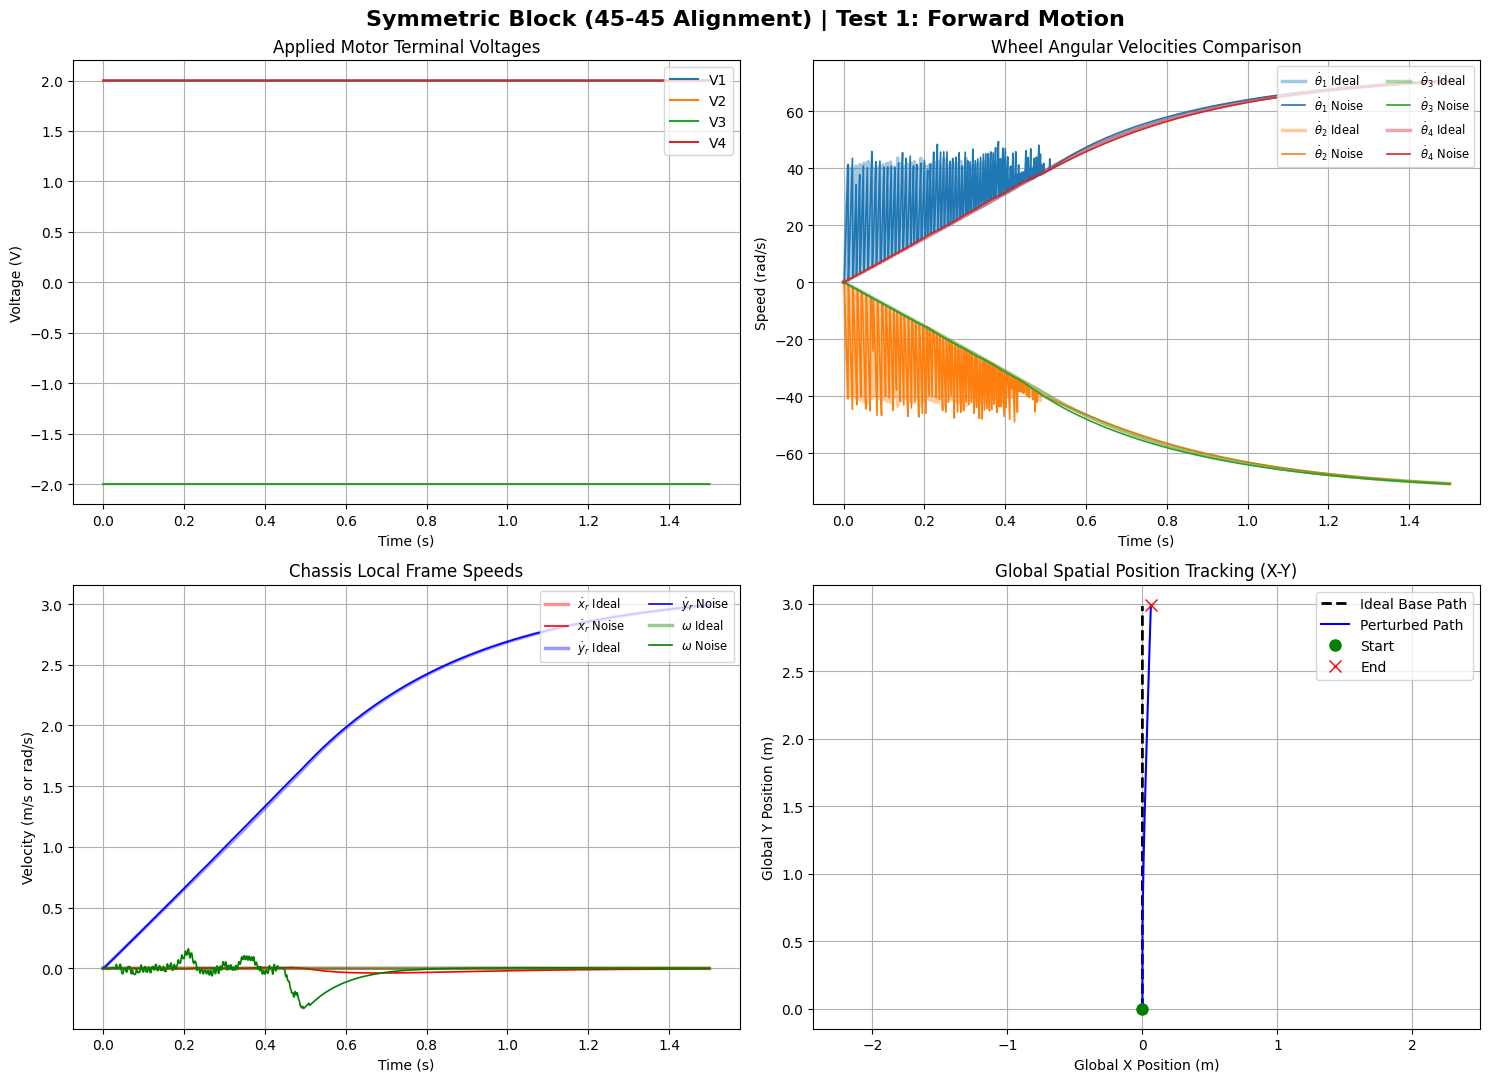

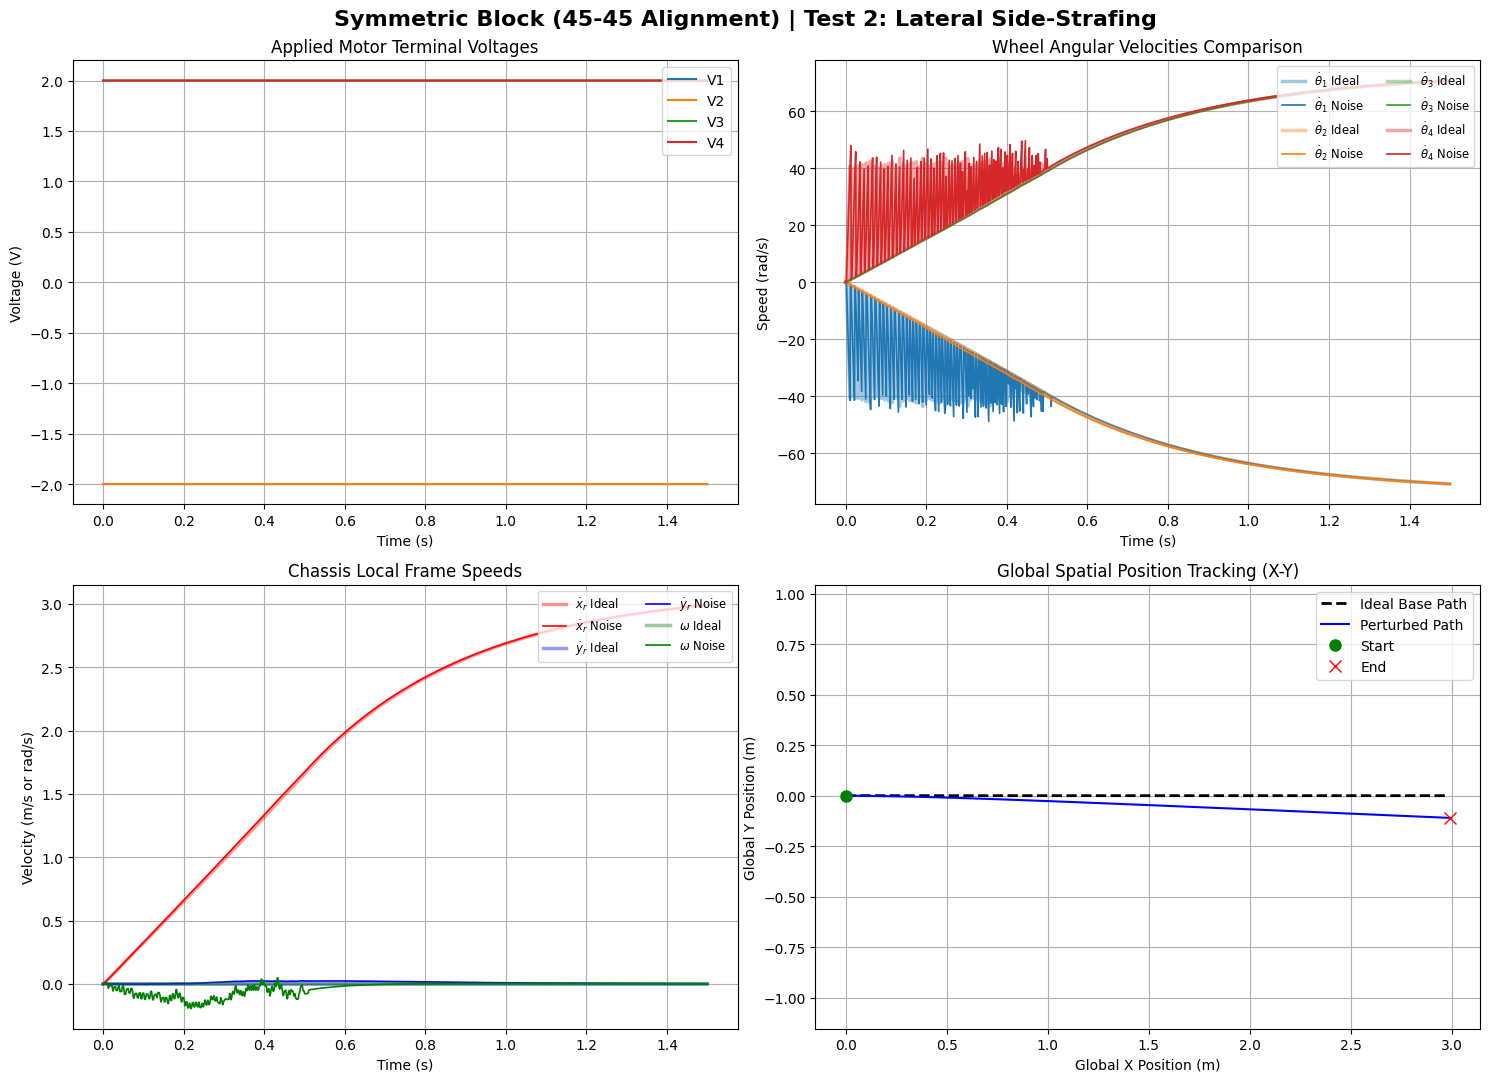

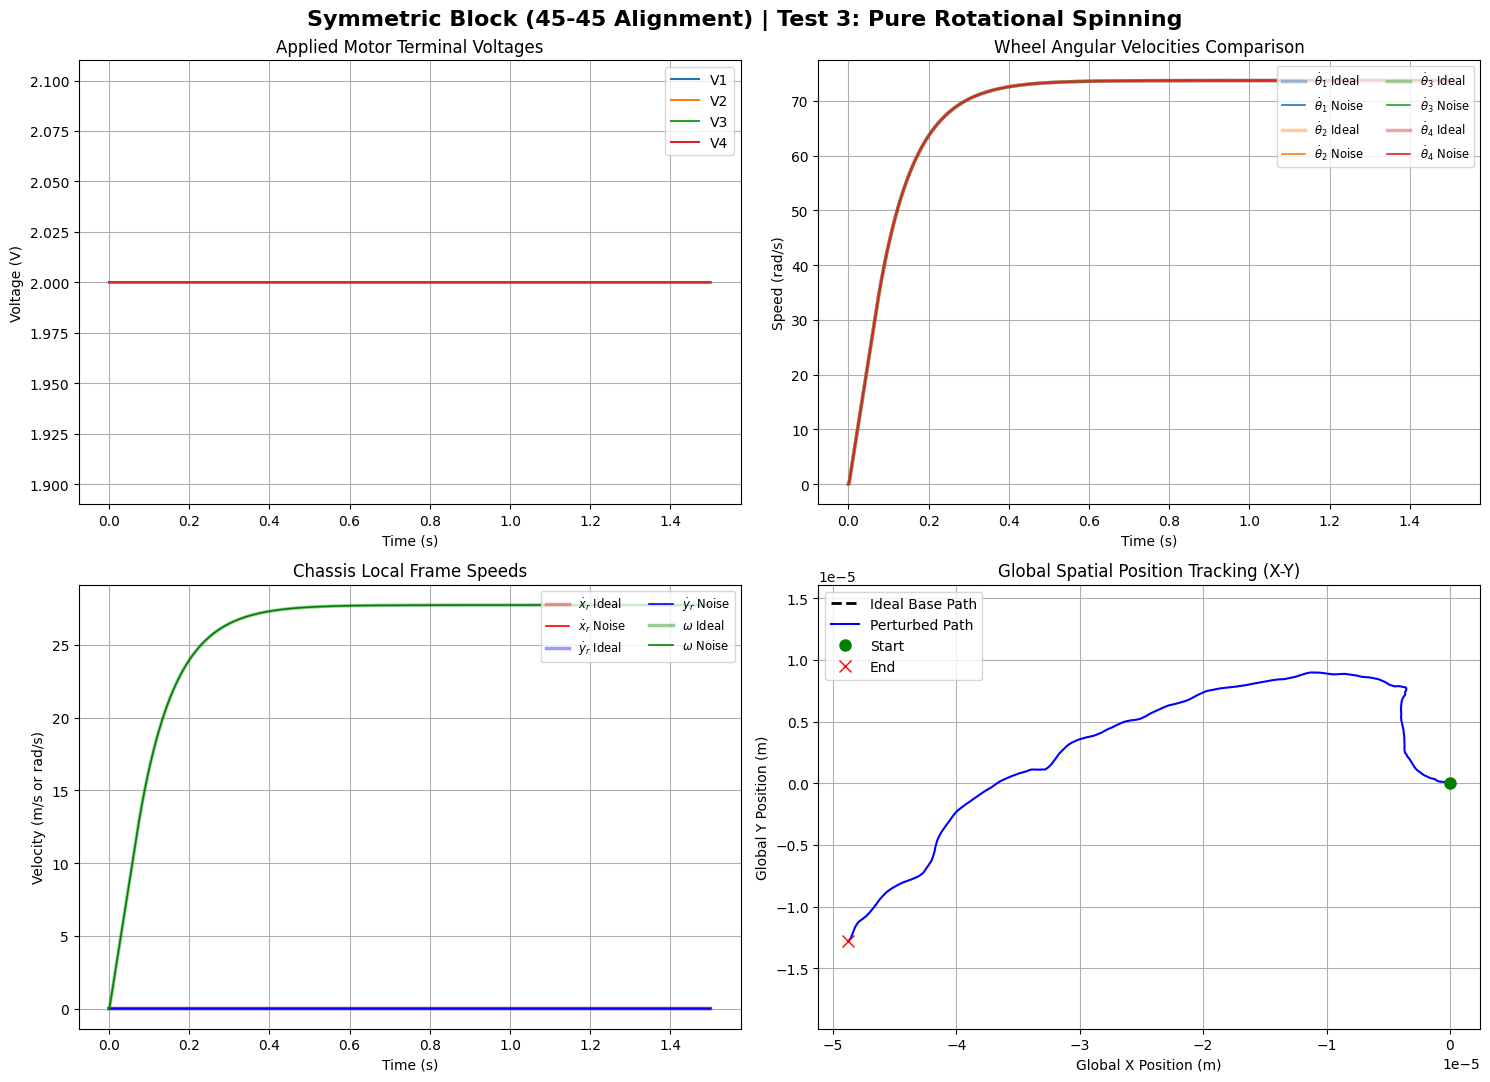

In [5]:
import numpy as np
import matplotlib.pyplot as plt

nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

t_end = 1.5  
dt = simulation_parameters['dt']
steps = int(t_end / dt)
t_vec = np.linspace(0, t_end, steps)

low_voltage = 2
maneuvers = [
    {"name": "Test 1: Forward Motion", "V": np.array([low_voltage, -low_voltage, -low_voltage, low_voltage])},
    {"name": "Test 2: Lateral Side-Strafing", "V": np.array([-low_voltage, -low_voltage, low_voltage, low_voltage])},
    {"name": "Test 3: Pure Rotational Spinning", "V": np.array([low_voltage, low_voltage, low_voltage, low_voltage])}
]

# REMOVED redundancy: line style 'ls' is isolated out of the style modifiers
style_ideal = {'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'alpha': 1.0, 'lw': 1.2}  

# CONFIGURATION CHANGE: FORCE SYMMETRIC 45-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(45.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, theta_dot_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            theta_dot_hist.append(state.theta_dot.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "theta_dot": np.array(theta_dot_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Symmetric Block (45-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["theta_dot"][:, w], '-', color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["theta_dot"][:, w], '-', color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Isolated style configuration)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\omega$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\omega$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

Executing Block 2: Henry's 30-45 layout Wheel Angle Configurations...


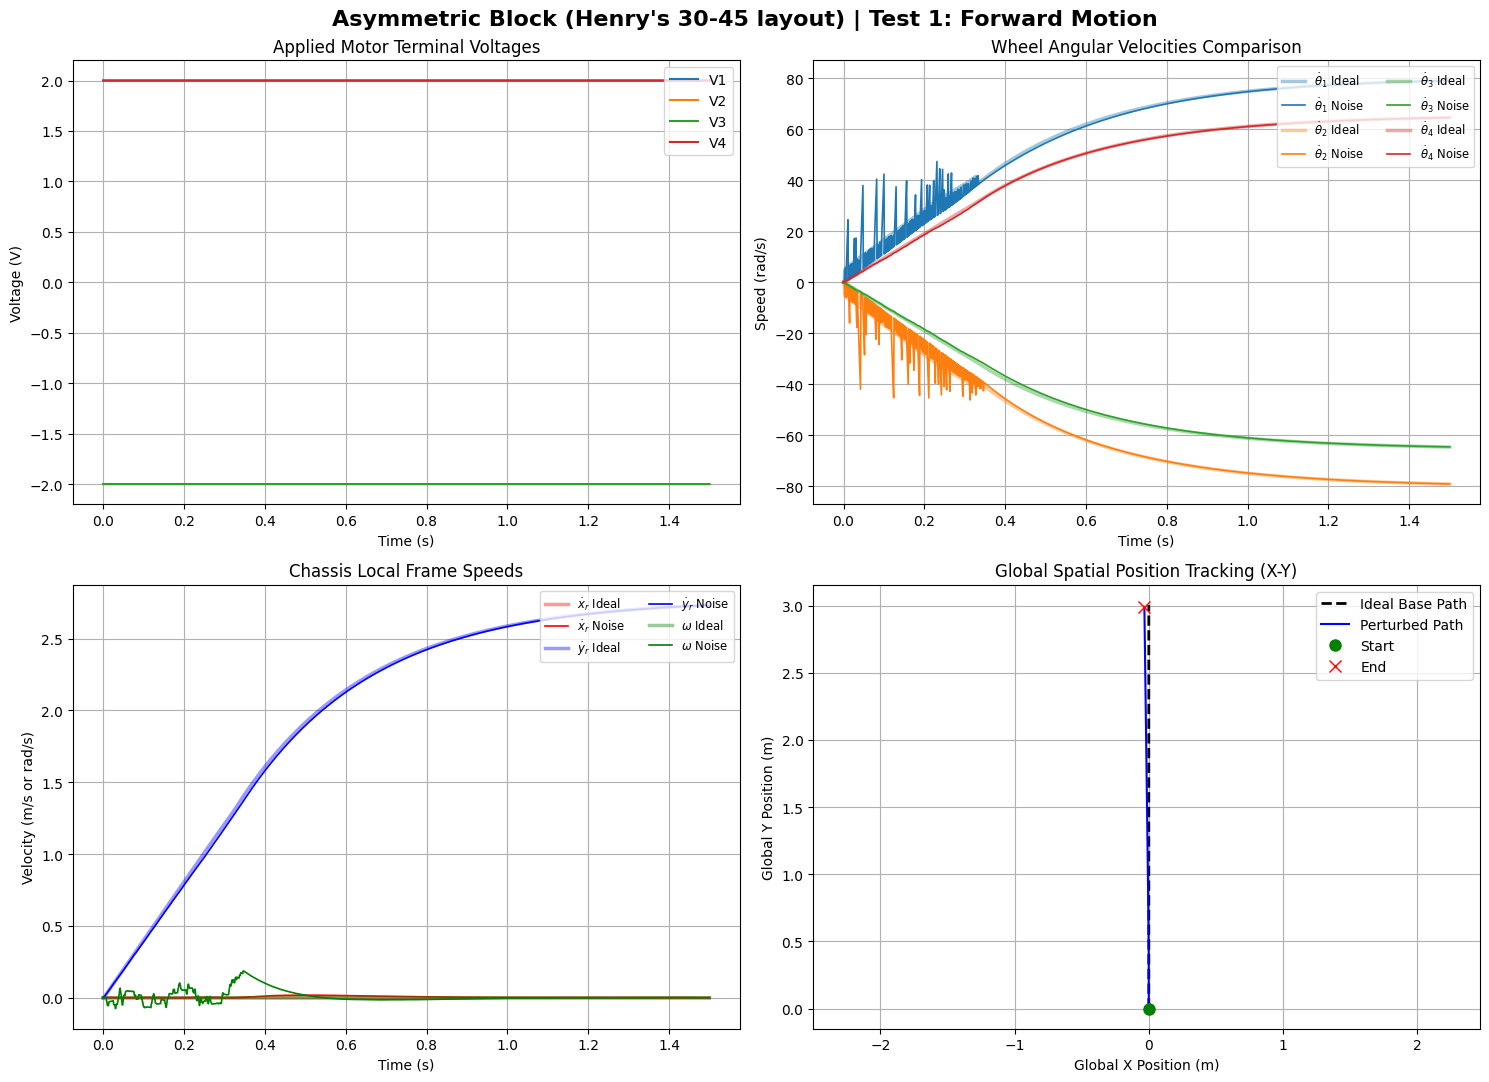

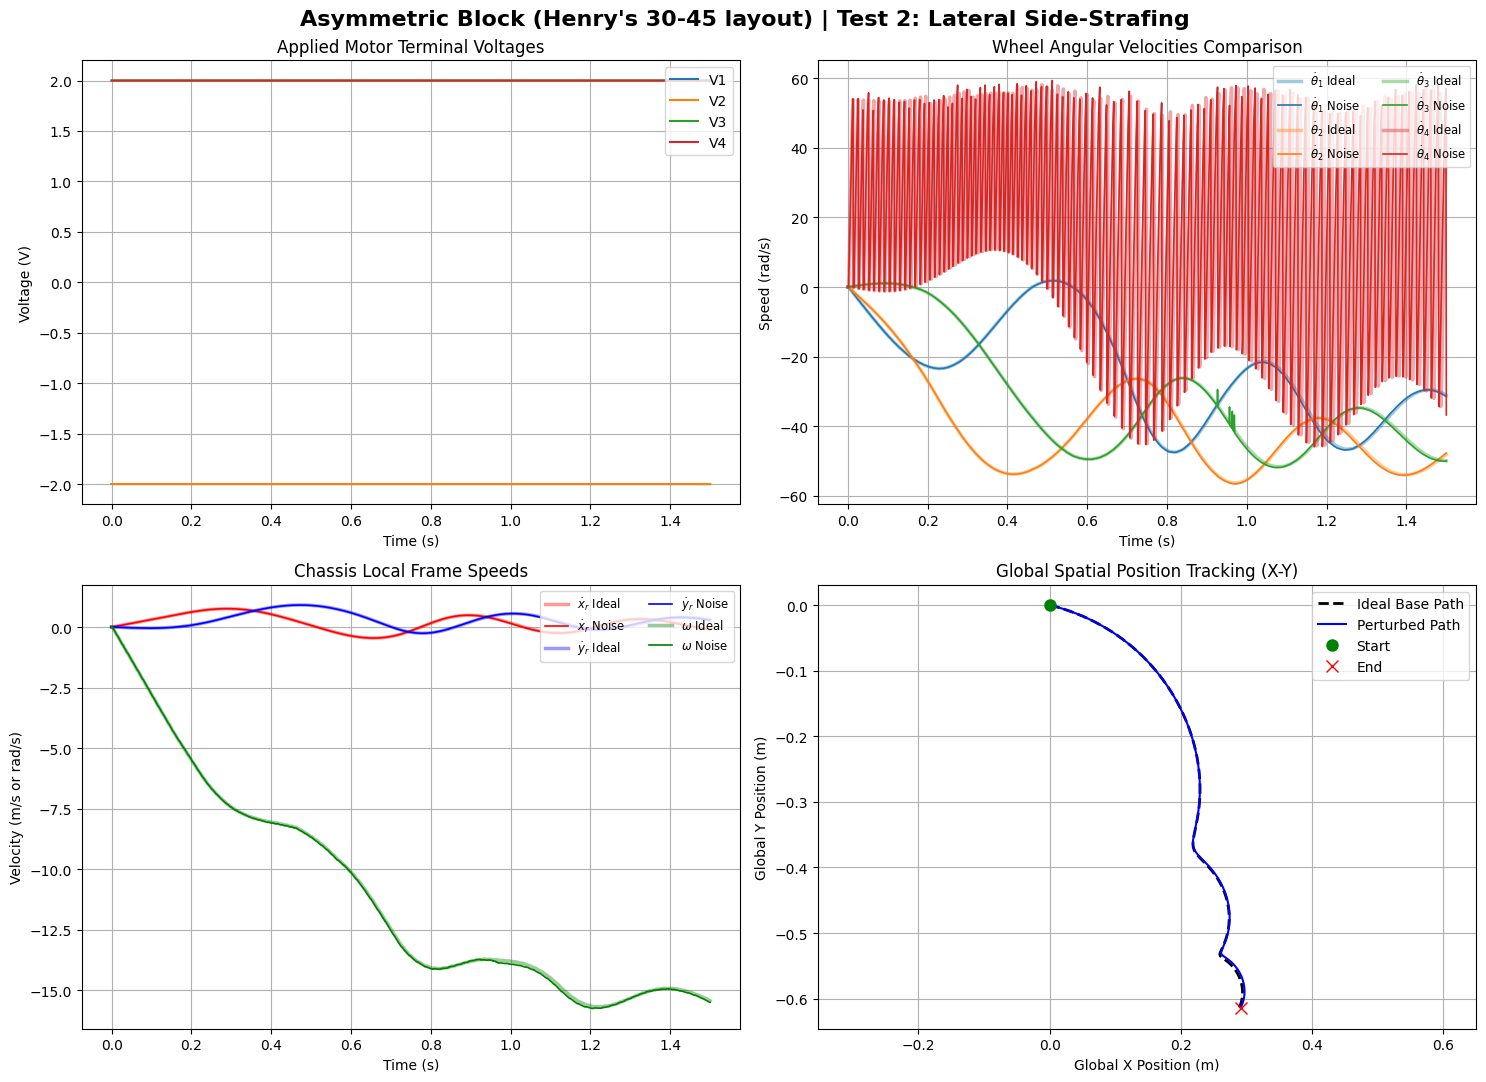

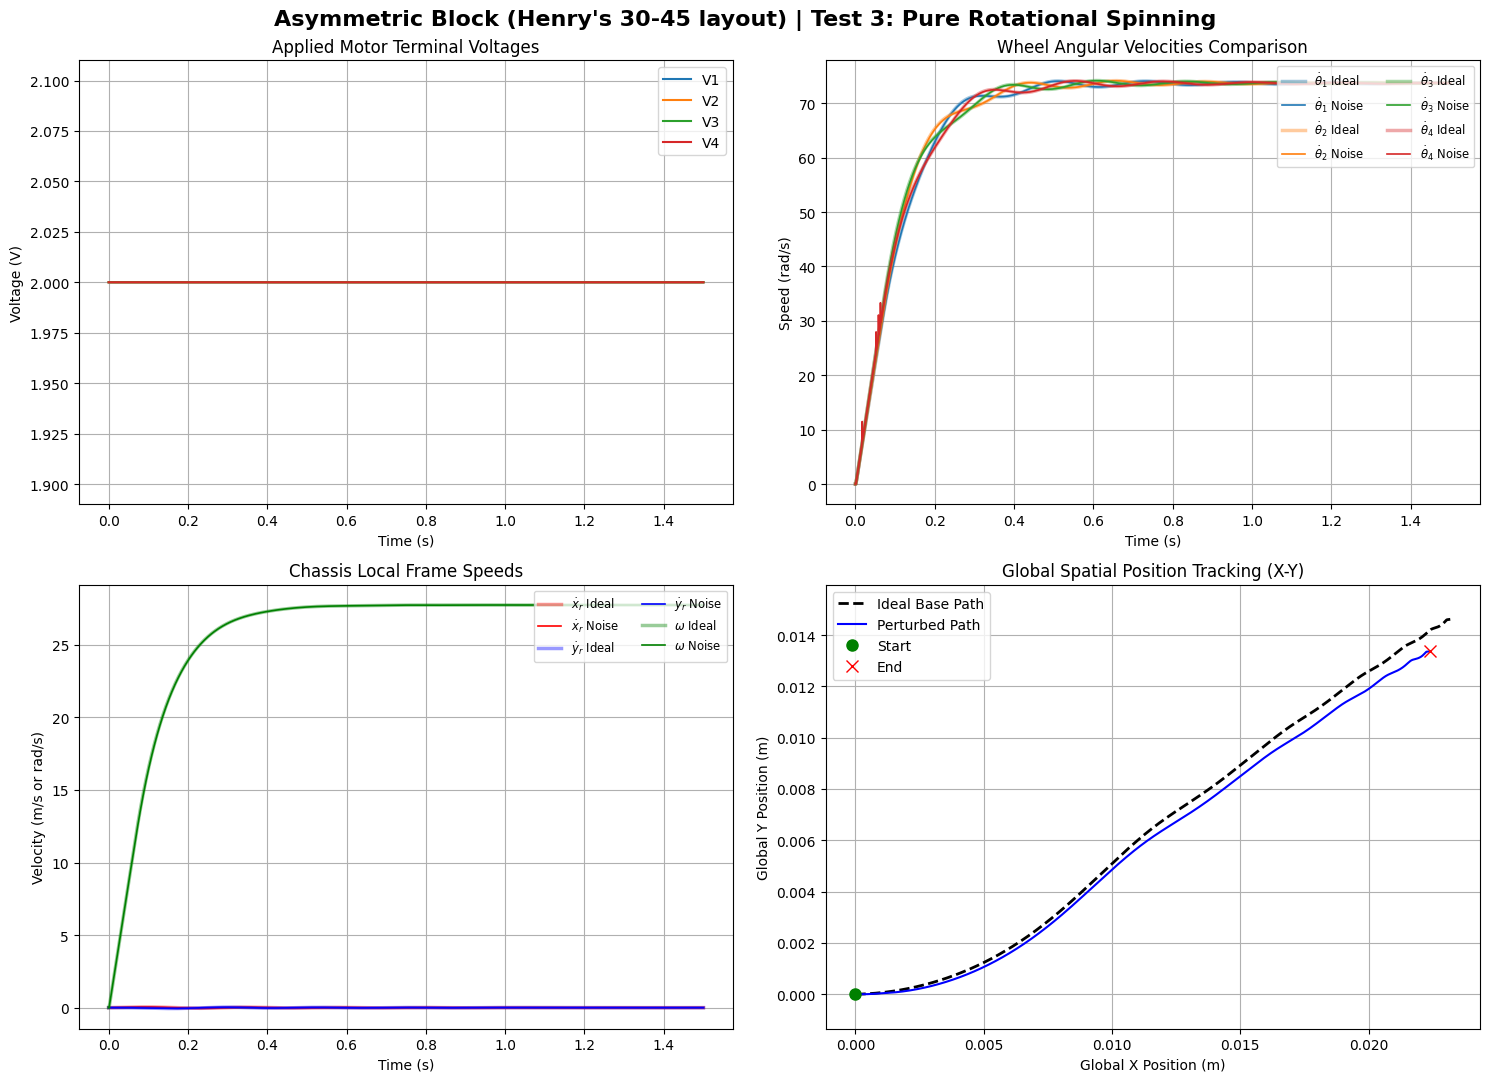

In [6]:
# CONFIGURATION CHANGE: HENRY'S 30-45 LAYOUT
simulation_parameters['alpha_f'] = np.radians(rc.WHEEL_ALPHA_DEG[0])  # Henry's layout: 30 deg CCW from +x_r
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 2: Henry's 30-45 layout Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, theta_dot_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            theta_dot_hist.append(state.theta_dot.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "theta_dot": np.array(theta_dot_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Block (Henry's 30-45 layout) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["theta_dot"][:, w], '-', color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["theta_dot"][:, w], '-', color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Line parameters isolated)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\omega$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\omega$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Safely restore baseline parameter noise variables back to configuration dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu

Executing Block 3: Henry's 30-45 layout Wheel Angle Configurations at High Voltage (5.0V)...


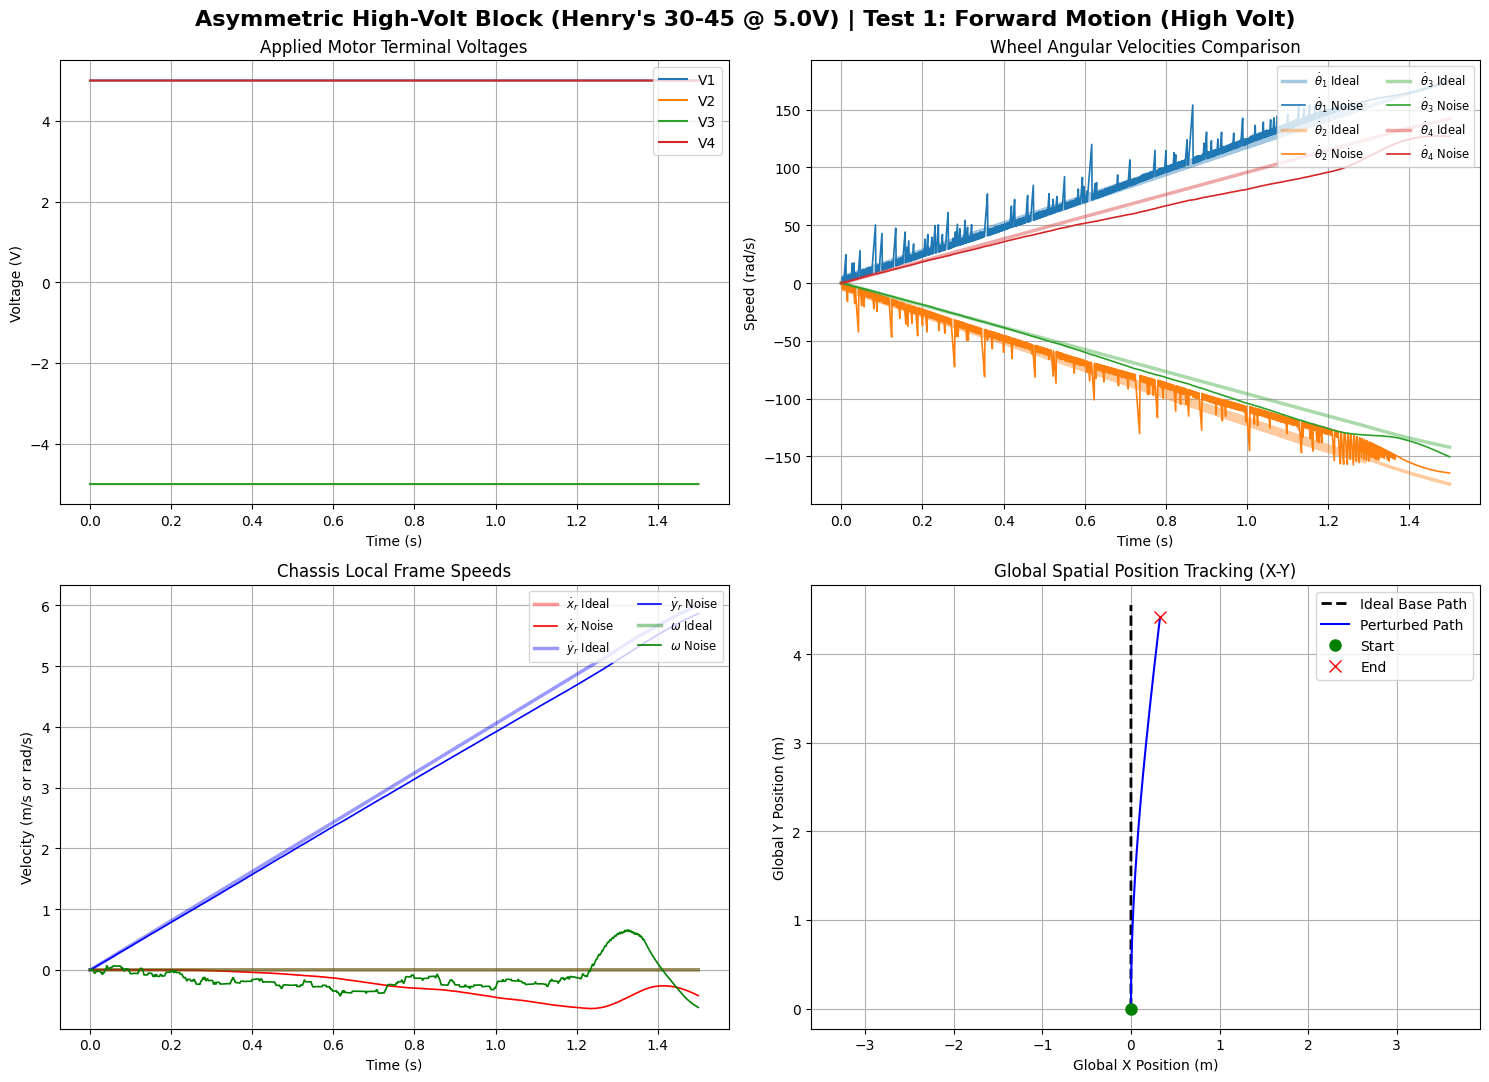

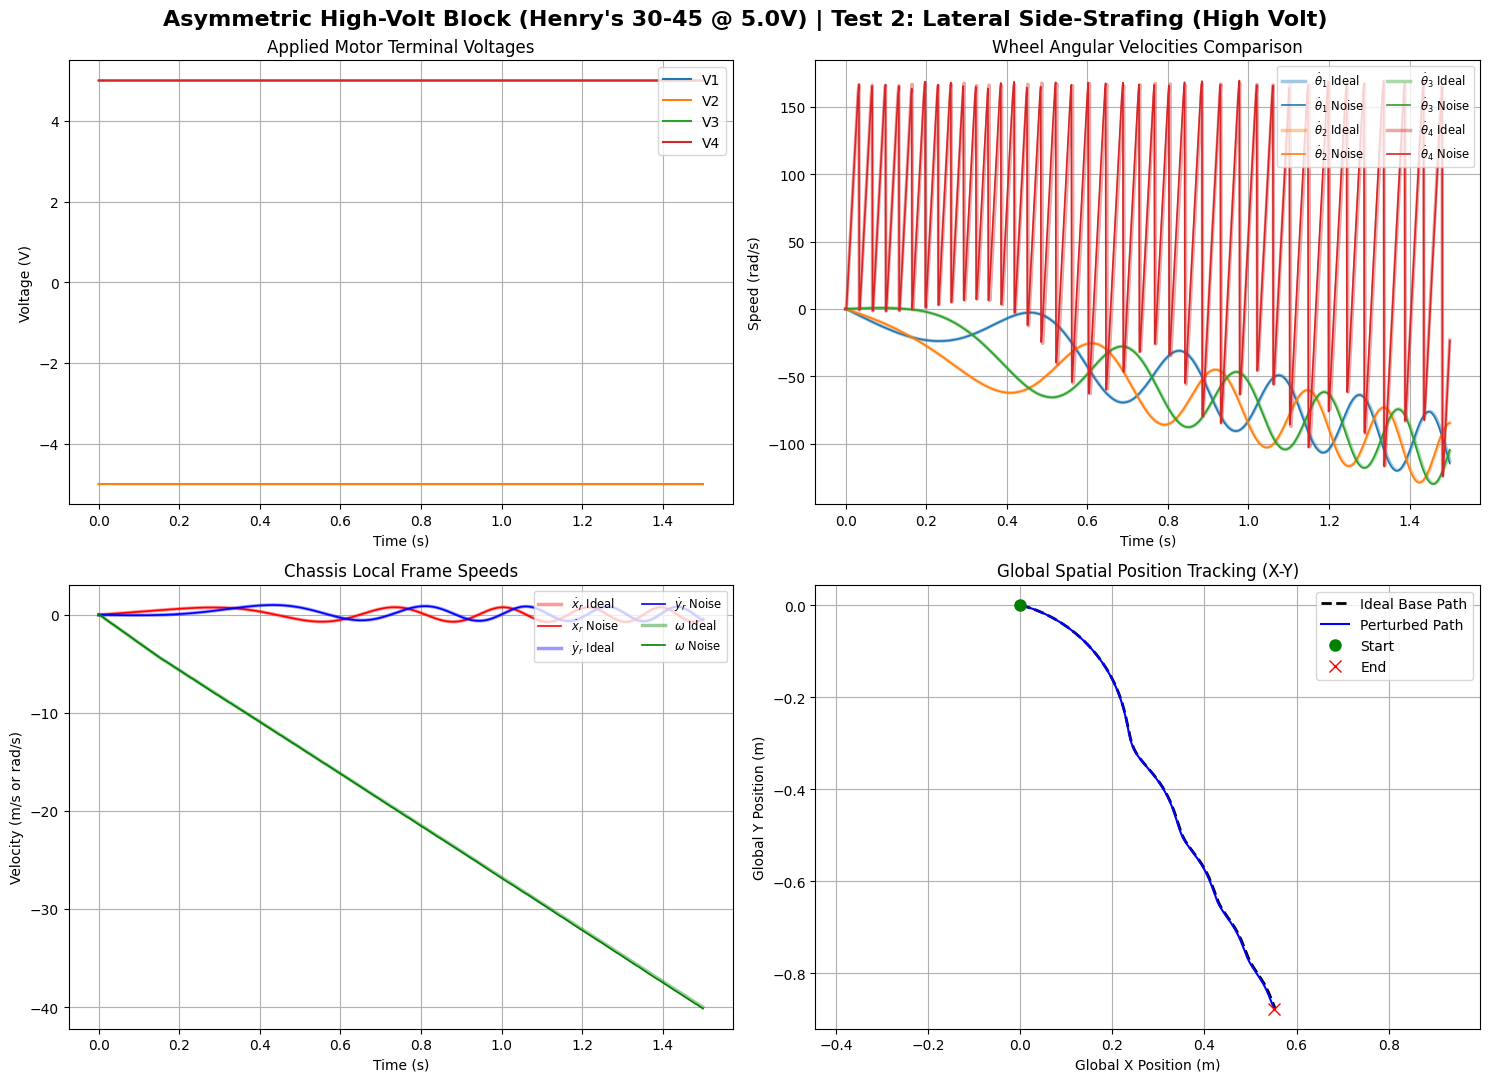

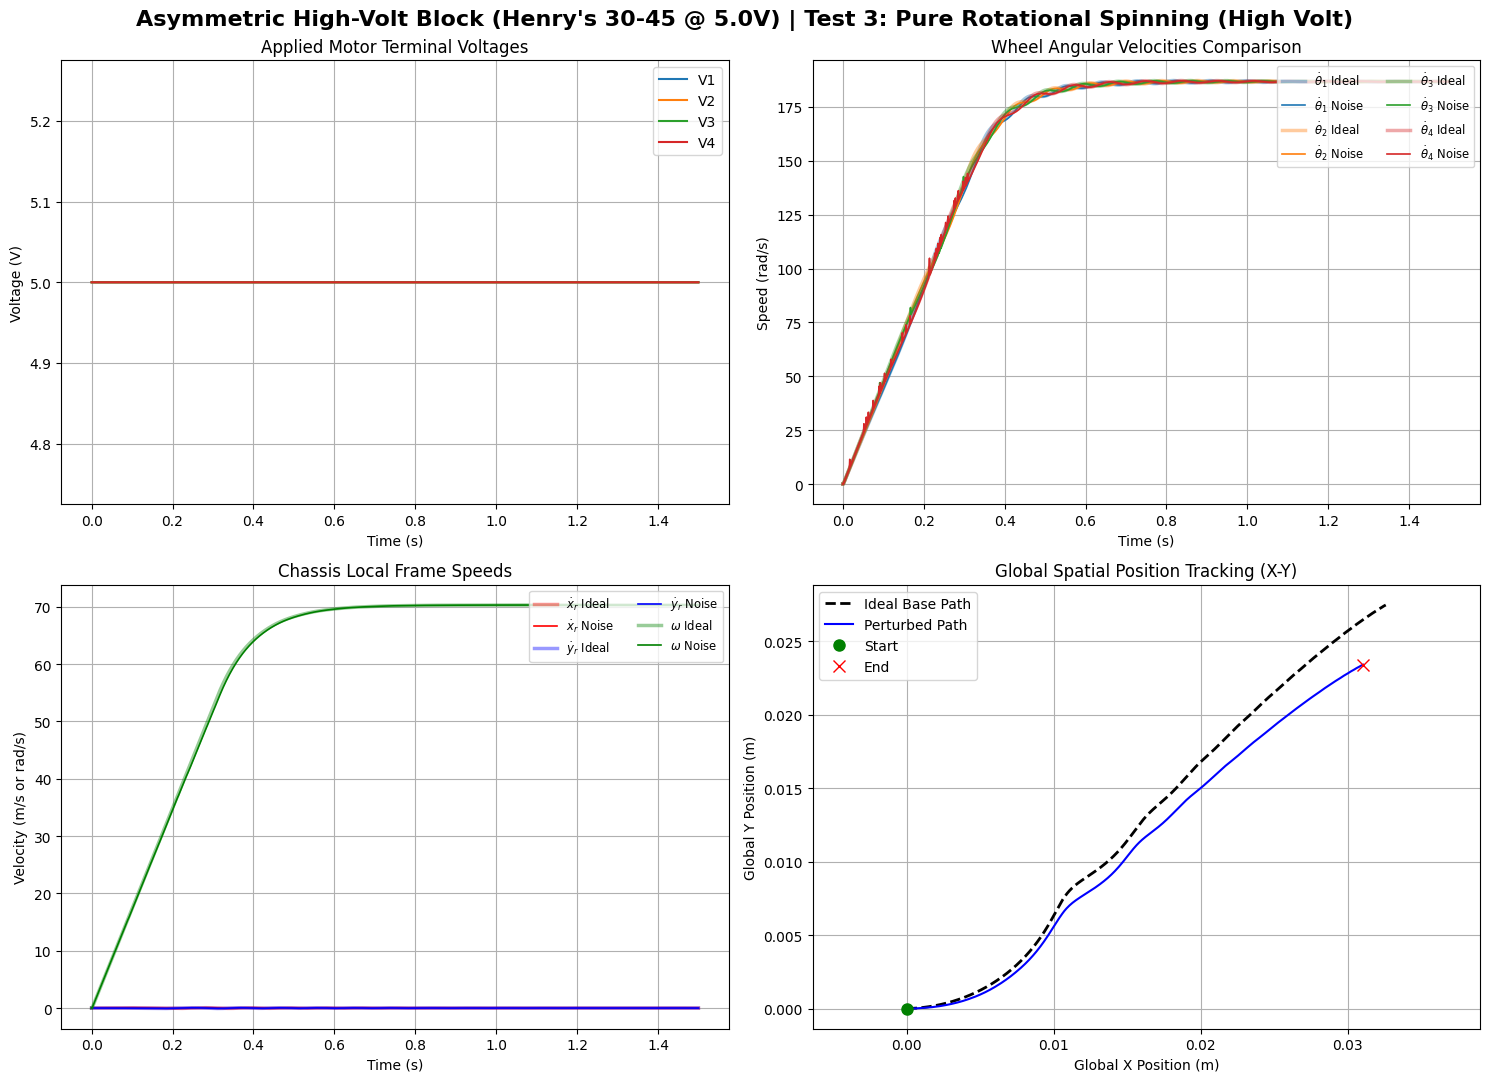

In [7]:
# =======================================================================
# CONFIGURATION CHANGE: HENRY'S 30-45 LAYOUT BUT BOOST TO 5.0V
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(rc.WHEEL_ALPHA_DEG[0])  # Henry's layout: 30 deg CCW from +x_r
simulation_parameters['alpha_b'] = np.radians(45.0)

bost_voltage = 5.0

# Define high-voltage directional maneuvers matching your verified sign choices
high_volt_maneuvers = [
    {"name": "Test 1: Forward Motion (High Volt)", "V": np.array([bost_voltage, -bost_voltage, -bost_voltage, bost_voltage])},
    {"name": "Test 2: Lateral Side-Strafing (High Volt)", "V": np.array([-bost_voltage, -bost_voltage, bost_voltage, bost_voltage])},
    {"name": "Test 3: Pure Rotational Spinning (High Volt)", "V": np.array([bost_voltage, bost_voltage, bost_voltage, bost_voltage])}
]

print("Executing Block 3: Henry's 30-45 layout Wheel Angle Configurations at High Voltage (5.0V)...")

for m in high_volt_maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        # Instantiate plant under custom asymmetric high-volt conditions (Seeded for reproducibility)
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, theta_dot_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            theta_dot_hist.append(state.theta_dot.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "theta_dot": np.array(theta_dot_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric High-Volt Block (Henry's 30-45 @ 5.0V) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["theta_dot"][:, w], '-', color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["theta_dot"][:, w], '-', color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\omega$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\omega$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Final safe restoration of baseline parameter noise variables back to dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu

# 🧪 Multi-Stage Sequence Verification Testing

This section updates the verification routines to implement a **Multi-Stage Step Profile Timeline**. Instead of using simple, constant voltage step inputs, each directional test commands a dynamic voltage profile divided into three sequential 1.0-second stages. This structure explicitly evaluates your plant's transient response, high-velocity deceleration behavior, and rolling drag coasting decays.

### 🕹️ Chronological Stage Sequences
For each of the three directional axes, the simulation pushes a dynamic voltage vector $\mathbf{U}_k$ that varies depending on the current time step interval:
1.  **Stage 1: Positive Command Interval ($0.0\text{s} \le t < 1.0\text{s}$):** Motors receive a $+4.0$V scaled step command based on your hardware sign choices to accelerate the robot from a dead stop.
2.  **Stage 2: Negative/Reversal Interval ($1.0\text{s} \le t < 2.0\text{s}$):** Voltages instantly flip polarity to $-4.0$V. This forces the motor drives to act as active plug-brakes, fighting the massive momentum of the chassis, decelerating it to a stop, and reversing its trajectory.
3.  **Stage 3: Zero/Coasting Interval ($2.0\text{s} \le t \le 3.0\text{s}$):** Voltage commands drop flat to $0.0$V. The robot's electrical drive cuts out entirely, forcing the vehicle to coast to a complete stop purely by bleeding kinetic energy through the wheels' internal parasitic rolling resistance ($C_{rr}$).

### 🗺️ Multi-Stage Directional Key
The three tests map these positive/negative/zero step magnitudes to the following hardware-verified wheel groups:
*   **Test 1: Forward/Backward Sequence:** Drives straight ahead along local $+y_r$, plugs the motors into reverse to fly backward along $-y_r$, and then cuts voltage to zero.
*   **Test 2: Side-to-Side Sequence:** Strafes directly left along local $-x_r$, reverses direction to strafe back right along $+x_r$, and then drops into a dead coast.
*   **Test 3: CCW/CW Rotation Sequence:** Spins the entire robot counter-clockwise ($+\varphi$) around its Center of Mass, actively reverses momentum into a clockwise spin ($-\varphi$), and then coasts down.

### 🔄 Comparative Telemetry Observations
By stringing these phases back-to-back, the generated 2x2 graphics grids highlight critical non-linear coupling effects across the **Ideal vs. Disturbed** runs:
*   **Transient Speed Chattering:** At the $t = 1.0$s mark, when the voltage violently snaps from positive to negative, the wheels experience a massive sudden torque unbalance while the vehicle chassis is still moving forward. This breaks floor adhesion and causes **prolonged, high-frequency wheel speed spikes** on the disturbed plots as wheels lose grip and spin out independently.
*   **Deceleration and Coasting Curves:** Subplot 3 visualizes the real-world back-EMF damping slopes during reverse braking, alongside the long exponential velocity decay during the final unpowered coasting interval.
*   **Trajectory Drift Accumulation:** Subplot 4 maps the absolute spatial motion. It marks exactly where the direction switches happen (`Switch to Neg` and `Switch to Zero`), illustrating how uneven wheel spinouts during violent direction changes heavily amplify open-loop navigation drift away from the baseline ideal path.

Executing Profile Tests under Henry's 30-45 layout Geometry...


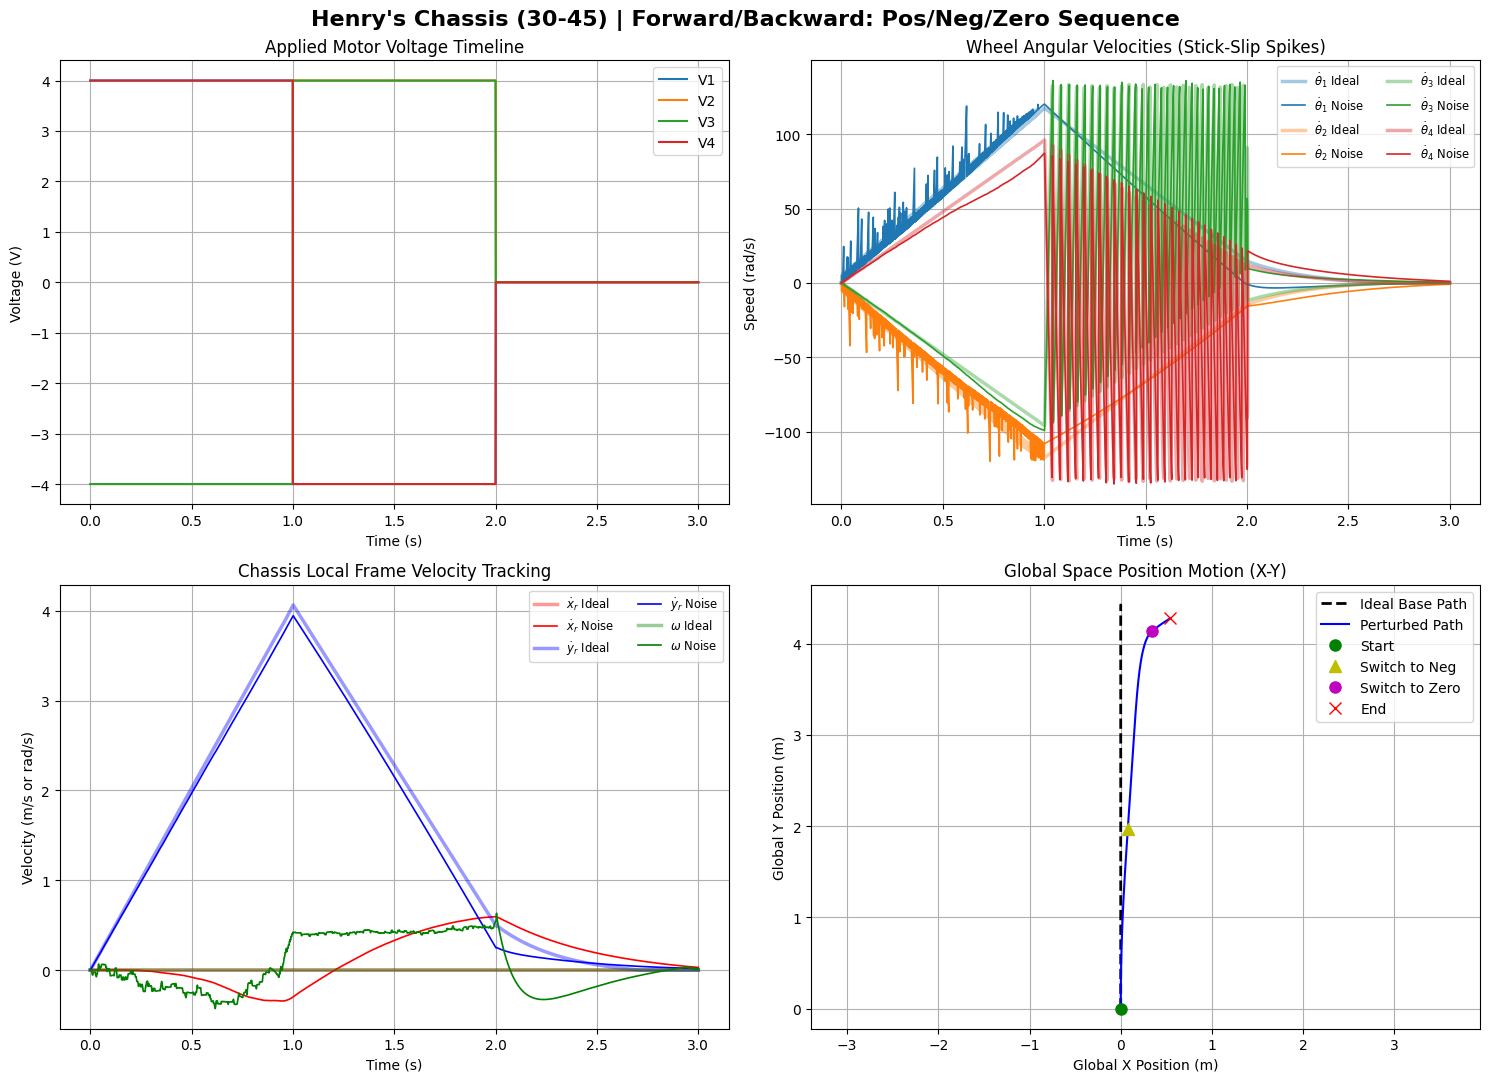

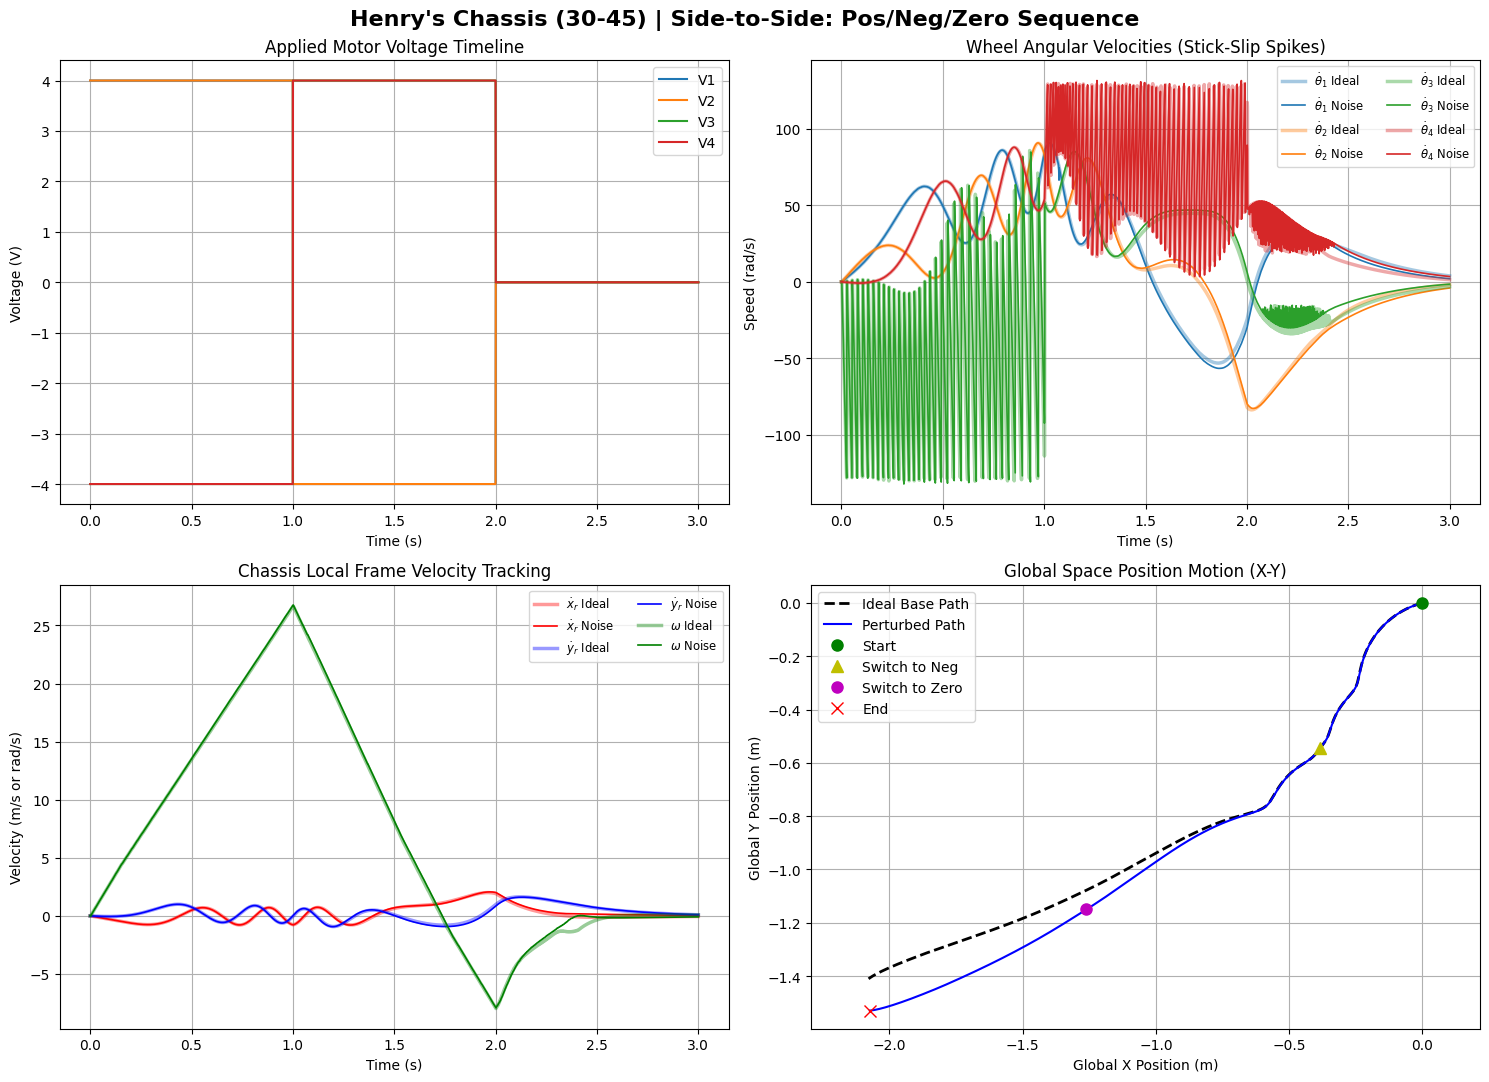

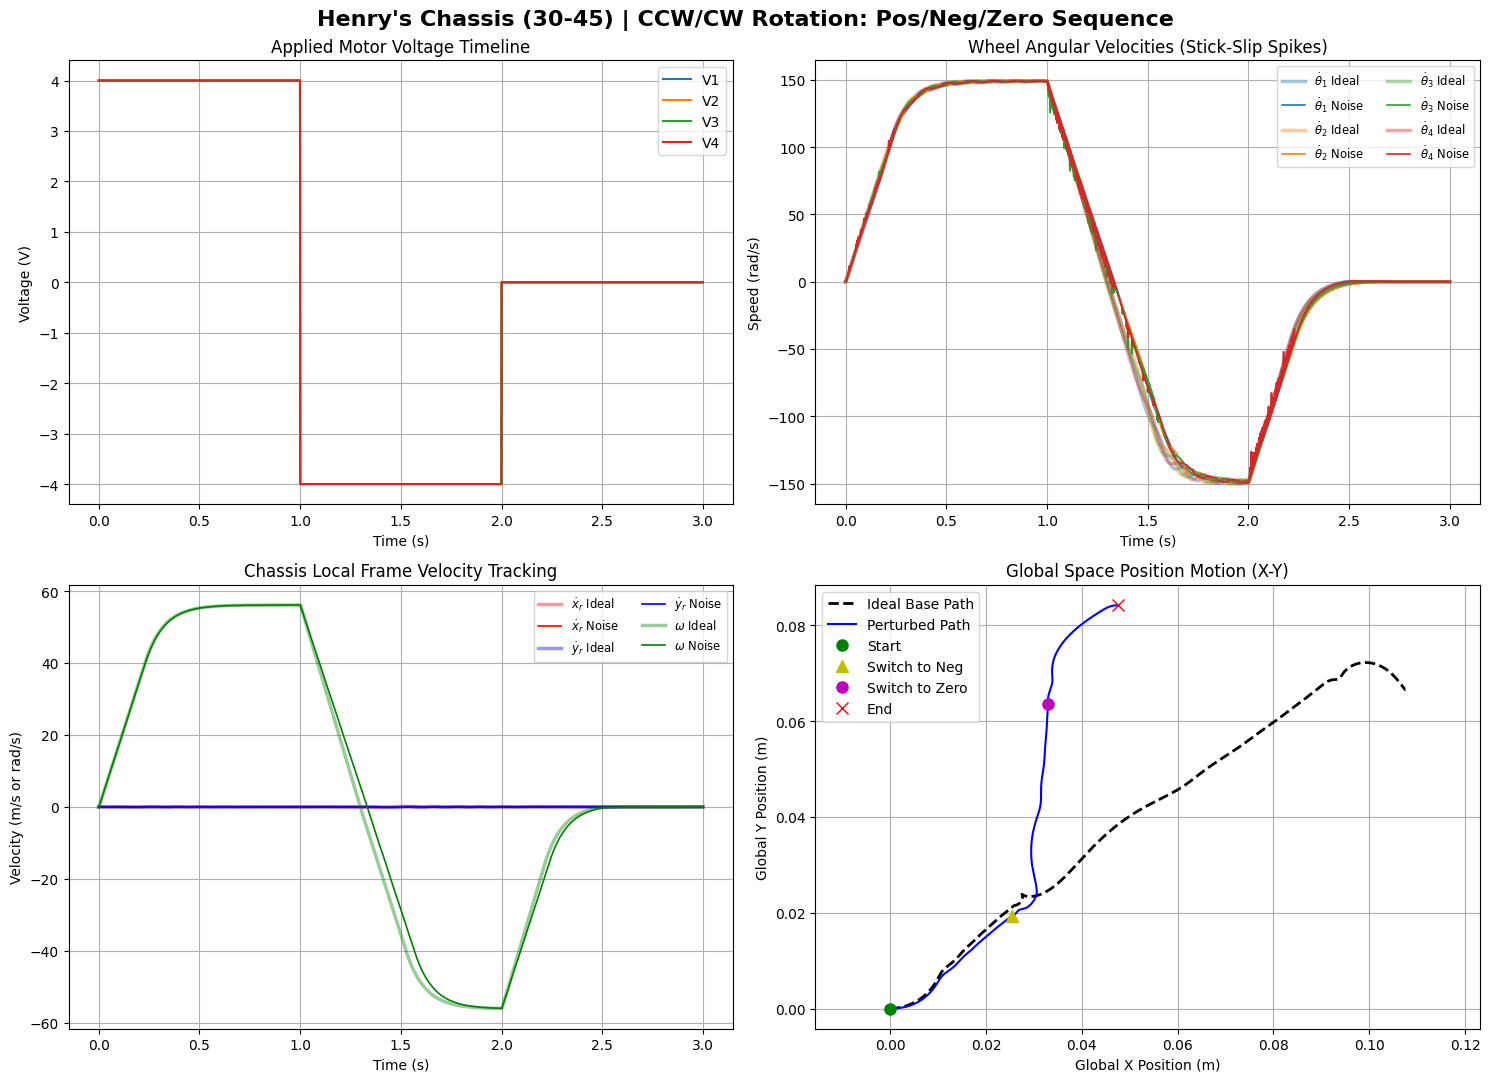

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Save your configured noise parameters to toggle the passes cleanly
nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

# Define a 3.0 second timeline split into three distinct 1.0s intervals
t_stage = 1.0
dt = simulation_parameters['dt']
steps_per_stage = int(t_stage / dt)
total_steps = steps_per_stage * 3
t_vec = np.linspace(0, t_stage * 3, total_steps)

# Helper function to dynamically generate the voltage vector at any given step index k
def get_profile_voltage(test_type, step_idx, steps_per_stage):
    # Determine which chronological stage we are currently executing
    if step_idx < steps_per_stage:
        stage = "Positive"
        mag = 4.0
    elif step_idx < 2 * steps_per_stage:
        stage = "Negative"
        mag = -4.0
    else:
        stage = "Zero"
        mag = 0.0
        
    # Apply your verified hardware directional sign combinations scaled by stage magnitude
    if test_type == "Forward/Backward":
        return np.array([mag, -mag, -mag, mag])
    elif test_type == "Side-to-Side":
        return np.array([mag, mag, -mag, -mag])
    elif test_type == "CCW/CW Rotation":
        return np.array([mag, mag, mag, mag])
    return np.zeros(4)

# Define our three complex multi-stage test scenarios
test_scenarios = ["Forward/Backward", "Side-to-Side", "CCW/CW Rotation"]

# Plotting configuration styles
style_ideal = {'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'alpha': 1.0, 'lw': 1.2}  

# =======================================================================
# STRUCTURAL RUN 1: HENRY'S 30-45 CONFIGURATION WITH PROFILE MANEUVERS
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(rc.WHEEL_ALPHA_DEG[0])  # Henry's layout: 30 deg CCW from +x_r
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Profile Tests under Henry's 30-45 layout Geometry...")

for test_name in test_scenarios:
    runs_data = {}
    
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, theta_dot_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        # Step through the full 3.0 second timeline
        for k in range(total_steps):
            V_cmd = get_profile_voltage(test_name, k, steps_per_stage)
            
            v_in_hist.append(V_cmd.copy())
            theta_dot_hist.append(state.theta_dot.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            
            state, T_load, S_status = robot_plant.step(state, V_cmd)
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "theta_dot": np.array(theta_dot_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    # -------------------------------------------------------------------
    # GENERATE 2x2 GRAPHS FOR COMPLEX PROFILE COUPLING
    # -------------------------------------------------------------------
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Henry's Chassis (30-45) | {test_name}: Pos/Neg/Zero Sequence", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Profiles (Now showing step changes over time)
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Voltage Timeline")
    axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds showing spikes during aggressive direction switches
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["theta_dot"][:, w], color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["theta_dot"][:, w], color=f'C{w}', label=r'$\dot{\theta}_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities (Stick-Slip Spikes)"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Velocities showing Braking/Deceleration Curves
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\omega$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\omega$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Velocity Tracking"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane showing bidirectional path trace
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][steps_per_stage, 0], noisy["pos_global"][steps_per_stage, 1], 'y^', markersize=8, label='Switch to Neg')
    axs[1, 1].plot(noisy["pos_global"][2*steps_per_stage, 0], noisy["pos_global"][2*steps_per_stage, 1], 'mo', markersize=8, label='Switch to Zero')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Space Position Motion (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Restore baseline parameters securely
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu

# ➕ Added A: logging and diagnostic plots

`run_logged(plant, voltage_fn, duration)` steps any plant (Dana's class or the extended one) with a voltage schedule and records everything the step computes. Dana's tests record only the voltage, ω, chassis velocity, and pose; this also records:

- per-wheel normal load $F_n$, floor force, motor torque, load torque, and slip flag;
- applied voltage (after the driver limits) and current;
- the rolling speed $(\mathbf H\dot{\mathbf X}_r)_i / r$ next to the actual wheel speed $\dot\theta_i$, and the rim slip $r\dot\theta_i - (\mathbf H\dot{\mathbf X}_r)_i$;
- the roller (a-axis) force when that option is on.

`plot_diagnostics(log, title)` draws them on one 4×2 page. Nothing here changes the dynamics.

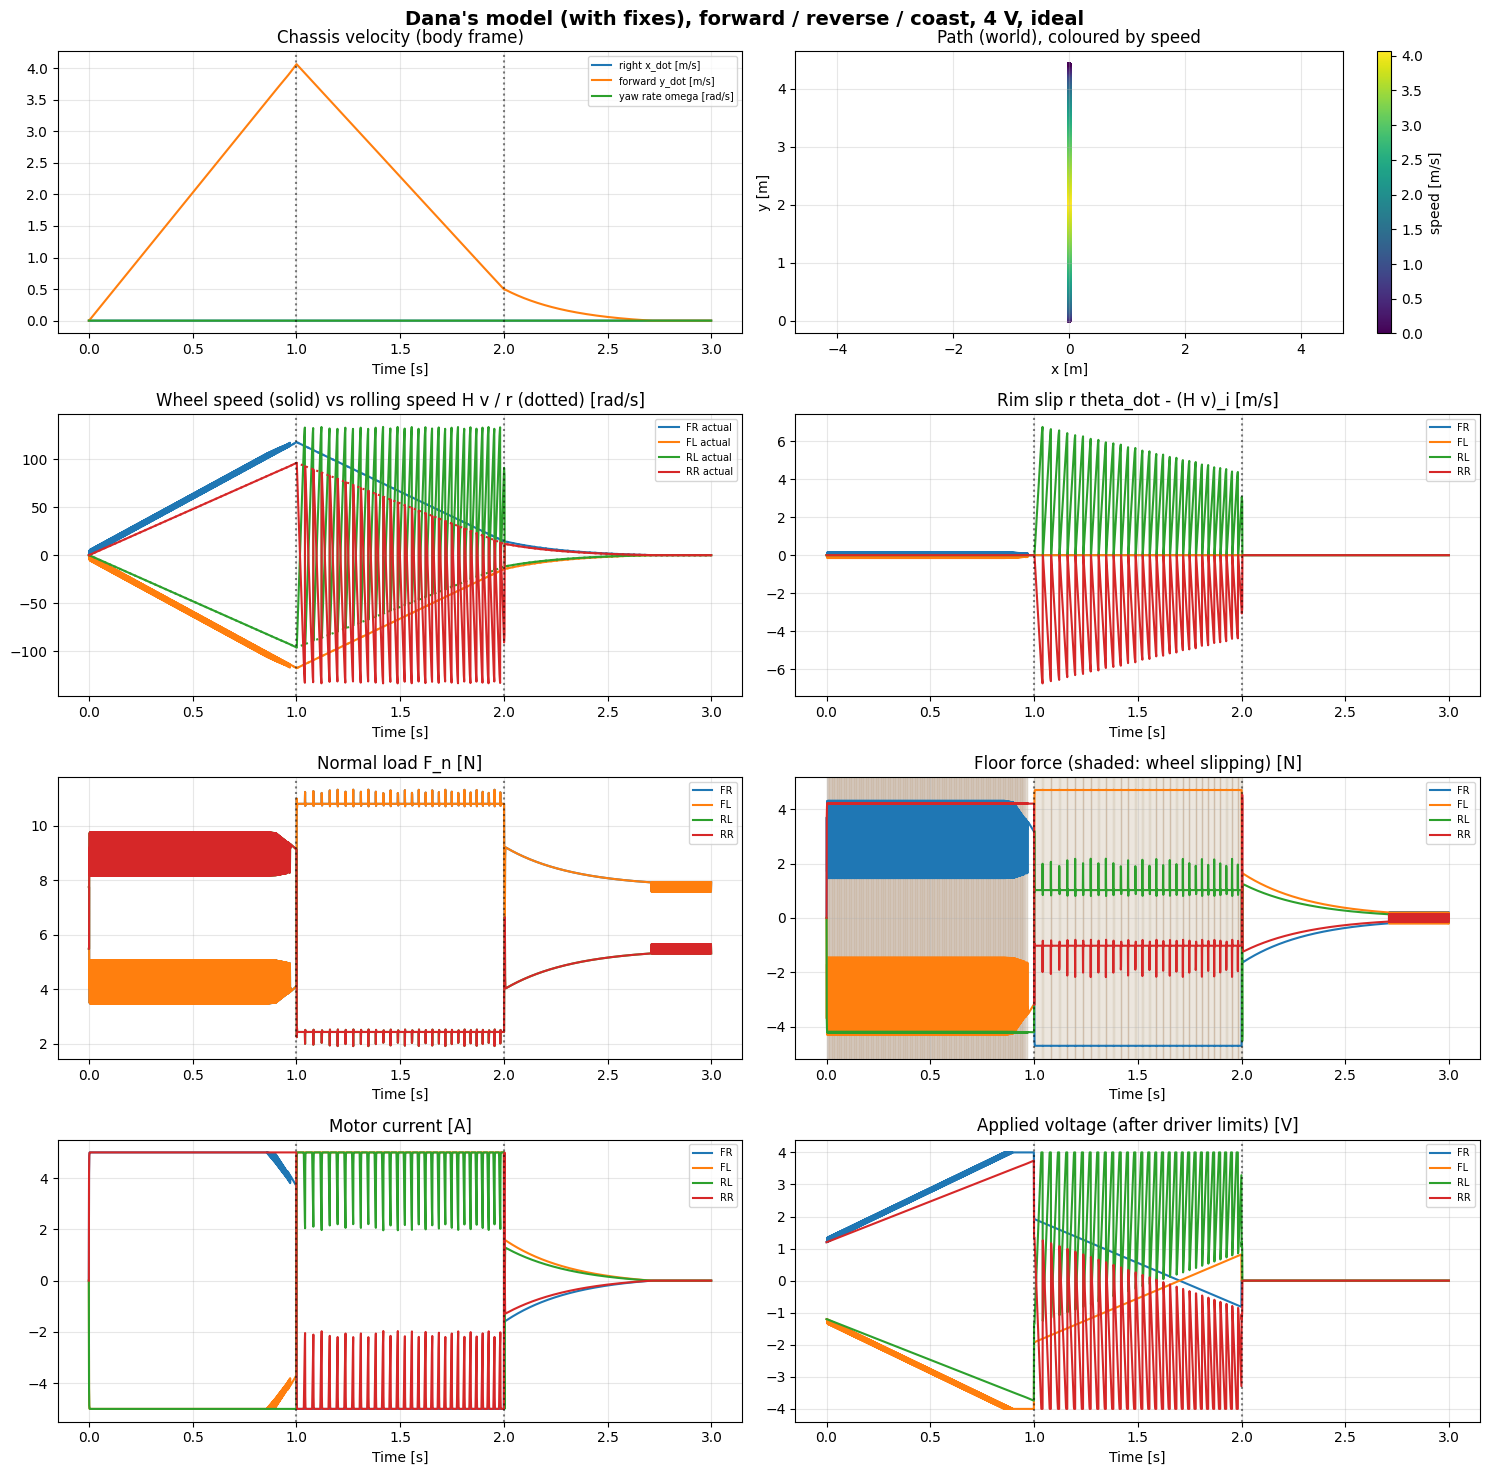

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def run_logged(plant, voltage_fn, duration):
    """Step a plant with voltage_fn(t) -> 4 voltages for duration seconds; return a dict of arrays."""
    state = OmniMotorState()
    n = int(round(duration / plant.dt))
    keys = ("t", "V_cmd", "V_applied", "I", "theta_dot", "theta_dot_rolling", "rim_slip", "v_local", "pos",
            "F_n", "F_floor", "T_m", "T_load", "S", "F_roller", "a_local")
    log = {key: [] for key in keys}
    for k in range(n):
        t = k * plant.dt
        V = np.asarray(voltage_fn(t), dtype=float)
        rolling = plant.H @ state.v_local
        log["t"].append(t); log["V_cmd"].append(V); log["theta_dot"].append(state.theta_dot.copy())
        log["theta_dot_rolling"].append(rolling / plant.p['r'])
        log["rim_slip"].append(plant.p['r'] * state.theta_dot - rolling)
        log["v_local"].append(state.v_local.copy()); log["pos"].append(state.pos_global.copy())
        log["I"].append(state.I.copy())
        state, _, _ = plant.step(state, V)
        last = plant.last
        for key in ("V_applied", "F_n", "F_floor", "T_m", "T_load", "S", "a_local"):
            log[key].append(np.array(last[key], dtype=float))
        log["F_roller"].append(np.array(getattr(plant, "_roller_force", np.zeros(4)), dtype=float))
    out = {key: np.array(value) for key, value in log.items()}
    out["final_state"] = state
    return out

WHEELS = ("FR", "FL", "RL", "RR")

def plot_diagnostics(log, title, marks=()):
    """One-page diagnostics: chassis response, path, wheel speeds vs rolling speed, slip, loads, effort."""
    t = log["t"]
    fig, ax = plt.subplots(4, 2, figsize=(15, 15))
    ax[0, 0].plot(t, log["v_local"][:, 0], label="right x_dot [m/s]")
    ax[0, 0].plot(t, log["v_local"][:, 1], label="forward y_dot [m/s]")
    ax[0, 0].plot(t, log["v_local"][:, 2], label="yaw rate omega [rad/s]")
    ax[0, 0].set_title("Chassis velocity (body frame)")
    sc = ax[0, 1].scatter(log["pos"][:, 0], log["pos"][:, 1], c=np.hypot(log["v_local"][:, 0], log["v_local"][:, 1]),
                          s=4, cmap="viridis")
    fig.colorbar(sc, ax=ax[0, 1], label="speed [m/s]")
    ax[0, 1].set(title="Path (world), coloured by speed", xlabel="x [m]", ylabel="y [m]")
    ax[0, 1].axis("equal")
    for i in range(4):
        line, = ax[1, 0].plot(t, log["theta_dot"][:, i], label=f"{WHEELS[i]} actual")
        ax[1, 0].plot(t, log["theta_dot_rolling"][:, i], ":", color=line.get_color())
    ax[1, 0].set_title("Wheel speed (solid) vs rolling speed H v / r (dotted) [rad/s]")
    for i in range(4):
        ax[1, 1].plot(t, log["rim_slip"][:, i], label=WHEELS[i])
    ax[1, 1].set_title("Rim slip r theta_dot - (H v)_i [m/s]")
    for i in range(4):
        ax[2, 0].plot(t, log["F_n"][:, i], label=WHEELS[i])
    ax[2, 0].set_title("Normal load F_n [N]")
    for i in range(4):
        ax[2, 1].plot(t, log["F_floor"][:, i], label=WHEELS[i])
        ax[2, 1].fill_between(t, 0, 1, where=log["S"][:, i] > 0, color=f"C{i}", alpha=0.08,
                              transform=ax[2, 1].get_xaxis_transform())
    ax[2, 1].set_title("Floor force (shaded: wheel slipping) [N]")
    for i in range(4):
        ax[3, 0].plot(t, log["I"][:, i], label=WHEELS[i])
    ax[3, 0].set_title("Motor current [A]")
    for i in range(4):
        ax[3, 1].plot(t, log["V_applied"][:, i], label=WHEELS[i])
    ax[3, 1].set_title("Applied voltage (after driver limits) [V]")
    for a in ax.flat:
        a.grid(True, alpha=0.3)
        if a.get_legend_handles_labels()[0]:
            a.legend(fontsize=7, loc="best")
        if a is not ax[0, 1]:
            a.set_xlabel("Time [s]")
            for m in marks:
                a.axvline(m, color="k", ls=":", alpha=0.5)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

# Example: the forward / reverse / coast sequence from Dana's last test, on her model with the fixes.
def forward_reverse_coast(t, magnitude=4.0):
    mag = magnitude if t < 1.0 else (-magnitude if t < 2.0 else 0.0)
    return np.array([mag, -mag, -mag, mag])

example = run_logged(OmniRobotSimulation(dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)),
                     forward_reverse_coast, 3.0)
plot_diagnostics(example, "Dana's model (with fixes), forward / reverse / coast, 4 V, ideal", marks=(1.0, 2.0))

# ➕ Added B: extra verification checks

On top of the verification cell above:

1. **Timestep convergence:** the same forward run at dt = 1, 0.5, and 0.25 ms; position and speed after 1 s should agree.
2. **Energy audit:** electrical energy in, $\int \sum V_i i_i\,dt$, against what it became: winding heat $\int R i^2$, kinetic energy (chassis plus wheels), magnetic energy $\tfrac12 L i^2$, rolling resistance, and sliding friction $\int F\,(r\dot\theta - v)$. Forward Euler leaves a residual; it should be small.
3. **Per-wheel signs:** a positive voltage on one wheel alone must push the chassis along that wheel's drive direction and spin that wheel positive.
4. **Braking chatter detector:** the number of slip/stick toggles per wheel during the reverse phase of the forward/reverse/coast test. Dana's friction model toggles every few steps; a clean model should toggle only a few times.

In [10]:
vp = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
forward_2v = lambda t: np.array([2.0, -2.0, -2.0, 2.0])

# 1. Timestep convergence.
print("1) timestep convergence, forward 2 V for 1 s:")
ref = None
for dt in (1e-3, 5e-4, 2.5e-4):
    lg = run_logged(OmniRobotSimulation(dict(vp, dt=dt)), forward_2v, 1.0)
    end = lg["final_state"]
    print(f"   dt = {dt * 1e3:.2f} ms: y (forward) = {end.pos_global[1]:.5f} m, forward speed = {end.v_local[1]:.5f} m/s")
    ref = (end.pos_global[1], dt) if ref is None or dt < ref[1] else ref
print("   (the finest step is the reference; differences shrink with dt for a consistent model)")

# 2. Energy audit.
def energy_audit(plant, voltage_fn, duration):
    lg = run_logged(plant, voltage_fn, duration)
    dt, p = plant.dt, plant.p
    E_in = np.sum(lg["V_applied"] * lg["I"]) * dt
    heat = np.sum(p['R'] * lg["I"] ** 2) * dt
    end = lg["final_state"]
    kinetic = 0.5 * p['Mr'] * float(end.v_local[:2] @ end.v_local[:2]) + 0.5 * p['Jzz'] * end.v_local[2] ** 2 \
              + 0.5 * p['Jw'] * float(end.theta_dot @ end.theta_dot)
    magnetic = 0.5 * p['Lm'] * float(end.I @ end.I)
    rolling_loss = np.sum(np.abs(np.sign(lg["theta_dot"]) * p['Crr'] * lg["F_n"] * p['r'] * lg["theta_dot"])) * dt
    sliding_loss = np.sum(np.where(lg["S"] > 0, np.abs(lg["F_floor"] * lg["rim_slip"]), 0.0)) * dt
    accounted = heat + kinetic + magnetic + rolling_loss + sliding_loss
    return E_in, heat, kinetic, magnetic, rolling_loss, sliding_loss, accounted

E = energy_audit(OmniRobotSimulation(vp), forward_2v, 1.0)
print(f"2) energy audit, forward 2 V for 1 s: in {E[0]:.3f} J; heat {E[1]:.3f}, kinetic {E[2]:.3f}, magnetic {E[3]:.5f}, "
      f"rolling {E[4]:.3f}, sliding {E[5]:.3f} J; unaccounted {E[0] - E[6]:+.3f} J ({100 * (E[0] - E[6]) / E[0]:+.1f}%)")

# 3. Per-wheel signs.
print("3) per-wheel signs, +2 V on one wheel for 20 ms:")
for i in range(4):
    V = np.zeros(4); V[i] = 2.0
    lg = run_logged(OmniRobotSimulation(vp), lambda t, V=V: V, 0.02)
    v = lg["final_state"].v_local
    drive = OmniRobotSimulation(vp).H[i, :2]
    along = float(v[:2] @ drive)
    print(f"   {WHEELS[i]}: chassis velocity {v} (along its drive direction {along:+.4f} m/s), "
          f"wheel speed {lg['final_state'].theta_dot[i]:+.2f} rad/s")
    assert along > 0 and lg["final_state"].theta_dot[i] > 0, "A positive voltage must push along +d and spin the wheel positive"
print("   PASS: each wheel pushes along its own +d and spins positive")

# 4. Braking chatter detector.
def chatter_count(log, start=1.0, stop=2.0):
    window = (log["t"] >= start) & (log["t"] < stop)
    flags = log["S"][window] > 0
    return np.sum(np.abs(np.diff(flags.astype(int), axis=0)), axis=0)

toggles = chatter_count(run_logged(OmniRobotSimulation(vp), forward_reverse_coast, 3.0))
print(f"4) slip/stick toggles per wheel during the reverse phase (Dana's friction): {dict(zip(WHEELS, toggles))}")

1) timestep convergence, forward 2 V for 1 s:
   dt = 1.00 ms: y (forward) = 1.66849 m, forward speed = 2.58818 m/s
   dt = 0.50 ms: y (forward) = 1.66778 m, forward speed = 2.58748 m/s
   dt = 0.25 ms: y (forward) = 1.66742 m, forward speed = 2.58716 m/s
   (the finest step is the reference; differences shrink with dt for a consistent model)
2) energy audit, forward 2 V for 1 s: in 21.873 J; heat 11.337, kinetic 9.192, magnetic 0.00033, rolling 0.865, sliding 0.000 J; unaccounted +0.480 J (+2.2%)
3) per-wheel signs, +2 V on one wheel for 20 ms:
   FR: chassis velocity [-0.01621961  0.02663586  0.69986372] (along its drive direction +0.0312 m/s), wheel speed +2.90 rad/s
   FL: chassis velocity [-0.01551223 -0.02704983  0.69978082] (along its drive direction +0.0312 m/s), wheel speed +2.90 rad/s
   RL: chassis velocity [ 0.02218748 -0.02162929  0.6958118 ] (along its drive direction +0.0310 m/s), wheel speed +2.88 rad/s
   RR: chassis velocity [0.0216091  0.02220114 0.69587947] (along i

# ➕ Added C: the four fixes, one at a time

Each fix in the class above has a switch (`fix_normal_forces`, `fix_rotating_frame`, `fix_exact_current`, `motor_limits`). All four off reproduces Dana's original exactly. (The geometry needs no switch: in these axes Dana's $\mathbf H$ is already correct.) This cell runs the forward/reverse/coast test with all fixes, with each one turned off in turn, and with all off. Each row shows what that single fix changes.

In [11]:
base = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
FIXES = ("fix_normal_forces", "fix_rotating_frame", "fix_exact_current", "motor_limits")
cases = {"all fixes on": {}}
cases.update({f"{name} off": {name: False} for name in FIXES})
cases["all off (Dana's original)"] = {name: False for name in FIXES}
print(f"{'case':28s} {'end x [m]':>10s} {'end y [m]':>10s} {'heading [deg]':>14s} {'peak |I| [A]':>13s} {'reverse toggles':>16s}")
for name, switches in cases.items():
    lg = run_logged(OmniRobotSimulation(dict(base, **switches)), forward_reverse_coast, 3.0)
    end = lg["final_state"].pos_global
    print(f"{name:28s} {end[0]:10.3f} {end[1]:10.3f} {np.degrees(end[2]):14.2f} {np.max(np.abs(lg['I'])):13.2f} "
          f"{int(chatter_count(lg).sum()):16d}")

case                          end x [m]  end y [m]  heading [deg]  peak |I| [A]  reverse toggles
all fixes on                      0.000      4.426          -0.00          5.00              118
fix_normal_forces off             0.403      0.770       -4615.62          5.00              328
fix_rotating_frame off           -0.000      4.426           0.00          5.00              118
fix_exact_current off             0.000      4.396          -0.00         13.05              138
motor_limits off                 -0.000      4.027           0.00         29.20              776
all off (Dana's original)         0.013      0.092       -4602.78         64.45              505


# ➕ Added D: switchable options from Henry's model (`OmniRobotSimulationExtended`)

The class below adds Henry's modelling options to Dana's plant. Each option is a key in the parameters dictionary. With none of them set, it gives exactly the same results as `OmniRobotSimulation` (checked at the end of this cell).

| Option | Default (Dana) | Alternative |
|---|---|---|
| `wheel_geometry` | `'tangential'` | `'robot_constants'`: positions from `WHEEL_POSITION_DEG`, directions from `WHEEL_ALPHA_DEG`, so the wheels can be non-tangential; yaw lever $\mathbf r_i\times\hat{\mathbf d}_i$ |
| `roller_friction` | `False` | `True`: Henry's a-axis roller friction $-N\mu_a(v_a)\tfrac{2}{\pi}\arctan(K v_a)$ along each roller axis |
| `wheel_inertia_in_stick` | `False` | `True`: a sticking wheel's force includes $J_w\ddot\theta$ (from the previous step's acceleration) |
| `wheel_losses` | `'dana'`: $C_{rr}Nr\,\mathrm{sign}(\dot\theta)$ | `'smoothed'`: $C_{rr}Nr\tanh(\dot\theta/\varepsilon) + b_w\dot\theta$ |
| `drive_friction` | `'dana'`: stick if $|F_{req}|\le\mu_sN$, else $\mathrm{sign}(F_{req})\mu_kN$ | `'slip_velocity'`: once sliding, stay sliding until the rim matches the ground; the force opposes the slip and follows the Stribeck curve. `'lugre'`: bristle model with Henry's parameters, sub-stepped at `lugre_dt` |
| `disturbance_model` | `'dana'`: white noise on $N$ and $\mu$ every step | `'henry'`: smooth load vibration on $N$ (grows with out-of-roundness × speed², and with wheel acceleration; sum kept) and a fixed per-wheel friction offset |
| `cog_offset` | `False` | `True`: centre of gravity at the CAD position (10.2 mm forward); loads balance about it and the chassis accelerates about it |

In [12]:
# ADDED: extended model. Every option below defaults to Dana's behaviour, so with no option keys
# in the parameters this class gives exactly the same results as OmniRobotSimulation.
import numpy as np
import robot_constants as rc

EXTENDED_DEFAULTS = {
    'wheel_geometry': 'tangential',     # or 'robot_constants': positions WHEEL_POSITION_DEG, directions WHEEL_ALPHA_DEG (CCW from +x)
    'roller_friction': False,           # a-axis roller friction, Henry's mu_a law
    'wheel_inertia_in_stick': False,    # sticking force includes J_w * wheel acceleration
    'wheel_losses': 'dana',             # or 'smoothed': C_rr N r tanh(theta_dot / eps) + b_w theta_dot
    'drive_friction': 'dana',           # or 'slip_velocity' (stay sliding until the rim matches the ground), or 'lugre'
    'disturbance_model': 'dana',        # or 'henry': load vibration on N + fixed per-wheel friction offset
    'cog_offset': False,                # centre of gravity at the CAD position instead of the base centre
    'lugre_dt': 2e-5,                   # LuGre internal sub-step [s] (the bristles are stiff)
}


class OmniRobotSimulationExtended(OmniRobotSimulation):
    """Dana's plant plus switchable options from Henry's model (see EXTENDED_DEFAULTS)."""

    def __init__(self, params: dict, random_seed: int = 42):
        super().__init__(params, random_seed)
        self.opt = {key: params.get(key, value) for key, value in EXTENDED_DEFAULTS.items()}

        # Option: non-tangential wheel geometry from robot_constants (same axes: x right, y forward).
        # Position beta_i from WHEEL_POSITION_DEG, roller axis a_i = (cos alpha_i, sin alpha_i) and drive
        # direction d_i = (-sin alpha_i, cos alpha_i) from WHEEL_ALPHA_DEG. Equal arrays: tangential.
        if self.opt['wheel_geometry'] == 'robot_constants':
            alpha = np.radians(np.asarray(rc.WHEEL_ALPHA_DEG, dtype=float))
            beta = np.radians(np.asarray(rc.WHEEL_POSITION_DEG, dtype=float))
            drive = np.column_stack((-np.sin(alpha), np.cos(alpha)))
            self.wheel_xy = self.p['Rb'] * np.column_stack((np.cos(beta), np.sin(beta)))
            self.roller_dirs = np.column_stack((np.cos(alpha), np.sin(alpha)))
            levers = self.wheel_xy[:, 0] * drive[:, 1] - self.wheel_xy[:, 1] * drive[:, 0]
            self.H = np.column_stack((drive, levers))
            self.load_positions = self.wheel_xy.copy()
        elif self.opt['wheel_geometry'] != 'tangential':
            raise ValueError("wheel_geometry must be 'tangential' or 'robot_constants'")

        # Option: centre of gravity at the CAD position (x right, y forward, from the base centre P).
        self.cog = np.zeros(2)
        if self.opt['cog_offset']:
            self.cog = np.array([rc.COG_X_MM, rc.COG_Y_MM]) * 1e-3
            self.load_positions = self.wheel_xy - self.cog
        self.J_cog = self.p['Jzz'] - self.p['Mr'] * float(self.cog @ self.cog)

        # Option: Henry's disturbance models (load vibration on N, fixed per-wheel friction offset).
        self.friction_scale = np.ones(4)
        if self.opt['disturbance_model'] == 'henry':
            self.friction_scale = 1.0 + rc.FRICTION_OFFSET_STD * self.rng.normal(size=4)
            self._vib_noise = np.zeros(4)
            self._vib_accel = np.zeros(4)
            self._vib_prev_theta_dot = None
        elif self.opt['disturbance_model'] != 'dana':
            raise ValueError("disturbance_model must be 'dana' or 'henry'")

        self._roller_wrench = np.zeros(3)
        self._roller_force = np.zeros(4)
        self._slip_dir = np.zeros(4)    # slip direction remembered at breakaway (slip_velocity option)
        self._slip_peak = np.zeros(4)   # largest slip in that direction since breakaway
        self.lugre_z = np.zeros(4)     # LuGre bristle deflection per wheel [m]

    # ---- normal loads ---------------------------------------------------------------------------
    def compute_dynamic_normal_forces(self, state):
        if self.opt['disturbance_model'] == 'dana':
            return super().compute_dynamic_normal_forces(state)
        saved = self.p['sigma_V']
        self.p['sigma_V'] = 0.0
        try:
            N = super().compute_dynamic_normal_forces(state)
        finally:
            self.p['sigma_V'] = saved
        # Henry's load vibration: g_i = 1 + a_i n_i, rescaled so the four loads keep their sum.
        dt = self.dt
        theta_dot = state.theta_dot
        raw = np.zeros(4) if self._vib_prev_theta_dot is None else np.abs(theta_dot - self._vib_prev_theta_dot) / dt
        self._vib_prev_theta_dot = theta_dot.copy()
        self._vib_accel += (1.0 - np.exp(-dt / rc.LOAD_VIBRATION_ACCEL_FILTER_TIME)) * (raw - self._vib_accel)
        speed = np.hypot(np.hypot(*state.v_local[:2]), self.p['Rb'] * state.v_local[2])
        geometric = (rc.LOAD_VIBRATION_COMPLIANCE * 0.5 * rc.WHEEL_ENVELOPE_IRREGULARITY
                     * (rc.N_ROLLERS * speed / self.p['r']) ** 2 / rc.GRAVITY)
        amplitude = np.minimum(rc.LOAD_VIBRATION_MAX, (rc.LOAD_VIBRATION_BASE + geometric)
                               * (1.0 + rc.LOAD_VIBRATION_ACCEL_GAIN * self._vib_accel / rc.LOAD_VIBRATION_REF_ACCEL))
        persistence = np.exp(-dt / rc.LOAD_VIBRATION_CORRELATION_TIME)
        self._vib_noise = persistence * self._vib_noise + np.sqrt(1 - persistence**2) * self.rng.normal(size=4)
        scaled = N * (1.0 + amplitude * np.clip(self._vib_noise, -1.0, 1.0))
        return scaled * (N.sum() / scaled.sum()) if scaled.sum() > 0 else scaled

    # ---- contact ---------------------------------------------------------------------------------
    def _wheel_losses(self, theta_dot, F_n):
        r, Crr = self.p['r'], self.p['Crr']
        if self.opt['wheel_losses'] == 'smoothed':
            return (Crr * F_n * r * np.tanh(theta_dot / rc.WHEEL_LOSS_SMOOTHING_SPEED)
                    + rc.WHEEL_BEARING_VISCOUS_DRAG * theta_dot)
        return np.sign(theta_dot) * Crr * F_n * r

    def _roller_friction(self, state, F_n, mu_scale):
        """Henry's a-axis law: F_a = -N mu_a(v_a) (2/pi) atan(K v_a), along each roller axis."""
        if not self.opt['roller_friction']:
            self._roller_wrench, self._roller_force = np.zeros(3), np.zeros(4)
            return
        vx, vy, w = state.v_local      # x right, y forward, w = yaw rate omega
        contact = np.column_stack((vx - w * self.wheel_xy[:, 1], vy + w * self.wheel_xy[:, 0]))
        v_a = np.sum(contact * self.roller_dirs, axis=1)
        mu_a = rc.MU_A_DYN + (rc.MU_A_STAT - rc.MU_A_DYN) * np.exp(-rc.ALPHA_A * np.abs(v_a))
        F_a = -mu_scale * F_n * mu_a * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_A * v_a)
        vec = self.roller_dirs * F_a[:, None]
        moment = np.sum(self.wheel_xy[:, 0] * vec[:, 1] - self.wheel_xy[:, 1] * vec[:, 0])
        self._roller_force = F_a
        self._roller_wrench = np.array([vec[:, 0].sum(), vec[:, 1].sum(), moment])

    def compute_contact_friction_interface(self, T_m, F_n, state):
        opt = self.opt
        default = (opt['wheel_losses'] == 'dana' and opt['drive_friction'] == 'dana'
                   and not opt['wheel_inertia_in_stick'] and opt['disturbance_model'] == 'dana')
        if default:
            out = super().compute_contact_friction_interface(T_m, F_n, state)
            self._roller_friction(state, F_n, np.ones(4))
            return out
        r, Jw = self.p['r'], self.p['Jw']
        if opt['disturbance_model'] == 'henry':
            mu_scale = self.friction_scale
        else:
            w_mu = self.rng.normal(0.0, self.p['sigma_mu'], 4) if self.p['sigma_mu'] > 0 else np.zeros(4)
            mu_scale = 1.0 + w_mu / max(self.p['mu_s'], 1e-12)   # Dana's additive noise, as a scale on mu_s
        mu_s = np.maximum(0.0, self.p['mu_s'] * mu_scale)
        mu_k_nom = np.maximum(0.0, self.p['mu_k'] * mu_scale)
        T_roll = self._wheel_losses(state.theta_dot, F_n)
        wheel_accel = (self.H @ state.a_local_past) / r if opt['wheel_inertia_in_stick'] else np.zeros(4)
        F_req = (T_m - T_roll - Jw * wheel_accel) / r
        F_max_static = mu_s * F_n

        if opt['drive_friction'] == 'slip_velocity':
            # A wheel that breaks away remembers its slip direction (the sign of the force it needed).
            # It stays sliding until its rim slip, measured in that direction, has come back to zero
            # after building up past the band, or has reversed past the band. The kinetic force opposes
            # the slip and follows the Stribeck curve mu_k + (mu_s - mu_k) exp(-ALPHA_D |v|).
            v_slip = r * state.theta_dot - self.H @ state.v_local
            band = rc.DRIVE_BREAKAWAY_BAND
            along = self._slip_dir * v_slip
            self._slip_peak = np.where(state.S, np.maximum(self._slip_peak, along), 0.0)
            restick = state.S & (((self._slip_peak > band) & (along <= 0.0)) | (along < -band))
            keep = state.S & ~restick
            breakaway = ~state.S & (np.abs(F_req) > F_max_static)
            S_status = keep | breakaway
            self._slip_dir = np.where(breakaway, np.sign(F_req), self._slip_dir)
            self._slip_peak = np.where(breakaway, 0.0, self._slip_peak)
            mu_v = mu_k_nom + (mu_s - mu_k_nom) * np.exp(-rc.ALPHA_D * np.abs(v_slip))
            direction = np.where(keep & (np.abs(v_slip) > 1e-9), np.sign(v_slip), self._slip_dir)
        elif opt['drive_friction'] == 'dana':
            S_status = np.abs(F_req) > F_max_static
            mu_v, direction = mu_k_nom, np.sign(F_req)
        else:
            raise ValueError("drive_friction must be 'dana', 'slip_velocity', or 'lugre' (lugre uses step())")
        F_floor = np.where(S_status, direction * mu_v * F_n, F_req)
        T_load = np.where(S_status, F_floor * r + T_roll, T_m)
        self._roller_friction(state, F_n, mu_scale)
        return F_floor, T_load, S_status

    # ---- chassis ---------------------------------------------------------------------------------
    def chassis_acceleration(self, F_floor, state):
        wrench = self.H.T @ F_floor + self._roller_wrench
        if not self.opt['cog_offset']:
            return self.M_inv @ wrench
        # CoG at c from P: the CoG accelerates at F/m; alpha from the moment about the CoG; the base
        # centre P (the tracked point) then accelerates at a_c - alpha x c + omega^2 c.
        m, (cx, cy), w = self.p['Mr'], self.cog, state.v_local[2]
        a_c = wrench[:2] / m
        alpha = (wrench[2] - (cx * wrench[1] - cy * wrench[0])) / self.J_cog
        a_P = a_c - alpha * np.array([-cy, cx]) + w**2 * self.cog
        return np.array([a_P[0], a_P[1], alpha])

    # ---- LuGre step ------------------------------------------------------------------------------
    def step(self, current_state, V_input):
        if self.opt['drive_friction'] != 'lugre':
            return super().step(current_state, V_input)
        # LuGre (Canudas de Wit et al. 1995), Henry's parameters: one bristle deflection z per wheel,
        #   dz/dt = s - sigma0 |s|_c z / g(s),   F = sigma0 z + sigma1(s) dz/dt,   g(s) = mu(|s|) N,
        # s = r theta_dot - (H v)_i the rim slip, |s|_c = sqrt(s^2 + creep^2). The wheels are never snapped:
        # each one integrates J_w theta_ddot = T_m - T_roll - r F. The bristles are stiff, so the step is
        # split into sub-steps of lugre_dt, with a semi-implicit z update.
        r, Jw, outer_dt = self.p['r'], self.p['Jw'], self.dt
        n = max(1, int(np.ceil(outer_dt / self.opt['lugre_dt'])))
        h = outer_dt / n
        delta, ratio, damping_slip, creep = 2e-6, 1.0, 5e-3, 1e-4
        state = current_state
        F_n = self.compute_dynamic_normal_forces(state)            # sampled once per outer step
        mu_scale = self.friction_scale
        mu_s = self.p['mu_s'] * mu_scale
        mu_k = self.p['mu_k'] * mu_scale
        z = self.lugre_z
        self.dt = h
        try:
            for _ in range(n):
                T_m = self.compute_electrical_subsystem(state, V_input)
                s = r * state.theta_dot - self.H @ state.v_local
                g_s = np.maximum((mu_k + (mu_s - mu_k) * np.exp(-rc.ALPHA_D * np.abs(s))) * F_n, 1e-9)
                sigma0 = np.maximum(mu_s * F_n, 1e-9) / delta
                rate = sigma0 * np.sqrt(s**2 + creep**2) / g_s
                z_new = (z + h * s) / (1.0 + h * rate)
                dz = (z_new - z) / h
                sigma1 = 2 * ratio * np.sqrt(sigma0 * Jw / r**2) * np.exp(-(s / damping_slip) ** 2)
                F_floor = sigma0 * z_new + sigma1 * dz      # force on the chassis along each drive direction
                z = z_new
                T_roll = self._wheel_losses(state.theta_dot, F_n)
                self._roller_friction(state, F_n, mu_scale)
                nxt = self.advance_chassis_kinetics(F_floor, state)
                nxt.I = state.I_next
                nxt.theta_dot = state.theta_dot + h * (T_m - T_roll - r * F_floor) / Jw
                nxt.S = np.abs(s) > rc.DRIVE_BREAKAWAY_BAND
                V_applied = state.V_applied
                state = nxt
        finally:
            self.dt = outer_dt
        self.lugre_z = z
        T_load = r * F_floor + T_roll
        self.last = {"T_m": T_m, "F_n": F_n, "F_floor": F_floor, "T_load": T_load, "S": state.S,
                     "V_applied": V_applied, "a_local": state.a_local_past}
        return state, T_load, state.S


# Equality check: with no option keys the extended class reproduces Dana's class exactly
# (same seed, disturbances on, so the random draws must line up as well).
a = run_logged(OmniRobotSimulation(dict(simulation_parameters), random_seed=42), forward_reverse_coast, 1.5)
b = run_logged(OmniRobotSimulationExtended(dict(simulation_parameters), random_seed=42), forward_reverse_coast, 1.5)
assert np.array_equal(a["pos"], b["pos"]) and np.array_equal(a["theta_dot"], b["theta_dot"]), "Defaults must reproduce Dana's model"
print("PASS: OmniRobotSimulationExtended with default options reproduces OmniRobotSimulation exactly")

PASS: OmniRobotSimulationExtended with default options reproduces OmniRobotSimulation exactly


### D1. Non-tangential wheels (`wheel_geometry`)

With `WHEEL_POSITION_DEG` equal to `WHEEL_ALPHA_DEG` the result is the tangential layout (checked). As an example of a non-tangential robot, the positions are rotated by 10° while the directions stay put: the yaw levers stop being equal to $R_b$, and a forward command starts to turn the robot.

In [13]:
p_tan = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
p_rc = dict(p_tan, wheel_geometry='robot_constants')
assert np.allclose(OmniRobotSimulationExtended(p_rc).H, OmniRobotSimulation(p_tan).H), "Equal arrays must give the tangential H"
print("PASS: robot_constants geometry with WHEEL_POSITION_DEG == WHEEL_ALPHA_DEG equals the tangential H")
saved_positions = list(rc.WHEEL_POSITION_DEG)
try:
    rc.WHEEL_POSITION_DEG = [a + 10.0 for a in rc.WHEEL_ALPHA_DEG]
    plant = OmniRobotSimulationExtended(p_rc)
    print("H with positions rotated 10 deg (directions unchanged):\n", plant.H)
    lg_nt = run_logged(plant, forward_2v, 1.0)
finally:
    rc.WHEEL_POSITION_DEG = saved_positions
lg_t = run_logged(OmniRobotSimulation(p_tan), forward_2v, 1.0)
print(f"forward 2 V for 1 s: tangential heading {np.degrees(lg_t['final_state'].pos_global[2]):+.2f} deg, "
      f"non-tangential heading {np.degrees(lg_nt['final_state'].pos_global[2]):+.2f} deg")

PASS: robot_constants geometry with WHEEL_POSITION_DEG == WHEEL_ALPHA_DEG equals the tangential H
H with positions rotated 10 deg (directions unchanged):
 [[-0.5         0.8660254   0.07827744]
 [-0.5        -0.8660254   0.07827744]
 [ 0.70710678 -0.70710678  0.07827744]
 [ 0.70710678  0.70710678  0.07827744]]
forward 2 V for 1 s: tangential heading +0.00 deg, non-tangential heading -134.38 deg


### D2. Roller friction (`roller_friction`)

Dana's rollers are free, so translation has no resistance apart from rolling resistance. With Henry's μ_a law, the same full-voltage forward run accelerates less and the front wheels need more force before they slip.

In [14]:
p0 = dict(simulation_parameters, sigma_V=0.0, sigma_mu=0.0)
full_forward = lambda t: np.array([1.0, -1.0, -1.0, 1.0]) * simulation_parameters['V_max']
for flag in (False, True):
    lg = run_logged(OmniRobotSimulationExtended(dict(p0, roller_friction=flag)), full_forward, 1.0)
    print(f"roller_friction = {flag!s:5}: peak forward accel {lg['a_local'][:, 1].max():.2f} m/s^2, speed after 1 s "
          f"{lg['final_state'].v_local[1]:.2f} m/s, slipping steps per wheel {dict(zip(WHEELS, lg['S'].sum(axis=0).astype(int)))}, "
          f"peak roller force {np.abs(lg['F_roller']).max():.2f} N")

roller_friction = False: peak forward accel 4.98 m/s^2, speed after 1 s 4.06 m/s, slipping steps per wheel {'FR': np.int64(499), 'FL': np.int64(499), 'RL': np.int64(0), 'RR': np.int64(0)}, peak roller force 0.00 N
roller_friction = True : peak forward accel 4.38 m/s^2, speed after 1 s 3.07 m/s, slipping steps per wheel {'FR': np.int64(181), 'FL': np.int64(181), 'RL': np.int64(0), 'RR': np.int64(0)}, peak roller force 2.51 N


### D3. Wheel inertia in the sticking force (`wheel_inertia_in_stick`)

A sticking wheel that speeds up needs part of its motor torque to accelerate its own inertia, so less reaches the floor. With $J_w/r^2 = 0.0185$ kg per wheel against a chassis share of about 0.67 kg, the effect is a few percent.

In [15]:
for flag in (False, True):
    lg = run_logged(OmniRobotSimulationExtended(dict(p0, wheel_inertia_in_stick=flag)), forward_2v, 0.5)
    print(f"wheel_inertia_in_stick = {flag!s:5}: y (forward) after 0.5 s {lg['final_state'].pos_global[1]:.4f} m, "
          f"peak forward accel {lg['a_local'][:, 1].max():.3f} m/s^2")

wheel_inertia_in_stick = False: y (forward) after 0.5 s 0.5008 m, peak forward accel 4.982 m/s^2
wheel_inertia_in_stick = True : y (forward) after 0.5 s 0.4968 m, peak forward accel 4.928 m/s^2


### D4. Wheel losses (`wheel_losses`)

Coast-down after a spin-up: Dana's $\mathrm{sign}(\dot\theta)$ rolling resistance flips sign every step once the wheel is near zero speed. The smoothed form, with bearing drag, decays without that.

wheel_losses = 'dana'     : yaw rate at 2 s +0.0034 rad/s; wheel-1 speed sign flips in the last 0.5 s: 498
wheel_losses = 'smoothed' : yaw rate at 2 s +0.0000 rad/s; wheel-1 speed sign flips in the last 0.5 s: 0


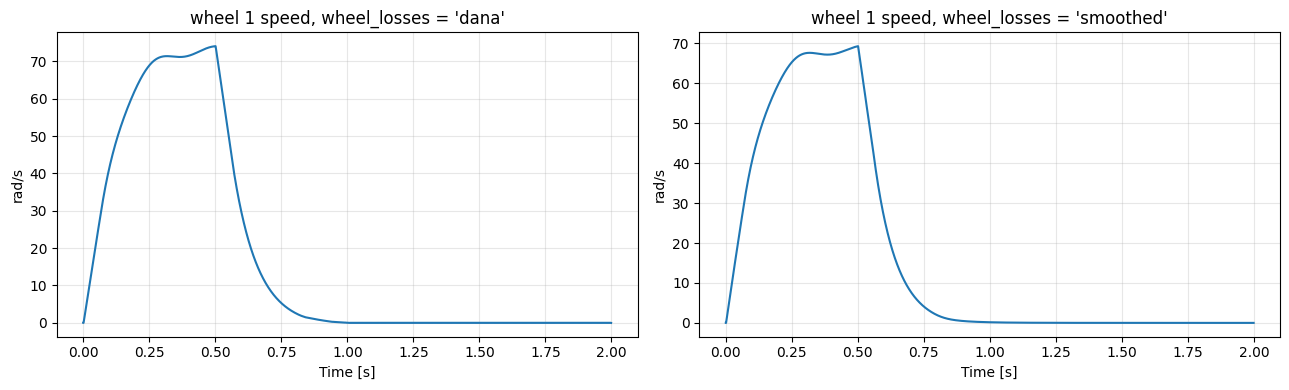

In [16]:
spin_then_coast = lambda t: np.full(4, 2.0) if t < 0.5 else np.zeros(4)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, mode in enumerate(("dana", "smoothed")):
    lg = run_logged(OmniRobotSimulationExtended(dict(p0, wheel_losses=mode)), spin_then_coast, 2.0)
    tail = lg["theta_dot"][lg["t"] > 1.5, 0]
    sign_flips = int(np.sum(np.abs(np.diff(np.sign(tail))) > 0))
    print(f"wheel_losses = {mode!r:11}: yaw rate at 2 s {lg['final_state'].v_local[2]:+.4f} rad/s; "
          f"wheel-1 speed sign flips in the last 0.5 s: {sign_flips}")
    ax[k].plot(lg["t"], lg["theta_dot"][:, 0]); ax[k].set_title(f"wheel 1 speed, wheel_losses = {mode!r}")
    ax[k].set_xlabel("Time [s]"); ax[k].set_ylabel("rad/s"); ax[k].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### D5. Drive friction (`drive_friction`)

The forward/reverse/coast test, where Dana's friction model makes the wheels chatter while braking. `'slip_velocity'` remembers each wheel's slip direction at breakaway and keeps it sliding until the rim slip has come back to zero (or reversed past the band), so it re-sticks with almost no speed jump. `'lugre'` has no stick/slip switch at all; it is sub-stepped (`lugre_dt`), so it runs slower.

drive_friction = 'dana'         : reverse-phase toggles {'FR': np.int64(0), 'FL': np.int64(0), 'RL': np.int64(59), 'RR': np.int64(59)}, largest one-step wheel-speed change 225.4 rad/s, run time 0.8 s


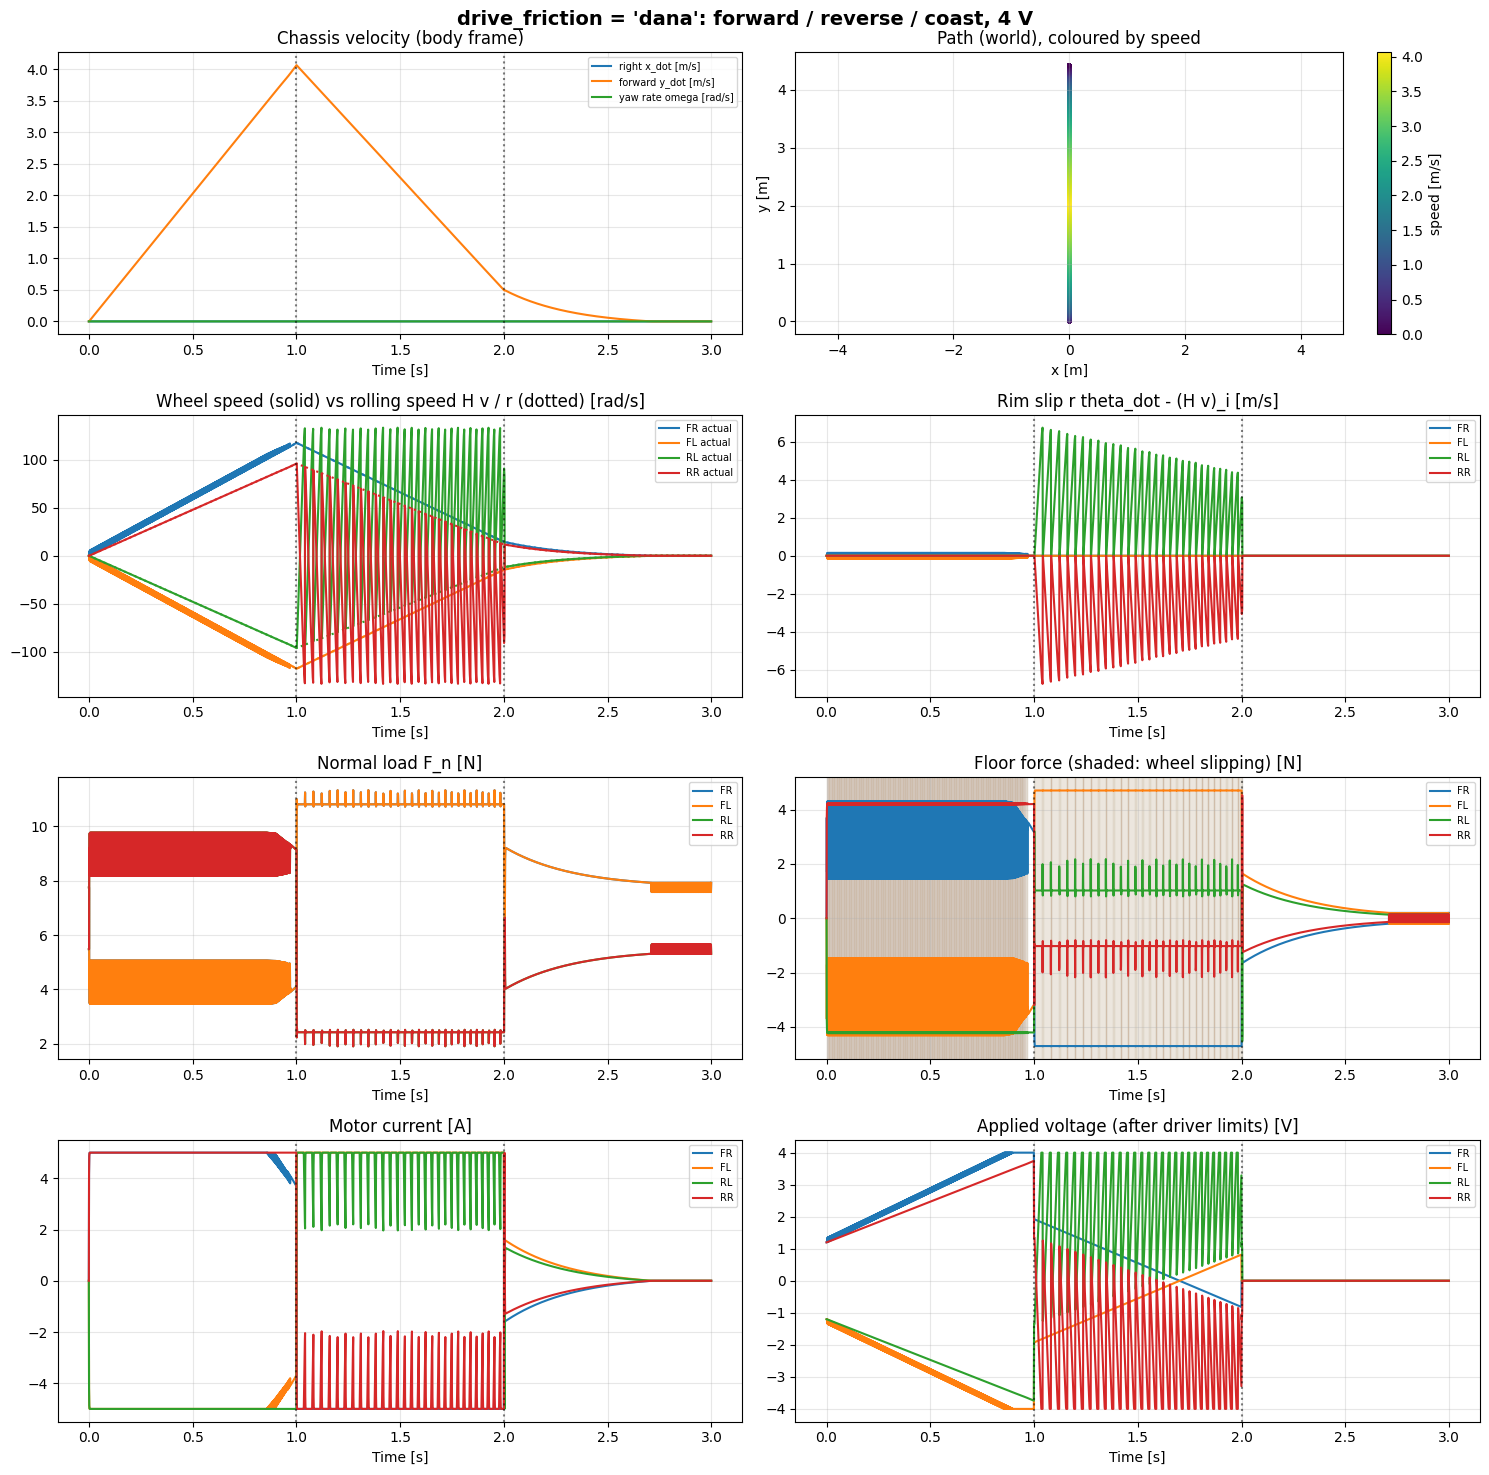

drive_friction = 'slip_velocity': reverse-phase toggles {'FR': np.int64(1), 'FL': np.int64(1), 'RL': np.int64(1), 'RR': np.int64(1)}, largest one-step wheel-speed change 18.5 rad/s, run time 1.0 s


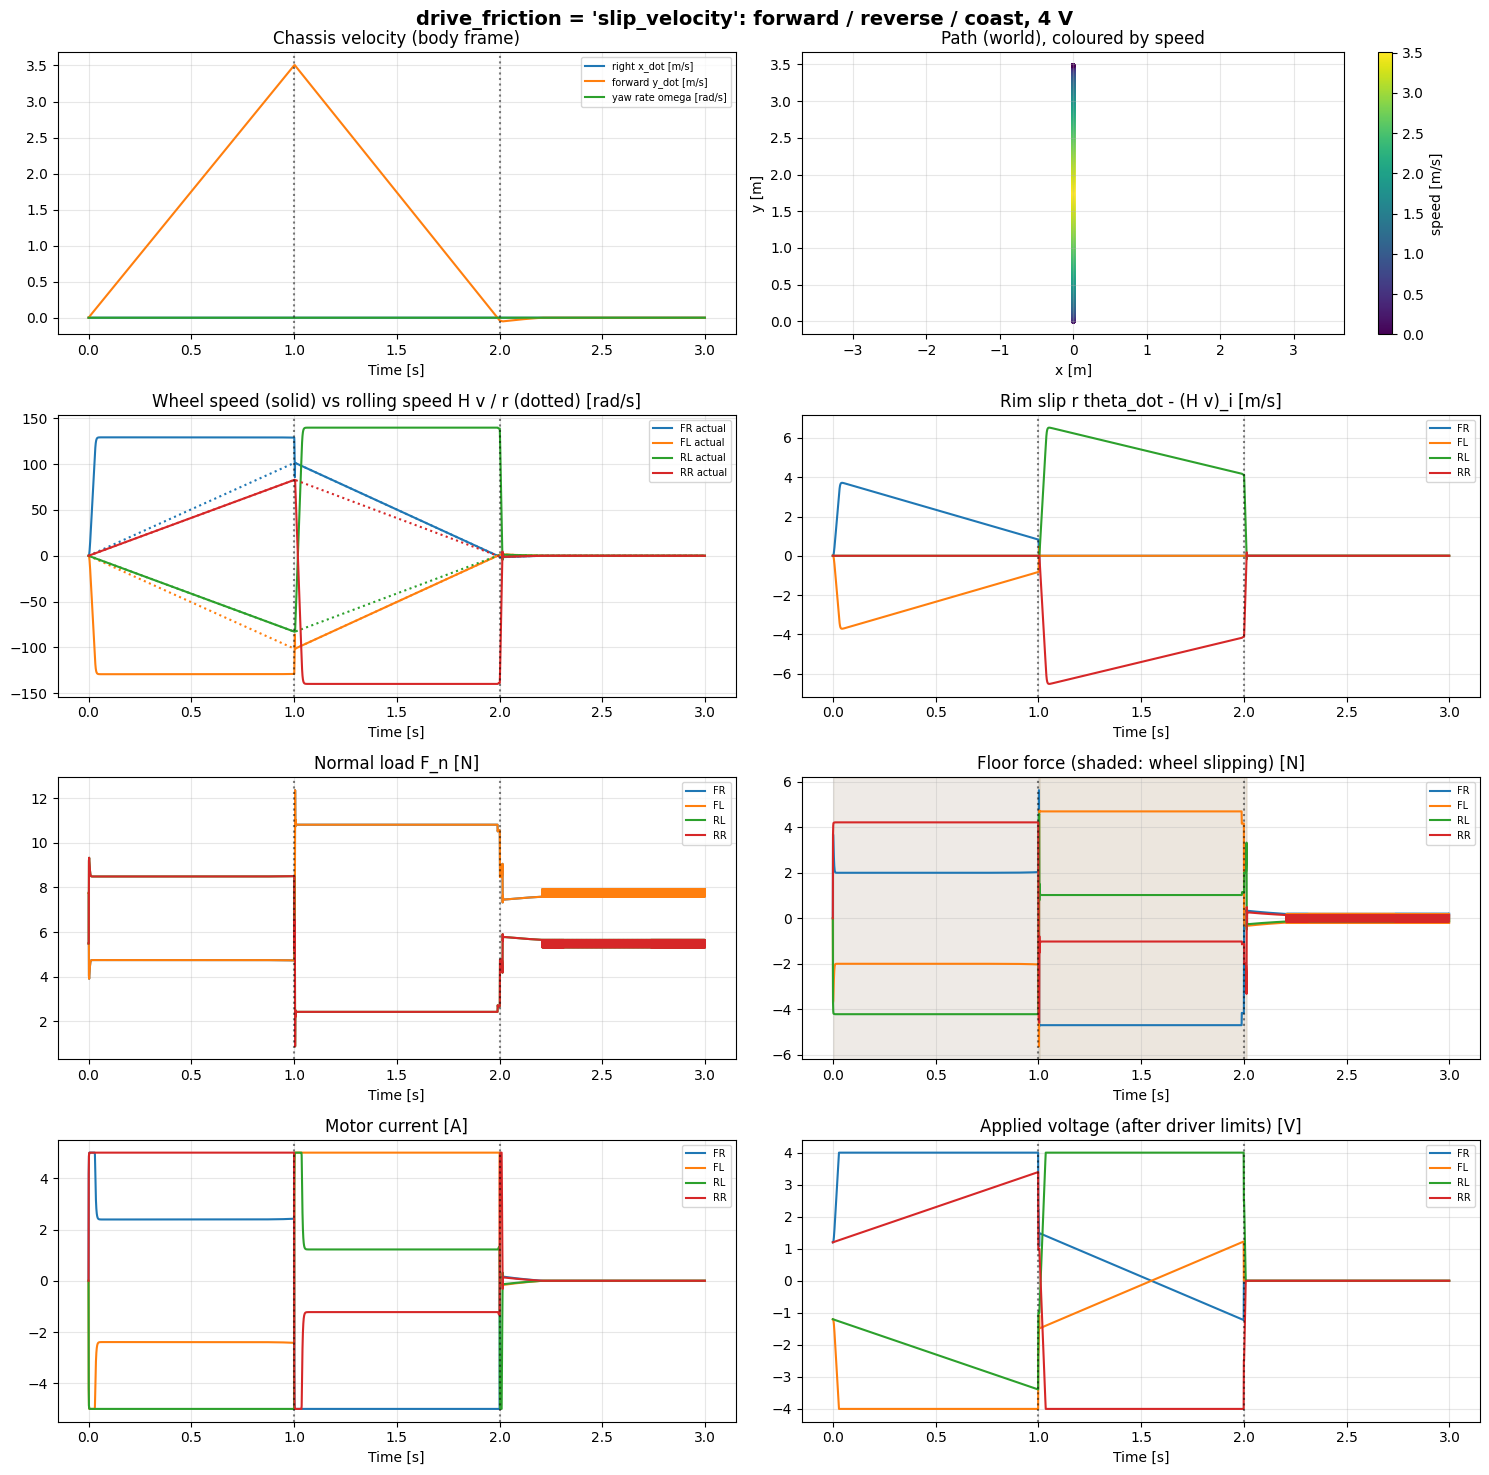

drive_friction = 'lugre'        : reverse-phase toggles {'FR': np.int64(1), 'FL': np.int64(1), 'RL': np.int64(1), 'RR': np.int64(1)}, largest one-step wheel-speed change 14.4 rad/s, run time 23.1 s


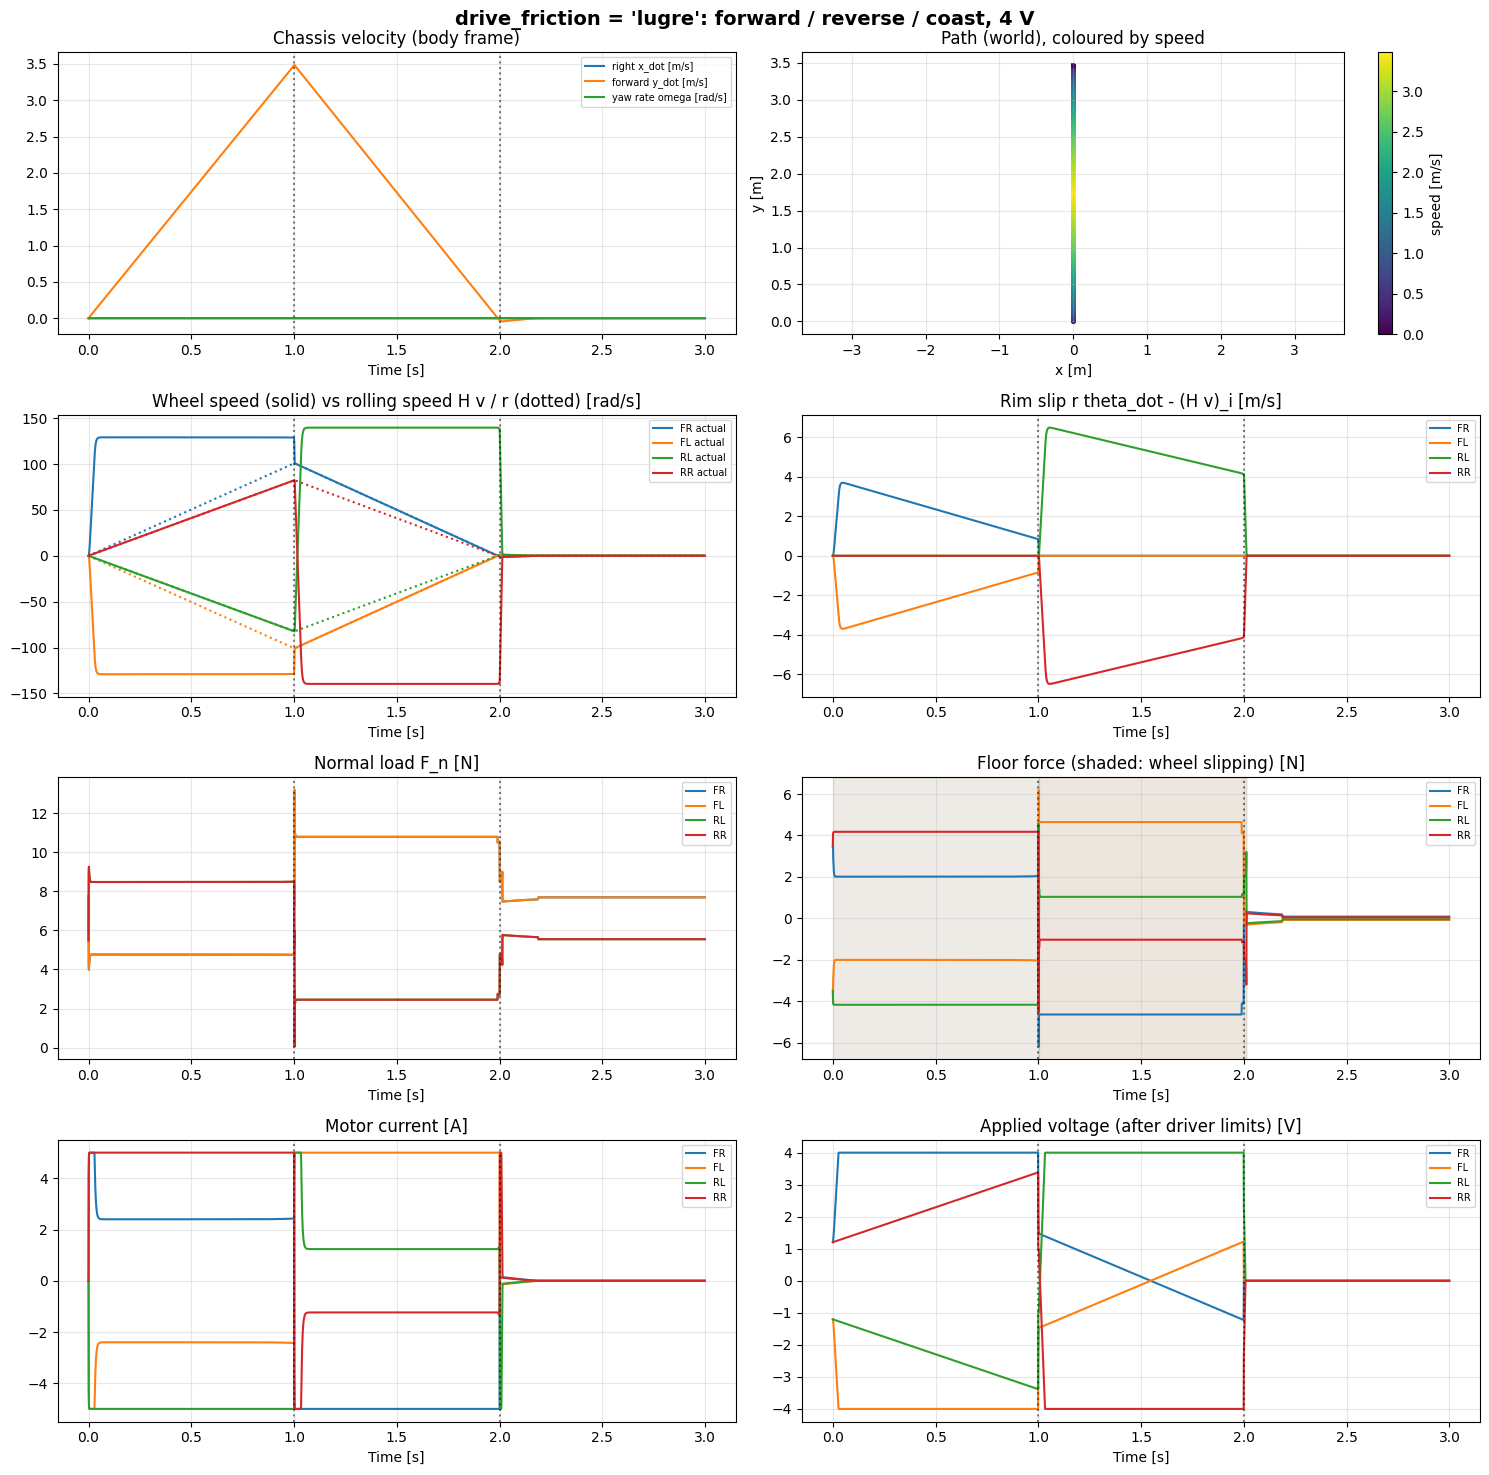

In [17]:
import time
for mode in ("dana", "slip_velocity", "lugre"):
    start = time.time()
    lg = run_logged(OmniRobotSimulationExtended(dict(p0, drive_friction=mode)), forward_reverse_coast, 3.0)
    jumps = np.max(np.abs(np.diff(lg["theta_dot"], axis=0)))
    print(f"drive_friction = {mode!r:15}: reverse-phase toggles {dict(zip(WHEELS, chatter_count(lg)))}, "
          f"largest one-step wheel-speed change {jumps:.1f} rad/s, run time {time.time() - start:.1f} s")
    plot_diagnostics(lg, f"drive_friction = {mode!r}: forward / reverse / coast, 4 V", marks=(1.0, 2.0))

### D6. Disturbance models (`disturbance_model`)

Open-loop forward drift over five seeds, with Dana's white noise against Henry's load vibration and friction offset.

disturbance_model = 'dana': seed 1 end sideways -15.8 mm, heading +0.39 deg, load range 3.07-10.17 N
disturbance_model = 'henry': seed 1 end sideways +1859.8 mm, heading -55.75 deg, load range 2.08-13.03 N


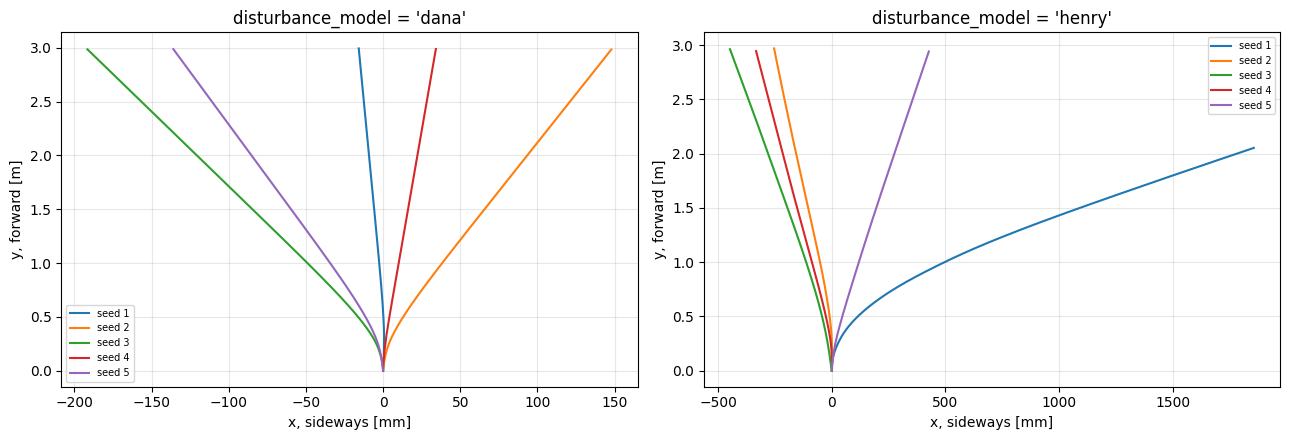

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, mode in enumerate(("dana", "henry")):
    for seed in range(1, 6):
        params = dict(simulation_parameters, disturbance_model=mode)
        lg = run_logged(OmniRobotSimulationExtended(params, random_seed=seed), forward_2v, 1.5)
        ax[k].plot(lg["pos"][:, 0] * 1e3, lg["pos"][:, 1], label=f"seed {seed}")
        if seed == 1:
            print(f"disturbance_model = {mode!r}: seed 1 end sideways {lg['final_state'].pos_global[0] * 1e3:+.1f} mm, "
                  f"heading {np.degrees(lg['final_state'].pos_global[2]):+.2f} deg, load range "
                  f"{lg['F_n'].min():.2f}-{lg['F_n'].max():.2f} N")
    ax[k].set(title=f"disturbance_model = {mode!r}", xlabel="x, sideways [mm]", ylabel="y, forward [m]"); ax[k].grid(True, alpha=0.3)
    ax[k].legend(fontsize=7)
plt.tight_layout(); plt.show()

### D7. Centre-of-gravity offset (`cog_offset`)

CAD puts the CoG 10.2 mm ahead of the base centre. The front pair then carries more of the weight at rest, and a pure forward push no longer acts through the CoG.

In [19]:
for flag in (False, True):
    plant = OmniRobotSimulationExtended(dict(p0, cog_offset=flag))
    loads = plant.compute_dynamic_normal_forces(OmniMotorState())
    lg = run_logged(plant, forward_2v, 1.0)
    print(f"cog_offset = {flag!s:5}: loads at rest {dict(zip(WHEELS, np.round(loads, 3)))} N; forward 2 V for 1 s: heading "
          f"{np.degrees(lg['final_state'].pos_global[2]):+.3f} deg")

cog_offset = False: loads at rest {'FR': np.float64(7.752), 'FL': np.float64(7.752), 'RL': np.float64(5.482), 'RR': np.float64(5.482)} N; forward 2 V for 1 s: heading +0.000 deg
cog_offset = True : loads at rest {'FR': np.float64(9.229), 'FL': np.float64(9.091), 'RL': np.float64(4.018), 'RR': np.float64(4.13)} N; forward 2 V for 1 s: heading -2.586 deg


### D8. Wheel lift-off (`lift_off_resolve`, in the base class)

A hard sideways deceleration that would drive a load negative. Dana's clip sets it to zero but leaves the other three loads unchanged, so the loads no longer add up to the weight. The lift-off re-solve shares the load among the wheels still touching.

In [20]:
st = OmniMotorState(); st.a_local_past = np.array([-6.0, 6.0, 0.0])
for flag in (False, True):
    N = OmniRobotSimulation(dict(p0, lift_off_resolve=flag)).compute_dynamic_normal_forces(st)
    print(f"lift_off_resolve = {flag!s:5}: N = {dict(zip(WHEELS, np.round(N, 3)))} N, sum {N.sum():.3f} N "
          f"(weight {p0['Mr'] * p0['g']:.3f} N)")

lift_off_resolve = False: N = {'FR': np.float64(6.908), 'FL': np.float64(0.0), 'RL': np.float64(7.118), 'RR': np.float64(14.162)} N, sum 28.187 N (weight 26.467 N)
lift_off_resolve = True : N = {'FR': np.float64(5.188), 'FL': np.float64(0.0), 'RL': np.float64(5.011), 'RR': np.float64(16.269)} N, sum 26.467 N (weight 26.467 N)
